In [ ]:
import os
from pathlib import Path
from dotenv import load_dotenv

# Find the project root
project_root = Path.cwd()

if not (project_root / ".env").exists():
    project_root = project_root.parent

# Load the API key securely
load_dotenv(project_root / ".env")

api_key = os.getenv("ANTHROPIC_API_KEY")

print("API key configured:", bool(api_key))

In [ ]:
import sys
print("Notebook Python:", sys.executable)

import anthropic
print("Anthropic SDK imported successfully!")

In [ ]:
import os
from anthropic import Anthropic

client = Anthropic(
    api_key=os.environ["ANTHROPIC_API_KEY"]
)

response = client.messages.create(
    model="claude-haiku-4-5-20251001",
    max_tokens=50,
    messages=[
        {
            "role": "user",
            "content": "Reply with exactly: HealthTrust Watch Phase III connection successful."
        }
    ]
)

print(response.content[0].text)

In [4]:
from pathlib import Path
import pandas as pd

# Locate the project root
cwd = Path.cwd()

if (cwd / "data" / "HARPT.csv").exists():
    project_root = cwd
elif (cwd.parent / "data" / "HARPT.csv").exists():
    project_root = cwd.parent
else:
    raise FileNotFoundError("Cannot locate data/HARPT.csv")

data_path = project_root / "data" / "HARPT.csv"

print("Project root:", project_root)
print("Dataset exists:", data_path.exists())

df = pd.read_csv(data_path, low_memory=False)

print("Original dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

C:\Users\sahit\AppData\Roaming\Python\Python313\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Project root: c:\Users\sahit\OneDrive\Desktop\INFO4360\Project\HealthTrust-Watch
Dataset exists: True
Original dataset shape: (480450, 16)
Columns: ['reviewId', 'content', 'score', 'thumbsUpCount', 'reviewCreatedVersion', 'at', 'replyContent', 'repliedAt', 'app_name', 'app_id', 'word_count', 'year', 'sentiment', 'App_Type', 'trust_dimension', 'confidence_score']


In [5]:
# Step 2: Verify MyChart filtering and review-text quality

print("Application names containing 'MyChart':")
print(
    df.loc[
        df["app_name"].astype(str).str.contains(
            "mychart", case=False, na=False
        ),
        "app_name"
    ].value_counts()
)

# Select the MyChart application
df_mychart = df.loc[
    df["app_name"].astype(str).str.strip().str.casefold() == "mychart"
].copy()

print("\nMyChart subset:", len(df_mychart))

# Check missing or empty review text
missing_text = (
    df_mychart["content"].isna()
    | df_mychart["content"].astype("string").str.strip().eq("").fillna(True)
)

print("Missing/empty review text:", missing_text.sum())

# Remove unusable review text
df_clean = df_mychart.loc[~missing_text].copy()

print("Cleaned MyChart reviews:", len(df_clean))
print("Retained percentage:",
      round(len(df_clean) / len(df_mychart) * 100, 2)
      if len(df_mychart) else 0)

print("\nRating distribution:")
print(df_clean["score"].value_counts(dropna=False).sort_index())

print("\nDate range:")
dates = pd.to_datetime(df_clean["at"], errors="coerce")
print("Earliest:", dates.min())
print("Latest:", dates.max())

Application names containing 'MyChart':
app_name
MyChart       93392
UH MyChart      297
Name: count, dtype: int64

MyChart subset: 93392
Missing/empty review text: 46
Cleaned MyChart reviews: 93346
Retained percentage: 99.95

Rating distribution:
score
1    10856
2     4263
3     4894
4     8415
5    64918
Name: count, dtype: int64

Date range:


C:\Users\sahit\AppData\Local\Temp\ipykernel_7648\2582291704.py:40: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dates = pd.to_datetime(df_clean["at"], errors="coerce")


Earliest: 2011-11-01 14:21:00
Latest: 2025-04-12 01:29:00


In [6]:
# Phase III - Step 3: Data quality validation

print("Total cleaned reviews:", len(df_clean))

print("\nMissing values in important fields:")
fields = [
    "content",
    "score",
    "at",
    "reviewCreatedVersion",
    "reviewId"
]
print(df_clean[fields].isna().sum())

print("\nDuplicate review IDs:")
print(df_clean["reviewId"].duplicated().sum())

print("\nExact duplicate review texts:")
print(df_clean["content"].duplicated().sum())

print("\nInvalid ratings:")
print((~df_clean["score"].isin([1, 2, 3, 4, 5])).sum())

print("\nDate parsing:")
dates = pd.to_datetime(
    df_clean["at"],
    format="mixed",
    errors="coerce"
)
print("Invalid dates:", dates.isna().sum())

print("\nApplication version coverage:")
version_available = (
    df_clean["reviewCreatedVersion"].notna()
    & df_clean["reviewCreatedVersion"]
        .astype("string").str.strip().ne("").fillna(False)
)

print("Reviews with version:", version_available.sum())
print("Reviews without version:", (~version_available).sum())
print("Version coverage (%):",
      round(version_available.mean() * 100, 2))

Total cleaned reviews: 93346

Missing values in important fields:
content                    0
score                      0
at                         0
reviewCreatedVersion    8047
reviewId                   0
dtype: int64

Duplicate review IDs:
0

Exact duplicate review texts:
12654

Invalid ratings:
0

Date parsing:
Invalid dates: 0

Application version coverage:
Reviews with version: 85299
Reviews without version: 8047
Version coverage (%): 91.38


In [7]:
# Phase III - Step 4: Repeated text investigation

text_counts = df_clean["content"].value_counts()

print("Unique review texts:", df_clean["content"].nunique())

print("\nTop 15 most repeated review texts:")
print(text_counts.head(15).to_string())

print("\nReviews with text appearing more than once:")
repeated_mask = df_clean["content"].duplicated(keep=False)

print(repeated_mask.sum())

print("\nRepeated-text review percentage:")
print(round(repeated_mask.mean() * 100, 2), "%")

print("\nExamples of repeated text across ratings:")
examples = (
    df_clean.loc[repeated_mask, ["content", "score", "at"]]
    .groupby("content")
    .filter(lambda group: group["score"].nunique() > 1)
)

print(
    examples[["content", "score", "at"]]
    .head(15)
    .to_string(index=False, max_colwidth=70)
)

Unique review texts: 80692

Top 15 most repeated review texts:
content
Great               812
Love it             663
Good                645
Excellent           497
Easy to use         476
Great app           457
Awesome             314
Very helpful        273
Very good           229
Love this app       209
I love it           163
Very convenient     157
Easy to use.        142
Very easy to use    124
Very useful         101

Reviews with text appearing more than once:
14221

Repeated-text review percentage:
15.23 %

Examples of repeated text across ratings:
      content  score            at
    Great app      5 4/11/25 18:59
           ok      4 4/11/25 16:38
         good      4 4/11/25 13:55
      Awesome      5  4/11/25 9:23
love this app      5  4/11/25 7:59
         good      5  4/11/25 0:46
      Awesome      5 4/10/25 18:24
   Great app!      5  4/10/25 9:37
         good      5  4/10/25 6:55
    Great app      5  4/10/25 6:09
         good      5  4/10/25 6:04
         good

In [8]:
# Phase III - Step 5: Create analysis-specific datasets

# Master dataset: retain all valid MyChart reviews
df_master = df_clean.copy()

# Prepare text for NLP analysis
df_master["review_text"] = (
    df_master["content"].astype("string").str.strip()
)

df_master["token_count"] = (
    df_master["review_text"]
    .str.findall(r"\b\w+\b")
    .str.len()
)

# Informative-text subset for exploratory topic modeling
# Threshold is provisional and will be evaluated
df_nlp = df_master.loc[
    df_master["token_count"] >= 5
].copy()

print("Master dataset:", len(df_master))
print("NLP exploration subset:", len(df_nlp))
print("Short reviews excluded from NLP subset:",
      len(df_master) - len(df_nlp))

print("NLP subset percentage:",
      round(len(df_nlp) / len(df_master) * 100, 2))

print("\nToken count summary:")
print(df_master["token_count"].describe())

print("\nRating distribution comparison (%):")

comparison = pd.DataFrame({
    "Master": df_master["score"].value_counts(normalize=True) * 100,
    "NLP subset": df_nlp["score"].value_counts(normalize=True) * 100
}).sort_index()

print(comparison.round(2))

Master dataset: 93346
NLP exploration subset: 72265
Short reviews excluded from NLP subset: 21081
NLP subset percentage: 77.42

Token count summary:
count    93346.000000
mean        19.134714
std         20.253242
min          0.000000
25%          5.000000
50%         13.000000
75%         25.000000
max        710.000000
Name: token_count, dtype: float64

Rating distribution comparison (%):
       Master  NLP subset
score                    
1       11.63       13.27
2        4.57        5.47
3        5.24        6.20
4        9.01        9.51
5       69.55       65.55


In [9]:
# Phase III - Step 6: Short-review audit

print("Zero-token reviews:",
      (df_master["token_count"] == 0).sum())

print("\nToken count categories:")

df_master["length_group"] = pd.cut(
    df_master["token_count"],
    bins=[-1, 0, 4, 9, 19, 49, float("inf")],
    labels=[
        "0 tokens",
        "1-4 tokens",
        "5-9 tokens",
        "10-19 tokens",
        "20-49 tokens",
        "50+ tokens"
    ]
)

print(
    df_master["length_group"]
    .value_counts()
    .sort_index()
)

print("\nRating distribution by review length (%):")

rating_by_length = pd.crosstab(
    df_master["length_group"],
    df_master["score"],
    normalize="index"
) * 100

print(rating_by_length.round(2))

print("\nExamples of zero-token reviews:")
print(
    df_master.loc[
        df_master["token_count"] == 0,
        ["review_text", "score"]
    ]
    .head(10)
    .to_string(index=False)
)

Zero-token reviews: 185

Token count categories:
length_group
0 tokens          185
1-4 tokens      20896
5-9 tokens      17062
10-19 tokens    23491
20-49 tokens    23799
50+ tokens       7913
Name: count, dtype: int64

Rating distribution by review length (%):
score             1      2      3      4      5
length_group                                   
0 tokens       2.16   0.00   1.08   8.11  88.65
1-4 tokens     6.03   1.49   1.98   7.31  83.19
5-9 tokens    10.44   3.24   3.98   8.17  74.17
10-19 tokens  11.06   4.01   4.86   8.71  71.35
20-49 tokens  14.84   6.84   7.44  10.19  60.70
50+ tokens    21.23  10.48  11.21  12.74  44.34

Examples of zero-token reviews:
review_text  score
          👍      5
       👍🏼👌🏼      5
          🥰      5
         ❤️      5
      ⭐⭐⭐⭐⭐      5
          😁      5
          👍      5
 ⭐️⭐️⭐️⭐️⭐️      5
          👍      5
          😆      5


HealthTrust-Watch: Provisional Concern Taxonomy
Six categories for classical NLP and Claude-assisted issue extraction

1. Technical reliability

Crashes, freezes, loading failures, login errors caused by software faults, bugs, and broken app features.

2. Medical-record and account access

Difficulty accessing test results, appointments, health records, account credentials, or patient information.

3. Usability and accessibility

Confusing navigation, complicated workflows, poor interface design, readability problems, and accessibility barriers.

4. Customer support

Inadequate assistance, unresolved support requests, unhelpful responses, and difficulty contacting support.

5. Data accuracy and synchronization

Incorrect or outdated medical information, missing updates, inconsistent records, and synchronization problems.

6. Privacy and data control

Concerns about personal health information, data sharing, consent, permissions, security, and user control over data.

In [10]:
# Phase III - Step 8: Create balanced validation sample

import pandas as pd

validation_sample = (
    df_master.groupby("score", group_keys=False)
    .sample(n=24, random_state=4360)
    .copy()
)

validation_sample = validation_sample[
    ["reviewId", "review_text", "score", "at", "token_count"]
].reset_index(drop=True)

# Shuffle so ratings are mixed
validation_sample = validation_sample.sample(
    frac=1,
    random_state=4360
).reset_index(drop=True)

print("Validation sample shape:", validation_sample.shape)

print("\nRating distribution:")
print(validation_sample["score"].value_counts().sort_index())

print("\nReview length distribution:")
print(
    pd.cut(
        validation_sample["token_count"],
        bins=[-1, 0, 4, 9, 19, 49, float("inf")]
    ).value_counts().sort_index()
)

print("\nFirst five sample rows:")
print(validation_sample.head().to_string(index=False))

Validation sample shape: (120, 5)

Rating distribution:
score
1    24
2    24
3    24
4    24
5    24
Name: count, dtype: int64

Review length distribution:
token_count
(-1.0, 0.0]      0
(0.0, 4.0]      18
(4.0, 9.0]      16
(9.0, 19.0]     30
(19.0, 49.0]    44
(49.0, inf]     12
Name: count, dtype: int64

First five sample rows:
                            reviewId                                                                                                                                                                                                                                                                                                                                                                                 review_text  score             at  token_count
98fda16f-e198-4bde-814e-31588cc2e926                                                                                                                                                                                  

In [11]:
# Phase III - Step 9A: Human annotation templates

from pathlib import Path
import pandas as pd

annotation_dir = project_root / "data" / "annotations"
annotation_dir.mkdir(parents=True, exist_ok=True)

# Keep stable review numbers for assignment
sample = validation_sample.copy()
sample.insert(0, "sample_id", range(1, len(sample) + 1))

labels = [
    "technical_reliability",
    "medical_record_access",
    "usability_accessibility",
    "customer_support",
    "data_accuracy_sync",
    "privacy_data_control"
]

def make_template(subset, annotator):
    template = subset[
        ["sample_id", "reviewId", "review_text", "score"]
    ].copy()

    for label in labels:
        template[label] = ""

    template["annotator"] = annotator
    template["notes"] = ""

    return template

sahithi_ids = list(range(1, 71))
bhargava_ids = list(range(1, 21)) + list(range(71, 121))

sahithi_template = make_template(
    sample[sample["sample_id"].isin(sahithi_ids)],
    "Sahithi"
)

bhargava_template = make_template(
    sample[sample["sample_id"].isin(bhargava_ids)],
    "Bhargava"
)

sahithi_path = annotation_dir / "sahithi_annotations.csv"
bhargava_path = annotation_dir / "bhargava_annotations.csv"

sahithi_template.to_csv(sahithi_path, index=False)
bhargava_template.to_csv(bhargava_path, index=False)

print("Sahithi assigned:", len(sahithi_template))
print("Bhargava assigned:", len(bhargava_template))

shared = set(sahithi_template["sample_id"]) & set(
    bhargava_template["sample_id"]
)

print("Shared reviews:", len(shared))
print("Unique reviews covered:",
      len(set(sahithi_template["sample_id"]) |
          set(bhargava_template["sample_id"])))

print("\nTemplates saved locally:")
print(sahithi_path)
print(bhargava_path)

Sahithi assigned: 70
Bhargava assigned: 70
Shared reviews: 20
Unique reviews covered: 120

Templates saved locally:
c:\Users\sahit\OneDrive\Desktop\INFO4360\Project\HealthTrust-Watch\data\annotations\sahithi_annotations.csv
c:\Users\sahit\OneDrive\Desktop\INFO4360\Project\HealthTrust-Watch\data\annotations\bhargava_annotations.csv


In [12]:
from pathlib import Path
import pandas as pd

annotation_dir = project_root / "data" / "annotations"

sahithi_file = annotation_dir / "sahithi_annotations.csv"
bhargava_file = annotation_dir / "bhargava_annotations.csv"

print("Sahithi file exists:", sahithi_file.exists())
print("Bhargava file exists:", bhargava_file.exists())

if sahithi_file.exists() and bhargava_file.exists():
    sahithi_check = pd.read_csv(sahithi_file)
    bhargava_check = pd.read_csv(bhargava_file)

    print("\nSahithi assigned:", len(sahithi_check))
    print("Bhargava assigned:", len(bhargava_check))

    shared_ids = (
        set(sahithi_check["sample_id"])
        & set(bhargava_check["sample_id"])
    )

    print("Shared reviews:", len(shared_ids))
    print("Unique reviews covered:", len(
        set(sahithi_check["sample_id"])
        | set(bhargava_check["sample_id"])
    ))

Sahithi file exists: True
Bhargava file exists: True

Sahithi assigned: 70
Bhargava assigned: 70
Shared reviews: 20
Unique reviews covered: 120


In [13]:
import pandas as pd

sahithi_check = pd.read_csv(
    annotation_dir / "sahithi_annotations.csv"
)

first_10 = sahithi_check[
    sahithi_check["sample_id"].between(1, 10)
]

print("Reviews checked:", len(first_10))

print("\nMissing labels:")
print(first_10[labels].isna().sum())

print("\nInvalid labels:")
print(
    (~first_10[labels].isin([0, 1])).sum()
)

Reviews checked: 10

Missing labels:
technical_reliability      0
medical_record_access      0
usability_accessibility    0
customer_support           0
data_accuracy_sync         0
privacy_data_control       0
dtype: int64

Invalid labels:
technical_reliability      0
medical_record_access      0
usability_accessibility    0
customer_support           0
data_accuracy_sync         0
privacy_data_control       0
dtype: int64


In [29]:
import pandas as pd

file_path = (
    project_root
    / "data"
    / "annotations"
    / "sahithi_annotations.csv"
)

# Read using a permissive single-byte encoding
df_sahithi = pd.read_csv(
    file_path,
    encoding="latin1",
    engine="python"
)

print("CSV loaded successfully!")
print("Total reviews:", len(df_sahithi))
print("Columns:", df_sahithi.columns.tolist())

CSV loaded successfully!
Total reviews: 70
Columns: ['sample_id', 'reviewId', 'review_text', 'score', 'technical_reliability', 'medical_record_access', 'usability_accessibility', 'customer_support', 'data_accuracy_sync', 'privacy_data_control', 'annotator', 'notes']


In [30]:
label_columns = [
    "technical_reliability",
    "medical_record_access",
    "usability_accessibility",
    "customer_support",
    "data_accuracy_sync",
    "privacy_data_control"
]

print("Total reviews:", len(df_sahithi))

print("\nMissing labels:")
print(df_sahithi[label_columns].isna().sum())

print("\nInvalid labels:")
print((~df_sahithi[label_columns].isin([0, 1])).sum())

print("\nDuplicate sample IDs:")
print(df_sahithi["sample_id"].duplicated().sum())

print("\nConcern counts:")
print(df_sahithi[label_columns].sum())

Total reviews: 70

Missing labels:
technical_reliability      0
medical_record_access      0
usability_accessibility    0
customer_support           0
data_accuracy_sync         0
privacy_data_control       0
dtype: int64

Invalid labels:
technical_reliability      0
medical_record_access      0
usability_accessibility    0
customer_support           0
data_accuracy_sync         0
privacy_data_control       0
dtype: int64

Duplicate sample IDs:
0

Concern counts:
technical_reliability      17
medical_record_access       6
usability_accessibility    24
customer_support            2
data_accuracy_sync          4
privacy_data_control        0
dtype: int64


In [31]:
label_columns = [
    "technical_reliability",
    "medical_record_access",
    "usability_accessibility",
    "customer_support",
    "data_accuracy_sync",
    "privacy_data_control"
]

print("Total reviews:", len(df_sahithi))

print("\nMissing labels:")
print(df_sahithi[label_columns].isna().sum())

print("\nInvalid labels:")
print((~df_sahithi[label_columns].isin([0, 1])).sum())

print("\nDuplicate sample IDs:")
print(df_sahithi["sample_id"].duplicated().sum())

print("\nConcern counts:")
print(df_sahithi[label_columns].sum())

Total reviews: 70

Missing labels:
technical_reliability      0
medical_record_access      0
usability_accessibility    0
customer_support           0
data_accuracy_sync         0
privacy_data_control       0
dtype: int64

Invalid labels:
technical_reliability      0
medical_record_access      0
usability_accessibility    0
customer_support           0
data_accuracy_sync         0
privacy_data_control       0
dtype: int64

Duplicate sample IDs:
0

Concern counts:
technical_reliability      17
medical_record_access       6
usability_accessibility    24
customer_support            2
data_accuracy_sync          4
privacy_data_control        0
dtype: int64


In [32]:
print("Potential encoding artifacts:")
print(
    df_sahithi["review_text"]
    .astype(str)
    .str.contains("Ã|Â|â€|ðŸ", regex=True)
    .sum()
)

Potential encoding artifacts:
0


In [33]:
# Check annotation quality without modifying the CSV

df_quality = df_sahithi.drop(
    columns=["review_text"], errors="ignore"
).merge(
    df_master[["reviewId", "review_text"]]
        .drop_duplicates("reviewId"),
    on="reviewId",
    how="left",
    validate="one_to_one"
)

df_quality["concern_count"] = (
    df_quality[label_columns].eq(1).sum(axis=1)
)

flagged = df_quality[
    ((df_quality["score"] <= 2) &
     (df_quality["concern_count"] == 0))
    |
    ((df_quality["score"] >= 4) &
     (df_quality["concern_count"] >= 2))
    |
    (df_quality["concern_count"] >= 3)
]

print("Original texts recovered:",
      df_quality["review_text"].notna().sum())

print("Reviews with no identified concerns:",
      (df_quality["concern_count"] == 0).sum())

print("Reviews with 3+ concerns:",
      (df_quality["concern_count"] >= 3).sum())

print("Reviews flagged for manual review:", len(flagged))

print("\nFlagged sample IDs:")
print(flagged["sample_id"].tolist())

Original texts recovered: 70
Reviews with no identified concerns: 35
Reviews with 3+ concerns: 4
Reviews flagged for manual review: 11

Flagged sample IDs:
[3, 5, 6, 9, 17, 26, 34, 41, 59, 65, 66]


In [34]:
# Step 4: Display flagged reviews and assigned labels

from IPython.display import display

review_columns = [
    "sample_id",
    "score",
    "review_text",
    "technical_reliability",
    "medical_record_access",
    "usability_accessibility",
    "customer_support",
    "data_accuracy_sync",
    "privacy_data_control",
    "concern_count"
]

display(
    flagged[review_columns]
    .sort_values("sample_id")
    .style.set_properties(
        subset=["review_text"],
        **{"white-space": "pre-wrap"}
    )
)

,sample_id,score,review_text,technical_reliability,medical_record_access,usability_accessibility,customer_support,data_accuracy_sync,privacy_data_control,concern_count
2,3,3,Too cluttered with non pertinent info. Does not seem to send alerts to doctor that info is missing making it a poor source of info.,1,0,1,0,1,0,3
4,5,3,"Not really thrilled with it. I like it to check on test results, or to contact doctors office. Wish it could be used to make appointments. I don't like getting bills and not always knowing what they are for. Sometimes, I get bill notices. But when I login it says I owe nothing.",1,1,0,0,1,0,3
5,6,2,Designer must be a toddler. Terrible app. Lacking in so many ways. Embarrassing actually.,0,0,0,0,0,0,0
8,9,4,"it is a fantastic app I wish all my patient portals went through MyChart, but I would like to see some changes 1.messages I would like to swipe left or right to go from one message to the other also on test results I would like to be able to copy and paste into Google so that I could find out the layman's version of what the medical people are talking about. I would like a dark theme",0,1,1,0,0,0,2
16,17,1,stupid.my medical system which is one of the bigger ones in this area is not even listed so I can't get into it,0,0,0,0,0,0,0
25,26,1,Constantly getting error messages. It takes many attempts to get messages and test results to load. It's very frustrating,1,1,1,0,0,0,3
33,34,1,App is horribly buggy. Epic failure.,0,0,0,0,0,0,0
40,41,2,"I can't believe that they send an earlier appointment notification at 8:38pm, I was sleeping!! Why send out at night!, we don't even get a chance to respond!",0,0,0,0,0,0,0
58,59,1,I waited 90 minutes and never was called in to see a doctor. I left.,0,0,0,0,0,0,0
64,65,3,Incomplete contact list. Cannot find the physician or other staff members on the contract list when I hit the create message button. I'm forced to go back to old messages to make contact to certain physicians and staffs.,1,1,1,0,0,0,3


In [35]:
import pandas as pd

# Reload the updated CSV from disk
df_sahithi = pd.read_csv(
    project_root / "data" / "annotations" / "sahithi_annotations.csv",
    encoding="latin1"
)

label_columns = [
    "technical_reliability",
    "medical_record_access",
    "usability_accessibility",
    "customer_support",
    "data_accuracy_sync",
    "privacy_data_control"
]

print("Total reviews:", len(df_sahithi))
print("Unique sample IDs:", df_sahithi["sample_id"].nunique())
print("Duplicate sample IDs:", df_sahithi["sample_id"].duplicated().sum())

print("\nMissing labels:")
print(df_sahithi[label_columns].isna().sum())

print("\nInvalid labels:")
print((~df_sahithi[label_columns].isin([0, 1])).sum())

print("\nUpdated concern counts:")
print(df_sahithi[label_columns].sum())

Total reviews: 70
Unique sample IDs: 70
Duplicate sample IDs: 0

Missing labels:
technical_reliability      0
medical_record_access      0
usability_accessibility    0
customer_support           0
data_accuracy_sync         0
privacy_data_control       0
dtype: int64

Invalid labels:
technical_reliability      0
medical_record_access      0
usability_accessibility    0
customer_support           0
data_accuracy_sync         0
privacy_data_control       0
dtype: int64

Updated concern counts:
technical_reliability      15
medical_record_access       5
usability_accessibility    23
customer_support            2
data_accuracy_sync          4
privacy_data_control        0
dtype: int64


In [36]:
expected = {
    3:  [0, 0, 1, 0, 1, 0],
    5:  [0, 0, 0, 0, 1, 0],
    6:  [0, 0, 0, 0, 0, 0],
    9:  [0, 0, 1, 0, 0, 0],
    17: [0, 1, 0, 0, 0, 0],
    26: [1, 1, 0, 0, 0, 0],
    34: [1, 0, 0, 0, 0, 0],
    41: [0, 0, 0, 0, 0, 0],
    59: [0, 0, 0, 0, 0, 0],
    65: [0, 0, 1, 0, 0, 0],
    66: [0, 1, 0, 0, 0, 0]
}

mismatches = []

for sample_id, expected_labels in expected.items():
    row = df_sahithi.loc[
        df_sahithi["sample_id"] == sample_id,
        label_columns
    ]

    if len(row) != 1:
        mismatches.append((sample_id, "Missing or duplicate sample"))
        continue

    actual_labels = row.iloc[0].astype(int).tolist()

    if actual_labels != expected_labels:
        mismatches.append({
            "sample_id": sample_id,
            "actual": actual_labels,
            "expected": expected_labels
        })

print("Reviewed samples checked:", len(expected))
print("Mismatches found:", len(mismatches))

for mismatch in mismatches:
    print(mismatch)

Reviewed samples checked: 11
Mismatches found: 0


In [37]:
# Randomly select 10 reviews we have not manually reviewed

reviewed_ids = [3, 5, 6, 9, 17, 26, 34, 41, 59, 65, 66]

spot_check = (
    df_sahithi[
        ~df_sahithi["sample_id"].isin(reviewed_ids)
    ]
    .sample(n=10, random_state=4360)
)

# Restore original review text to avoid encoding issues
spot_check = spot_check.drop(
    columns=["review_text"], errors="ignore"
).merge(
    df_master[["reviewId", "review_text"]]
        .drop_duplicates("reviewId"),
    on="reviewId",
    how="left",
    validate="one_to_one"
)

from IPython.display import display

display(
    spot_check[
        ["sample_id", "score", "review_text"] + label_columns
    ].sort_values("sample_id")
)

,sample_id,score,review_text,technical_reliability,medical_record_access,usability_accessibility,customer_support,data_accuracy_sync,privacy_data_control
6,4,4,Like the all in one factor,0,0,0,0,0,0
0,7,2,Does not do any updates,1,0,0,0,0,0
5,8,3,"I agreed to pay 50 dollars a month,then it sai...",0,0,0,0,0,0
7,15,4,I love the ability to quickly get send and rec...,0,0,0,0,0,0
8,18,5,It's so convenient to interact with my primary...,0,0,0,0,0,0
3,35,4,Yes yes this site seem to work fine,0,0,0,0,0,0
2,37,2,"Basically, you can't be sure what you will get...",1,0,1,0,0,0
1,55,2,"Other than moving my scheduled appointment, it...",0,0,0,0,1,0
9,64,4,Most of the time I get an error message that t...,1,0,0,0,0,0
4,69,2,Not a fan. Tasks assigned that I don't have th...,0,0,1,0,0,0


In [38]:
review_ids_to_check = [7, 8, 37, 55, 69]

for _, row in spot_check[
    spot_check["sample_id"].isin(review_ids_to_check)
].sort_values("sample_id").iterrows():

    print("=" * 65)
    print("SAMPLE ID:", row["sample_id"])
    print("RATING:", row["score"])
    print("REVIEW:", row["review_text"])

    print("ASSIGNED LABELS:")
    for col in label_columns:
        print(f"  {col}: {int(row[col])}")

    print()

SAMPLE ID: 7
RATING: 2
REVIEW: Does not do any updates
ASSIGNED LABELS:
  technical_reliability: 1
  medical_record_access: 0
  usability_accessibility: 0
  customer_support: 0
  data_accuracy_sync: 0
  privacy_data_control: 0

SAMPLE ID: 8
RATING: 3
REVIEW: I agreed to pay 50 dollars a month,then it said it would be taking 379 dollars a month out. Not doable at all. We are on social security and can't afford more than 50 monthly.
ASSIGNED LABELS:
  technical_reliability: 0
  medical_record_access: 0
  usability_accessibility: 0
  customer_support: 0
  data_accuracy_sync: 0
  privacy_data_control: 0

SAMPLE ID: 37
RATING: 2
REVIEW: Basically, you can't be sure what you will get. Fir example, I sign in to OrthoCarolina, check appointments, and I see an upcoming Novant Health sppt. But an appt I made an hr. ago with Ortho doesn't appear. It's always something different ... the same thing just happened on Atrium MyChart: both the Novant appt and an Atrium lab appt (nothing for Ortho) I ha

In [40]:
df_sahithi = pd.read_csv(
    project_root / "data" / "annotations" / "sahithi_annotations.csv",
    encoding="latin1"
)

expected_final = {
    7:  [0, 0, 0, 0, 0, 0],
    8:  [0, 0, 0, 0, 1, 0],
    37: [0, 0, 0, 0, 1, 0]
}

for sample_id, expected_labels in expected_final.items():
    actual = df_sahithi.loc[
        df_sahithi["sample_id"] == sample_id,
        label_columns
    ].iloc[0].astype(int).tolist()

    print(
        f"Sample {sample_id}:",
        "PASS" if actual == expected_labels else "CHECK"
    )

print("\nTotal reviews:", len(df_sahithi))
print("Missing labels:", df_sahithi[label_columns].isna().sum().sum())
print("Invalid labels:", (~df_sahithi[label_columns].isin([0, 1])).sum().sum())

Sample 7: PASS
Sample 8: PASS
Sample 37: PASS

Total reviews: 70
Missing labels: 0
Invalid labels: 0


In [41]:
import pandas as pd

# Load Bhargava's completed annotations
df_bhargava = pd.read_csv(
    project_root / "data" / "annotations" / "bhargava_annotations.csv",
    encoding="latin1"
)

label_columns = [
    "technical_reliability",
    "medical_record_access",
    "usability_accessibility",
    "customer_support",
    "data_accuracy_sync",
    "privacy_data_control"
]

print("Total reviews:", len(df_bhargava))
print("Unique sample IDs:", df_bhargava["sample_id"].nunique())
print("Duplicate sample IDs:", df_bhargava["sample_id"].duplicated().sum())

print("\nMissing labels:")
print(df_bhargava[label_columns].isna().sum())

print("\nInvalid labels:")
print((~df_bhargava[label_columns].isin([0, 1])).sum())

print("\nConcern counts:")
print(df_bhargava[label_columns].sum())

print("\nSample IDs:")
print(sorted(df_bhargava["sample_id"].tolist()))

Total reviews: 70
Unique sample IDs: 70
Duplicate sample IDs: 0

Missing labels:
technical_reliability      0
medical_record_access      0
usability_accessibility    0
customer_support           0
data_accuracy_sync         0
privacy_data_control       0
dtype: int64

Invalid labels:
technical_reliability      0
medical_record_access      0
usability_accessibility    0
customer_support           0
data_accuracy_sync         0
privacy_data_control       0
dtype: int64

Concern counts:
technical_reliability      11
medical_record_access       8
usability_accessibility    11
customer_support            2
data_accuracy_sync         11
privacy_data_control        0
dtype: int64

Sample IDs:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120]


In [42]:
import pandas as pd
from sklearn.metrics import cohen_kappa_score

shared = df_sahithi[
    df_sahithi["sample_id"].between(1, 20)
][["sample_id", "reviewId"] + label_columns].merge(
    df_bhargava[
        df_bhargava["sample_id"].between(1, 20)
    ][["sample_id", "reviewId"] + label_columns],
    on=["sample_id", "reviewId"],
    suffixes=("_sahithi", "_bhargava"),
    validate="one_to_one"
)

print("Shared reviews matched:", len(shared))

if len(shared) != 20:
    raise ValueError("Expected exactly 20 shared reviews.")

results = []

for category in label_columns:
    s = shared[f"{category}_sahithi"]
    b = shared[f"{category}_bhargava"]

    agreement = (s == b).mean() * 100
    kappa = cohen_kappa_score(s, b)

    results.append({
        "Category": category,
        "Agreement (%)": round(agreement, 2),
        "Cohen's Kappa": round(kappa, 3)
    })

agreement_df = pd.DataFrame(results)

display(agreement_df)

print(
    "\nOverall label agreement:",
    round(
        sum(
            (shared[f"{c}_sahithi"] ==
             shared[f"{c}_bhargava"]).sum()
            for c in label_columns
        ) / (20 * len(label_columns)) * 100,
        2
    ),
    "%"
)

print(
    "Reviews with all six labels matching:",
    sum(
        all(
            row[f"{c}_sahithi"] == row[f"{c}_bhargava"]
            for c in label_columns
        )
        for _, row in shared.iterrows()
    )
)

Shared reviews matched: 20


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:534: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:897: RuntimeWarning: invalid value encountered in scalar divide
  k = np.sum(w_mat * confusion) / np.sum(w_mat * expected)


,Category,Agreement (%),Cohen's Kappa
0,technical_reliability,85.0,0.348
1,medical_record_access,95.0,0.643
2,usability_accessibility,70.0,0.318
3,customer_support,95.0,0.000
4,data_accuracy_sync,95.0,0.828
5,privacy_data_control,100.0,NaN



Overall label agreement: 90.0 %
Reviews with all six labels matching: 11


In [43]:
# Bhargava quality audit — same approach as Sahithi

df_bhargava_quality = (
    df_bhargava
    .drop(columns=["review_text"], errors="ignore")
    .merge(
        df_master[["reviewId", "review_text"]]
        .drop_duplicates("reviewId"),
        on="reviewId",
        how="left",
        validate="one_to_one"
    )
)

df_bhargava_quality["concern_count"] = (
    df_bhargava_quality[label_columns]
    .eq(1)
    .sum(axis=1)
)

bhargava_flagged = df_bhargava_quality[
    (
        (df_bhargava_quality["score"] <= 2)
        & (df_bhargava_quality["concern_count"] == 0)
    )
    |
    (
        (df_bhargava_quality["score"] >= 4)
        & (df_bhargava_quality["concern_count"] >= 2)
    )
    |
    (df_bhargava_quality["concern_count"] >= 3)
]

print("Original texts recovered:",
      df_bhargava_quality["review_text"].notna().sum())

print("Reviews with no concerns:",
      (df_bhargava_quality["concern_count"] == 0).sum())

print("Reviews with 3+ concerns:",
      (df_bhargava_quality["concern_count"] >= 3).sum())

print("Reviews flagged for manual review:",
      len(bhargava_flagged))

print("\nFlagged sample IDs:")
print(bhargava_flagged["sample_id"].tolist())

Original texts recovered: 70
Reviews with no concerns: 32
Reviews with 3+ concerns: 0
Reviews flagged for manual review: 7

Flagged sample IDs:
[6, 11, 17, 79, 91, 95, 119]


In [44]:
# Display all 7 flagged reviews with their labels

for _, row in bhargava_flagged.sort_values("sample_id").iterrows():

    print("=" * 65)
    print("SAMPLE ID:", row["sample_id"])
    print("RATING:", row["score"])
    print("REVIEW:", row["review_text"])

    print("\nASSIGNED LABELS:")
    for col in label_columns:
        print(f"  {col}: {int(row[col])}")

    print()

SAMPLE ID: 6
RATING: 2
REVIEW: Designer must be a toddler. Terrible app. Lacking in so many ways. Embarrassing actually.

ASSIGNED LABELS:
  technical_reliability: 0
  medical_record_access: 0
  usability_accessibility: 0
  customer_support: 0
  data_accuracy_sync: 0
  privacy_data_control: 0

SAMPLE ID: 11
RATING: 1
REVIEW: I was typing a big question to doctor and while referring document in-between screen went off and along with that typed (unsent) message also vanished. Can't find any draft or other option to recover the message. Infact I didn't even move out or switch the app. Waste of time and disappointing.

ASSIGNED LABELS:
  technical_reliability: 0
  medical_record_access: 0
  usability_accessibility: 0
  customer_support: 0
  data_accuracy_sync: 0
  privacy_data_control: 0

SAMPLE ID: 17
RATING: 1
REVIEW: stupid.my medical system which is one of the bigger ones in this area is not even listed so I can't get into it

ASSIGNED LABELS:
  technical_reliability: 0
  medical_recor

In [45]:
# Reload corrected annotations
df_bhargava = pd.read_csv(
    project_root / "data" / "annotations" / "bhargava_annotations.csv",
    encoding="latin1"
)

expected = {
    11:  [1, 0, 0, 0, 0, 0],
    17:  [0, 1, 0, 0, 0, 0],
    79:  [1, 1, 0, 0, 0, 0],
    119: [1, 0, 1, 0, 0, 0]
}

for sample_id, expected_labels in expected.items():

    actual = df_bhargava.loc[
        df_bhargava["sample_id"] == sample_id,
        label_columns
    ].iloc[0].astype(int).tolist()

    print(
        f"Sample {sample_id}:",
        "PASS" if actual == expected_labels else "CHECK"
    )

print("\nTotal reviews:", len(df_bhargava))
print("Missing labels:", df_bhargava[label_columns].isna().sum().sum())
print("Invalid labels:", (~df_bhargava[label_columns].isin([0, 1])).sum().sum())

Sample 11: PASS
Sample 17: PASS
Sample 79: PASS
Sample 119: PASS

Total reviews: 70
Missing labels: 0
Invalid labels: 0


In [46]:
from IPython.display import display

# Exclude the 7 reviews already manually inspected
reviewed_ids = [6, 11, 17, 79, 91, 95, 119]

# Randomly select 10 remaining reviews
spot_check_bhargava = (
    df_bhargava[
        ~df_bhargava["sample_id"].isin(reviewed_ids)
    ]
    .sample(n=10, random_state=4360)
)

# Recover original review text
spot_check_bhargava = (
    spot_check_bhargava
    .drop(columns=["review_text"], errors="ignore")
    .merge(
        df_master[["reviewId", "review_text"]]
        .drop_duplicates("reviewId"),
        on="reviewId",
        how="left",
        validate="one_to_one"
    )
)

print("Reviews selected:", len(spot_check_bhargava))
print(
    "Original texts recovered:",
    spot_check_bhargava["review_text"].notna().sum()
)

# Display full reviews and assigned labels
for _, row in spot_check_bhargava.sort_values("sample_id").iterrows():
    print("=" * 65)
    print("SAMPLE ID:", row["sample_id"])
    print("RATING:", row["score"])
    print("REVIEW:", row["review_text"])

    print("\nASSIGNED LABELS:")
    for col in label_columns:
        print(f"  {col}: {int(row[col])}")

    print()

Reviews selected: 10
Original texts recovered: 10
SAMPLE ID: 3
RATING: 3
REVIEW: Too cluttered with non pertinent info. Does not seem to send alerts to doctor that info is missing making it a poor source of info.

ASSIGNED LABELS:
  technical_reliability: 0
  medical_record_access: 0
  usability_accessibility: 1
  customer_support: 0
  data_accuracy_sync: 1
  privacy_data_control: 0

SAMPLE ID: 4
RATING: 4
REVIEW: Like the all in one factor

ASSIGNED LABELS:
  technical_reliability: 0
  medical_record_access: 0
  usability_accessibility: 0
  customer_support: 0
  data_accuracy_sync: 0
  privacy_data_control: 0

SAMPLE ID: 5
RATING: 3
REVIEW: Not really thrilled with it. I like it to check on test results, or to contact doctors office. Wish it could be used to make appointments. I don't like getting bills and not always knowing what they are for. Sometimes, I get bill notices. But when I login it says I owe nothing.

ASSIGNED LABELS:
  technical_reliability: 0
  medical_record_access: 0

In [47]:
# Reload Bhargava's corrected CSV
df_bhargava = pd.read_csv(
    project_root / "data" / "annotations" / "bhargava_annotations.csv",
    encoding="latin1"
)

expected_spotcheck = {
    15: [0, 0, 1, 0, 0, 0],
    19: [0, 0, 1, 0, 0, 0]
}

for sample_id, expected_labels in expected_spotcheck.items():
    actual = df_bhargava.loc[
        df_bhargava["sample_id"] == sample_id,
        label_columns
    ].iloc[0].astype(int).tolist()

    print(
        f"Sample {sample_id}:",
        "PASS" if actual == expected_labels else "CHECK"
    )

print("\nTotal reviews:", len(df_bhargava))
print("Missing labels:", df_bhargava[label_columns].isna().sum().sum())
print("Invalid labels:", (~df_bhargava[label_columns].isin([0, 1])).sum().sum())

Sample 15: PASS
Sample 19: PASS

Total reviews: 70
Missing labels: 0
Invalid labels: 0


In [48]:
# Compare the current corrected annotations
# Do not overwrite the original agreement results

shared_current = (
    df_sahithi[
        df_sahithi["sample_id"].between(1, 20)
    ][["sample_id", "reviewId"] + label_columns]
    .merge(
        df_bhargava[
            df_bhargava["sample_id"].between(1, 20)
        ][["sample_id", "reviewId"] + label_columns],
        on=["sample_id", "reviewId"],
        suffixes=("_sahithi", "_bhargava"),
        validate="one_to_one"
    )
)

if len(shared_current) != 20:
    raise ValueError("Expected exactly 20 shared reviews.")

disagreement_rows = []

for _, row in shared_current.iterrows():
    differences = [
        category
        for category in label_columns
        if row[f"{category}_sahithi"]
        != row[f"{category}_bhargava"]
    ]

    if differences:
        disagreement_rows.append({
            "sample_id": int(row["sample_id"]),
            "disagreeing_categories": ", ".join(differences),
            "number_of_disagreements": len(differences)
        })

disagreement_df = pd.DataFrame(disagreement_rows)

print("Shared reviews:", len(shared_current))
print("Reviews with disagreements:", len(disagreement_df))
print("Total differing label decisions:",
      disagreement_df["number_of_disagreements"].sum()
      if not disagreement_df.empty else 0)

display(disagreement_df)

Shared reviews: 20
Reviews with disagreements: 8
Total differing label decisions: 9


,sample_id,disagreeing_categories,number_of_disagreements
0,2,technical_reliability,1
1,7,usability_accessibility,1
2,11,usability_accessibility,1
3,12,"technical_reliability, usability_accessibility",2
4,13,usability_accessibility,1
5,14,data_accuracy_sync,1
6,15,usability_accessibility,1
7,20,usability_accessibility,1


In [49]:
# Step 11: Show the exact disagreements

for _, row in shared_current.sort_values("sample_id").iterrows():

    differences = [
        category
        for category in label_columns
        if row[f"{category}_sahithi"]
        != row[f"{category}_bhargava"]
    ]

    if not differences:
        continue

    print("=" * 65)
    print("SAMPLE ID:", int(row["sample_id"]))

    print("\nDISAGREEMENTS:")

    for category in differences:
        print(
            f"{category}: "
            f"Sahithi={int(row[f'{category}_sahithi'])}, "
            f"Bhargava={int(row[f'{category}_bhargava'])}"
        )

    print()

SAMPLE ID: 2

DISAGREEMENTS:
technical_reliability: Sahithi=1, Bhargava=0

SAMPLE ID: 7

DISAGREEMENTS:
usability_accessibility: Sahithi=0, Bhargava=1

SAMPLE ID: 11

DISAGREEMENTS:
usability_accessibility: Sahithi=1, Bhargava=0

SAMPLE ID: 12

DISAGREEMENTS:
technical_reliability: Sahithi=1, Bhargava=0
usability_accessibility: Sahithi=1, Bhargava=0

SAMPLE ID: 13

DISAGREEMENTS:
usability_accessibility: Sahithi=1, Bhargava=0

SAMPLE ID: 14

DISAGREEMENTS:
data_accuracy_sync: Sahithi=0, Bhargava=1

SAMPLE ID: 15

DISAGREEMENTS:
usability_accessibility: Sahithi=0, Bhargava=1

SAMPLE ID: 20

DISAGREEMENTS:
usability_accessibility: Sahithi=1, Bhargava=0



In [50]:
# Step 12: Display shared reviews requiring adjudication

disagreement_ids = [2, 7, 11, 12, 13, 14, 15, 20]

reviews_for_adjudication = (
    shared_current[
        shared_current["sample_id"].isin(disagreement_ids)
    ]
    .merge(
        df_master[["reviewId", "review_text"]]
        .drop_duplicates("reviewId"),
        on="reviewId",
        how="left",
        validate="one_to_one"
    )
)

print("Reviews requiring adjudication:",
      len(reviews_for_adjudication))

print("Original texts recovered:",
      reviews_for_adjudication["review_text"].notna().sum())

for _, row in reviews_for_adjudication.sort_values("sample_id").iterrows():

    print("=" * 70)
    print("SAMPLE ID:", int(row["sample_id"]))
    print("REVIEW:", row["review_text"])

    print("\nCATEGORY".ljust(30), "SAHITHI", "BHARGAVA")

    for category in label_columns:
        s = int(row[f"{category}_sahithi"])
        b = int(row[f"{category}_bhargava"])

        marker = " <-- DISAGREEMENT" if s != b else ""

        print(
            f"{category:<30} {s:<8} {b:<8}{marker}"
        )

    print()

Reviews requiring adjudication: 8
Original texts recovered: 8
SAMPLE ID: 2
REVIEW: It's okay, there are features I love like direct communication with your health care team but then there's also the issue of customers getting results before the doctors. That's how I found out I had kidney cancer. Not from my doctor in a private conversation in the office but by an email from pathology. I googled the results and that's how I learned I had kidney cancer at 35.

CATEGORY                      SAHITHI BHARGAVA
technical_reliability          1        0        <-- DISAGREEMENT
medical_record_access          1        1       
usability_accessibility        0        0       
customer_support               0        0       
data_accuracy_sync             0        0       
privacy_data_control           0        0       

SAMPLE ID: 7
REVIEW: Does not do any updates

CATEGORY                      SAHITHI BHARGAVA
technical_reliability          0        0       
medical_record_access          0   

In [51]:
# Step 14: Create adjudicated labels for 20 shared reviews
# Keep both annotators' files unchanged

df_shared_final = (
    df_sahithi[
        df_sahithi["sample_id"].between(1, 20)
    ][["sample_id", "reviewId"] + label_columns]
    .copy()
)

# Final decisions for the 8 disagreement cases
adjudicated_updates = {
    2:  {"technical_reliability": 0},
    7:  {"usability_accessibility": 0},
    11: {"usability_accessibility": 0},
    12: {
        "technical_reliability": 0,
        "usability_accessibility": 0
    },
    13: {"usability_accessibility": 0},
    14: {"data_accuracy_sync": 0},
    15: {"usability_accessibility": 1},
    20: {"usability_accessibility": 0}
}

for sample_id, changes in adjudicated_updates.items():
    for category, value in changes.items():
        df_shared_final.loc[
            df_shared_final["sample_id"] == sample_id,
            category
        ] = value

print("Shared reviews adjudicated:", len(df_shared_final))
print("Unique sample IDs:", df_shared_final["sample_id"].nunique())
print("Missing labels:", df_shared_final[label_columns].isna().sum().sum())

display(
    df_shared_final[
        df_shared_final["sample_id"].isin(adjudicated_updates)
    ].sort_values("sample_id")
)

Shared reviews adjudicated: 20
Unique sample IDs: 20
Missing labels: 0


,sample_id,reviewId,technical_reliability,medical_record_access,usability_accessibility,customer_support,data_accuracy_sync,privacy_data_control
1,2,01365901-6325-4a4c-9ce6-c37e196c7a3a,0,1,0,0,0,0
6,7,3504e5b5-0944-4a00-b09c-9b6c59bdad4b,0,0,0,0,0,0
10,11,03d70079-7fd7-42db-9d81-f7ebe8d2fd04,1,0,0,0,0,0
11,12,3ec99fed-c0ab-444a-b27b-85e9dc1161f6,0,0,0,0,0,0
12,13,c7e4d239-7058-4046-8259-a69923c13333,1,0,0,0,0,0
13,14,9a5f9101-85b3-4725-90f0-7f7fab41b3d0,0,0,1,0,0,0
14,15,3ed5a04f-ba90-47bc-ae06-00f7f7d6eecc,0,0,1,0,0,0
19,20,98ef3d41-64c8-4733-becd-6892f4dca2d5,0,0,0,0,0,0


In [52]:
# Step 15: Combine all 120 unique human-labeled reviews

import pandas as pd

# 20 shared reviews with proposed adjudicated labels
shared_final = df_shared_final.copy()
shared_final["annotation_source"] = "adjudicated"

# 50 reviews labeled only by Sahithi
sahithi_only = df_sahithi[
    df_sahithi["sample_id"].between(21, 70)
][["sample_id", "reviewId"] + label_columns].copy()

sahithi_only["annotation_source"] = "sahithi"

# 50 reviews labeled only by Bhargava
bhargava_only = df_bhargava[
    df_bhargava["sample_id"].between(71, 120)
][["sample_id", "reviewId"] + label_columns].copy()

bhargava_only["annotation_source"] = "bhargava"

# Combine the three groups
df_human_reference = pd.concat(
    [shared_final, sahithi_only, bhargava_only],
    ignore_index=True
).sort_values("sample_id").reset_index(drop=True)

# Validate the final dataset
print("Total reviews:", len(df_human_reference))
print("Unique sample IDs:", df_human_reference["sample_id"].nunique())
print("Unique review IDs:", df_human_reference["reviewId"].nunique())

print(
    "Missing labels:",
    df_human_reference[label_columns].isna().sum().sum()
)

print(
    "Invalid labels:",
    (~df_human_reference[label_columns].isin([0, 1])).sum().sum()
)

print("\nAnnotation sources:")
print(df_human_reference["annotation_source"].value_counts())

print("\nConcern counts:")
print(df_human_reference[label_columns].sum())

assert len(df_human_reference) == 120
assert df_human_reference["sample_id"].nunique() == 120
assert df_human_reference["reviewId"].nunique() == 120
assert set(df_human_reference["sample_id"]) == set(range(1, 121))
assert df_human_reference[label_columns].notna().all().all()
assert df_human_reference[label_columns].isin([0, 1]).all().all()

print("\nAll reference dataset validation checks passed!")

Total reviews: 120
Unique sample IDs: 120
Unique review IDs: 120
Missing labels: 0
Invalid labels: 0

Annotation sources:
annotation_source
sahithi        50
bhargava       50
adjudicated    20
Name: count, dtype: int64

Concern counts:
technical_reliability      23
medical_record_access      13
usability_accessibility    27
customer_support            3
data_accuracy_sync         13
privacy_data_control        0
dtype: int64

All reference dataset validation checks passed!


In [53]:
# Step 16: Save approved human reference dataset

from pathlib import Path

output_dir = project_root / "data" / "annotations"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "human_reference_120.csv"

df_human_reference.to_csv(
    output_path,
    index=False,
    encoding="utf-8"
)

# Verify the saved file
df_saved = pd.read_csv(output_path)

assert df_saved.shape == df_human_reference.shape
assert df_saved["sample_id"].nunique() == 120
assert df_saved[label_columns].equals(
    df_human_reference[label_columns]
)

print("Saved successfully:", output_path)
print("Dataset shape:", df_saved.shape)
print("Unique reviews:", df_saved["reviewId"].nunique())
print("All save verification checks passed!")

Saved successfully: c:\Users\sahit\OneDrive\Desktop\INFO4360\Project\HealthTrust-Watch\data\annotations\human_reference_120.csv
Dataset shape: (120, 9)
Unique reviews: 120
All save verification checks passed!


In [54]:
# Step 17: Inspect existing rule-based NLP components

import pandas as pd
import re

print("Potential rule-based NLP objects:\n")

keywords = [
    "rule", "keyword", "pattern",
    "baseline", "predict", "extract",
    "category", "concern"
]

matches = []

for name, obj in globals().copy().items():

    if name.startswith("_"):
        continue

    if any(word in name.lower() for word in keywords):

        if callable(obj):
            obj_type = "Function"

        elif isinstance(obj, dict):
            obj_type = "Dictionary"

        elif isinstance(obj, pd.DataFrame):
            obj_type = f"DataFrame {obj.shape}"

        else:
            obj_type = type(obj).__name__

        matches.append((name, obj_type))

for name, obj_type in sorted(matches):
    print(f"{name:<40} {obj_type}")

print("\nTotal matching objects:", len(matches))

Potential rule-based NLP objects:

category                                 str
keywords                                 list

Total matching objects: 2


In [55]:
# Step 18: Search project files for existing NLP baseline code

from pathlib import Path

search_terms = [
    "technical_reliability",
    "medical_record_access",
    "usability_accessibility",
    "customer_support",
    "data_accuracy_sync",
    "privacy_data_control",
    "rule_based",
    "keyword_patterns"
]

matching_files = []

for file_path in project_root.rglob("*"):

    if not file_path.is_file():
        continue

    if file_path.suffix.lower() not in [".py", ".ipynb"]:
        continue

    # Skip virtual environments and Git internals
    if any(
        part in [".git", ".venv", "venv", "node_modules"]
        for part in file_path.parts
    ):
        continue

    try:
        content = file_path.read_text(
            encoding="utf-8",
            errors="replace"
        ).lower()

        found_terms = [
            term for term in search_terms
            if term.lower() in content
        ]

        if found_terms:
            matching_files.append(
                (file_path.relative_to(project_root), found_terms)
            )

    except OSError:
        continue

print("Files containing potential NLP baseline code:\n")

for file_path, terms in matching_files:
    print(f"FILE: {file_path}")
    print("MATCHES:", ", ".join(terms))
    print("-" * 60)

print("\nTotal matching files:", len(matching_files))

Files containing potential NLP baseline code:

FILE: notebooks\ProjectphaseIII.ipynb
MATCHES: technical_reliability, medical_record_access, usability_accessibility, customer_support, data_accuracy_sync, privacy_data_control
------------------------------------------------------------

Total matching files: 1


In [56]:
# Step 19: Inspect notebook for existing baseline logic

import json

notebook_path = project_root / "notebooks" / "ProjectphaseIII.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

search_terms = [
    "rule_based",
    "rule-based",
    "keyword",
    "regex",
    "re.search",
    "re.findall",
    "baseline",
    "predict_concern"
]

matches = []

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))

    if cell.get("cell_type") != "code":
        continue

    found = [
        term for term in search_terms
        if term.lower() in source.lower()
    ]

    if found:
        matches.append((i + 1, found))

print("Potential baseline-related code cells:\n")

for cell_number, terms in matches:
    print(f"Cell {cell_number}: {', '.join(terms)}")

print("\nTotal matching cells:", len(matches))

Potential baseline-related code cells:

Cell 18: regex

Total matching cells: 1


In [57]:
# Step 20: Define rule-based NLP patterns
# These are initial, manually specified rules.
# Do not tune them using the 120 human reference labels.

import re

concern_patterns = {
    "technical_reliability": [
        r"\bcrash(?:es|ed|ing)?\b",
        r"\bfreez(?:e|es|ing)\b",
        r"\bbugs?\b",
        r"\bglitch(?:es|y)?\b",
        r"\berror(?:s)?\b",
        r"\bwon'?t load\b",
        r"\bnot loading\b",
        r"\bdoesn'?t work\b",
        r"\bnot working\b",
        r"\bkeeps? closing\b",
        r"\bslow\b"
    ],

    "medical_record_access": [
        r"\bcan'?t log ?in\b",
        r"\bcannot log ?in\b",
        r"\bunable to log ?in\b",
        r"\blogin fail(?:s|ed|ure)?\b",
        r"\bcan'?t access\b",
        r"\bcannot access\b",
        r"\bunable to access\b",
        r"\blocked out\b",
        r"\bcan'?t get into\b",
        r"\bcan'?t see (?:my )?(?:records|results)\b"
    ],

    "usability_accessibility": [
        r"\bconfus(?:ing|ed)\b",
        r"\bcluttered\b",
        r"\bdifficult to (?:use|navigate|find)\b",
        r"\bhard to (?:use|navigate|find)\b",
        r"\bnot user.friendly\b",
        r"\bcomplicated\b",
        r"\bpoor layout\b",
        r"\btoo many steps\b",
        r"\bnot intuitive\b",
        r"\bclunky\b"
    ],

    "customer_support": [
        r"\bcustomer support\b",
        r"\btech(?:nical)? support\b",
        r"\bhelp desk\b",
        r"\bno response from support\b",
        r"\bsupport (?:was|is) useless\b",
        r"\bno help from support\b"
    ],

    "data_accuracy_sync": [
        r"\bincorrect information\b",
        r"\bwrong information\b",
        r"\binaccurate\b",
        r"\boutdated\b",
        r"\bnot updated\b",
        r"\bmissing information\b",
        r"\bdoesn'?t sync\b",
        r"\bnot syncing\b",
        r"\bsync(?:hronization)? issues?\b",
        r"\bwrong (?:bill|balance|appointment|result)\b"
    ],

    "privacy_data_control": [
        r"\bprivacy\b",
        r"\bdata breach\b",
        r"\bsecurity concern\b",
        r"\bpersonal information exposed\b",
        r"\bwithout (?:my )?consent\b",
        r"\bdata shared without permission\b",
        r"\bdelete (?:my )?(?:data|information)\b"
    ]
}

# Compile regular expressions
compiled_patterns = {
    category: [
        re.compile(pattern, flags=re.IGNORECASE)
        for pattern in patterns
    ]
    for category, patterns in concern_patterns.items()
}

# Verify all six categories are represented
assert set(compiled_patterns.keys()) == set(label_columns)

print("Rule-based NLP baseline initialized successfully!\n")

for category, patterns in compiled_patterns.items():
    print(f"{category}: {len(patterns)} patterns")

print(
    "\nTotal patterns:",
    sum(len(p) for p in compiled_patterns.values())
)

Rule-based NLP baseline initialized successfully!

technical_reliability: 11 patterns
medical_record_access: 10 patterns
usability_accessibility: 10 patterns
customer_support: 6 patterns
data_accuracy_sync: 10 patterns
privacy_data_control: 7 patterns

Total patterns: 54


In [58]:
# Step 21: Generate rule-based predictions

def predict_rule_based(review_text):
    """Predict six concern labels using predefined regex patterns."""

    if pd.isna(review_text):
        review_text = ""

    text = str(review_text)

    predictions = {}

    for category, patterns in compiled_patterns.items():
        predictions[category] = int(
            any(pattern.search(text) for pattern in patterns)
        )

    return predictions


# Retrieve original review text for the 120 reference reviews
df_baseline = df_human_reference.merge(
    df_master[["reviewId", "review_text"]]
    .drop_duplicates("reviewId"),
    on="reviewId",
    how="left",
    validate="one_to_one"
)

# Ensure every review has original text
assert len(df_baseline) == 120
assert df_baseline["review_text"].notna().all()

# Generate predictions
rule_predictions = df_baseline["review_text"].apply(
    predict_rule_based
)

df_rule_predictions = pd.DataFrame(
    rule_predictions.tolist(),
    index=df_baseline.index
)

# Rename predicted columns to distinguish from human labels
df_rule_predictions = df_rule_predictions.add_prefix("rule_")

df_baseline = pd.concat(
    [df_baseline, df_rule_predictions],
    axis=1
)

print("Total reviews evaluated:", len(df_baseline))

print("\nRule-based predicted concern counts:")
print(df_rule_predictions.sum())

print("\nHuman reference concern counts:")
print(df_baseline[label_columns].sum())

print("\nMissing predictions:",
      df_rule_predictions.isna().sum().sum())

print("\nPrediction validation:",
      "PASSED" if df_rule_predictions.isin([0, 1]).all().all()
      else "FAILED")

Total reviews evaluated: 120

Rule-based predicted concern counts:
rule_customer_support            0
rule_data_accuracy_sync          0
rule_medical_record_access       5
rule_privacy_data_control        0
rule_technical_reliability      12
rule_usability_accessibility     6
dtype: int64

Human reference concern counts:
technical_reliability      23
medical_record_access      13
usability_accessibility    27
customer_support            3
data_accuracy_sync         13
privacy_data_control        0
dtype: int64

Missing predictions: 0

Prediction validation: PASSED


In [59]:
# Step 22: Evaluate rule-based NLP against human reference labels

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)

evaluation_results = []

for category in label_columns:

    y_true = df_baseline[category].astype(int)
    y_pred = df_baseline[f"rule_{category}"].astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    evaluation_results.append({
        "Category": category,
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })

df_rule_metrics = pd.DataFrame(evaluation_results)

print("RULE-BASED NLP BASELINE — CATEGORY METRICS\n")

display(df_rule_metrics.round(3))

# Overall micro-F1 across all six categories
y_true_all = df_baseline[label_columns].astype(int).to_numpy()

y_pred_all = df_baseline[
    [f"rule_{category}" for category in label_columns]
].astype(int).to_numpy()

micro_f1 = f1_score(
    y_true_all,
    y_pred_all,
    average="micro",
    zero_division=0
)

# Exclude privacy from macro-F1 because there are
# no positive human examples for that category
evaluable_categories = [
    category for category in label_columns
    if df_baseline[category].sum() > 0
]

macro_f1 = f1_score(
    df_baseline[evaluable_categories].to_numpy(),
    df_baseline[
        [f"rule_{category}" for category in evaluable_categories]
    ].to_numpy(),
    average="macro",
    zero_division=0
)

print("\nOVERALL PERFORMANCE")
print(f"Micro-F1: {micro_f1:.3f}")
print(f"Macro-F1 (5 positive-support categories): {macro_f1:.3f}")

print(
    "\nNote: Privacy/data control has no positive human examples."
)

RULE-BASED NLP BASELINE — CATEGORY METRICS



,Category,Precision,Recall,F1,TP,FP,FN,TN
0,technical_reliability,0.75,0.391,0.514,9,3,14,94
1,medical_record_access,0.60,0.231,0.333,3,2,10,105
2,usability_accessibility,1.00,0.222,0.364,6,0,21,93
3,customer_support,0.00,0.000,0.000,0,0,3,117
4,data_accuracy_sync,0.00,0.000,0.000,0,0,13,107
5,privacy_data_control,0.00,0.000,0.000,0,0,0,120



OVERALL PERFORMANCE
Micro-F1: 0.353
Macro-F1 (5 positive-support categories): 0.242

Note: Privacy/data control has no positive human examples.


In [60]:
# Step 23: Save Rule-Based NLP Baseline V1 results

from pathlib import Path

results_dir = project_root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

# Save predictions without original review text
prediction_columns = (
    ["sample_id", "reviewId"]
    + label_columns
    + [f"rule_{category}" for category in label_columns]
)

baseline_output = results_dir / "rule_baseline_v1_predictions.csv"

df_baseline[prediction_columns].to_csv(
    baseline_output,
    index=False,
    encoding="utf-8"
)

# Save category-level metrics
metrics_output = results_dir / "rule_baseline_v1_metrics.csv"

df_rule_metrics.to_csv(
    metrics_output,
    index=False,
    encoding="utf-8"
)

# Verify both files
saved_predictions = pd.read_csv(baseline_output)
saved_metrics = pd.read_csv(metrics_output)

assert len(saved_predictions) == 120
assert saved_predictions["reviewId"].nunique() == 120
assert len(saved_metrics) == 6

print("Baseline predictions saved:", baseline_output)
print("Baseline metrics saved:", metrics_output)

print("\nVerified prediction rows:", len(saved_predictions))
print("Verified metric categories:", len(saved_metrics))

print("\nRule-Based Baseline V1 saved successfully!")

Baseline predictions saved: c:\Users\sahit\OneDrive\Desktop\INFO4360\Project\HealthTrust-Watch\results\rule_baseline_v1_predictions.csv
Baseline metrics saved: c:\Users\sahit\OneDrive\Desktop\INFO4360\Project\HealthTrust-Watch\results\rule_baseline_v1_metrics.csv

Verified prediction rows: 120
Verified metric categories: 6

Rule-Based Baseline V1 saved successfully!


In [61]:
# Step 24: Check Claude API SDK installation

import importlib.util
import os

sdk_installed = importlib.util.find_spec("anthropic") is not None

print("Anthropic SDK installed:", sdk_installed)

if sdk_installed:
    import anthropic
    print("Anthropic SDK imported successfully!")
else:
    print("Anthropic SDK not installed yet.")

# Check for an API key without displaying its value
api_key_available = bool(os.getenv("ANTHROPIC_API_KEY"))

print("API key available in environment:", api_key_available)

Anthropic SDK installed: True
Anthropic SDK imported successfully!
API key available in environment: True


In [62]:
# Step 25: Check Claude API connectivity
# No patient reviews are sent in this step

import anthropic

client = anthropic.Anthropic()

try:
    models = client.models.list(limit=20)

    print("Claude API connection successful!\n")
    print("Available models:\n")

    for model in models.data:
        print(
            f"Model ID: {model.id}"
        )

except anthropic.AuthenticationError:
    print("Authentication failed. Check your API key.")

except anthropic.PermissionDeniedError:
    print("Permission denied. Check API access.")

except anthropic.RateLimitError:
    print("Rate limit reached. Try again later.")

except anthropic.APIConnectionError as e:
    print("Connection error:", str(e))

except anthropic.APIStatusError as e:
    print("API error:", e.status_code)

Claude API connection successful!

Available models:

Model ID: claude-fable-5-2
Model ID: claude-haiku-5-5
Model ID: claude-sonnet-5-5
Model ID: claude-opus-5-5
Model ID: claude-fable-5-1
Model ID: claude-opus-5
Model ID: claude-sonnet-5
Model ID: claude-fable-5
Model ID: claude-opus-4-8
Model ID: claude-opus-4-7
Model ID: claude-sonnet-4-6
Model ID: claude-opus-4-6
Model ID: claude-opus-4-5-20251101
Model ID: claude-haiku-4-5-20251001
Model ID: claude-sonnet-4-5-20250929


In [64]:
# Step 26: Retry Claude classification without temperature

import json

response = client.messages.create(
    model=CLAUDE_MODEL,
    max_tokens=200,
    system=CLAUDE_SYSTEM_PROMPT,
    messages=[
        {
            "role": "user",
            "content": f"Classify this app review:\n{synthetic_review}"
        }
    ]
)

claude_test_output = json.loads(response.content[0].text)

# Validate JSON output
assert set(claude_test_output.keys()) == set(label_columns)

assert all(
    type(value) is int and value in (0, 1)
    for value in claude_test_output.values()
)

print("Claude classification test successful!\n")
print(json.dumps(claude_test_output, indent=2))

print("\nModel:", response.model)
print("Input tokens:", response.usage.input_tokens)
print("Output tokens:", response.usage.output_tokens)

Claude classification test successful!

{
  "technical_reliability": 1,
  "medical_record_access": 0,
  "usability_accessibility": 1,
  "customer_support": 0,
  "data_accuracy_sync": 1,
  "privacy_data_control": 0
}

Model: claude-sonnet-5-5
Input tokens: 526
Output tokens: 72


In [65]:
# Step 27: Prepare the Claude evaluation dataset locally
# No API requests are made in this step

df_claude_eval = df_human_reference.merge(
    df_master[["reviewId", "review_text"]]
    .drop_duplicates("reviewId"),
    on="reviewId",
    how="left",
    validate="one_to_one"
)

# Verify review coverage
assert len(df_claude_eval) == 120
assert df_claude_eval["reviewId"].nunique() == 120
assert df_claude_eval["review_text"].notna().all()

# Check text lengths without displaying sensitive content
df_claude_eval["text_length"] = (
    df_claude_eval["review_text"].astype(str).str.len()
)

print("Total reviews:", len(df_claude_eval))
print("Unique reviews:", df_claude_eval["reviewId"].nunique())
print("Missing review texts:", df_claude_eval["review_text"].isna().sum())

print("\nReview text length summary:")
print(df_claude_eval["text_length"].describe().round(1))

print("\nHuman reference categories:")
print(df_claude_eval[label_columns].sum())

print("\nDataset preparation successful!")

Total reviews: 120
Unique reviews: 120
Missing review texts: 0

Review text length summary:
count    120.0
mean     119.4
std      101.0
min        4.0
25%       42.5
50%       95.5
75%      167.8
max      474.0
Name: text_length, dtype: float64

Human reference categories:
technical_reliability      23
medical_record_access      13
usability_accessibility    27
customer_support            3
data_accuracy_sync         13
privacy_data_control        0
dtype: int64

Dataset preparation successful!


In [66]:
# Step 28: Preliminary privacy screening
# No API calls and no review text displayed

import re
import pandas as pd

privacy_patterns = {
    "email": r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
    "phone": r"(?<!\d)(?:\+1[\s.-]?)?\(?\d{3}\)?[\s.-]?\d{3}[\s.-]?\d{4}(?!\d)",
    "url": r"https?://\S+|www\.\S+",
    "date": r"\b(?:\d{1,2}[/-]){2}\d{2,4}\b",
}

df_privacy_screen = df_claude_eval[
    ["sample_id", "review_text"]
].copy()

for category, pattern in privacy_patterns.items():
    df_privacy_screen[category] = (
        df_privacy_screen["review_text"]
        .astype(str)
        .str.contains(pattern, regex=True, case=False, na=False)
    )

privacy_columns = list(privacy_patterns.keys())

df_privacy_screen["potential_identifier"] = (
    df_privacy_screen[privacy_columns].any(axis=1)
)

print("Total reviews:", len(df_privacy_screen))

print("\nPotential identifier counts:")
print(df_privacy_screen[privacy_columns].sum())

print(
    "\nReviews flagged:",
    int(df_privacy_screen["potential_identifier"].sum())
)

print("\nFlagged sample IDs:")
print(
    df_privacy_screen.loc[
        df_privacy_screen["potential_identifier"],
        "sample_id"
    ].tolist()
)

print("\nPreliminary privacy screening completed.")

Total reviews: 120

Potential identifier counts:
email    0
phone    0
url      0
date     0
dtype: int64

Reviews flagged: 0

Flagged sample IDs:
[]

Preliminary privacy screening completed.


In [67]:
# Step 29: Screen reviews for sensitive medical disclosures
# This cell runs locally and makes no Claude API calls.

import re
import pandas as pd

sensitive_patterns = {
    "medical_diagnosis": (
        r"\b(?:cancer|tumou?r|diagnos(?:is|ed)|"
        r"diabetes|hiv|pregnan(?:t|cy)|miscarriage)\b"
    ),
    "medical_treatment": (
        r"\b(?:surgery|chemotherapy|biopsy|"
        r"hospitali[sz]ed|medication|prescription)\b"
    ),
    "personal_details": (
        r"\b(?:my (?:wife|husband|daughter|son|mother|father)|"
        r"at age \d+|"
        r"\d{1,3}\s+years?\s+old)\b"
    ),
    "identity_context": (
        r"\b(?:my (?:full )?name is|"
        r"my address is|"
        r"my doctor is|"
        r"i live in)\b"
    )
}

df_sensitive_screen = df_claude_eval[
    ["sample_id", "review_text"]
].copy()

for category, pattern in sensitive_patterns.items():
    df_sensitive_screen[category] = (
        df_sensitive_screen["review_text"]
        .astype(str)
        .str.contains(
            pattern,
            case=False,
            regex=True,
            na=False
        )
    )

screen_columns = list(sensitive_patterns.keys())

df_sensitive_screen["manual_review_required"] = (
    df_sensitive_screen[screen_columns].any(axis=1)
)

print("Total reviews:", len(df_sensitive_screen))

print("\nPotentially sensitive content:")
print(df_sensitive_screen[screen_columns].sum())

print(
    "\nReviews flagged for manual inspection:",
    int(df_sensitive_screen["manual_review_required"].sum())
)

print("\nFlagged sample IDs:")
print(
    df_sensitive_screen.loc[
        df_sensitive_screen["manual_review_required"],
        "sample_id"
    ].tolist()
)

print("\nStep 29 screening completed.")

Total reviews: 120

Potentially sensitive content:
medical_diagnosis    1
medical_treatment    0
personal_details     3
identity_context     0
dtype: int64

Reviews flagged for manual inspection: 4

Flagged sample IDs:
[2, 90, 92, 116]

Step 29 screening completed.


In [68]:
# Step 30: Inspect sensitive phrase matches locally
# No Claude API requests

flagged_ids = [2, 90, 92, 116]

for sample_id in flagged_ids:

    row = df_sensitive_screen.loc[
        df_sensitive_screen["sample_id"] == sample_id
    ].iloc[0]

    review_text = str(row["review_text"])

    print("=" * 60)
    print("SAMPLE ID:", sample_id)

    for category, pattern in sensitive_patterns.items():

        matches = re.findall(
            pattern,
            review_text,
            flags=re.IGNORECASE
        )

        if matches:
            print(f"{category}: {matches}")

    print()

SAMPLE ID: 2
medical_diagnosis: ['cancer', 'cancer']

SAMPLE ID: 90
personal_details: ['my husband']

SAMPLE ID: 92
personal_details: ['86 year old']

SAMPLE ID: 116
personal_details: ['my wife']



In [69]:
# Step 31: Create preliminary redacted review text
# No external API calls

import re

df_claude_safe = df_claude_eval.copy()

df_claude_safe["review_text_safe"] = (
    df_claude_safe["review_text"].astype(str)
)

redactions = {
    2: [
        (r"\bkidney cancer\b", "a serious medical diagnosis"),
        (r"\bcancer\b", "a serious medical diagnosis"),
        (r"\bat 35\b", "")
    ],
    90: [
        (r"\bmy husband\b", "my family member")
    ],
    92: [
        (r"\b86[\s-]+year[\s-]+old\b", "older adult")
    ],
    116: [
        (r"\bmy wife\b", "my family member")
    ]
}

for sample_id, replacements in redactions.items():

    mask = df_claude_safe["sample_id"] == sample_id

    for pattern, replacement in replacements:
        df_claude_safe.loc[mask, "review_text_safe"] = (
            df_claude_safe.loc[mask, "review_text_safe"]
            .str.replace(
                pattern,
                replacement,
                regex=True,
                case=False
            )
        )

print("Total reviews:", len(df_claude_safe))

print(
    "Reviews with modified text:",
    (
        df_claude_safe["review_text"]
        != df_claude_safe["review_text_safe"]
    ).sum()
)

print("\nModified sample IDs:")
print(
    df_claude_safe.loc[
        df_claude_safe["review_text"]
        != df_claude_safe["review_text_safe"],
        "sample_id"
    ].tolist()
)

print("\nPreliminary redaction completed.")

Total reviews: 120
Reviews with modified text: 4

Modified sample IDs:
[2, 90, 92, 116]

Preliminary redaction completed.


In [70]:
# Step 32: Validate redacted review texts locally
# No API calls

import pandas as pd

assert len(df_claude_safe) == 120
assert df_claude_safe["sample_id"].nunique() == 120
assert df_claude_safe["review_text_safe"].notna().all()
assert df_claude_safe["review_text_safe"].str.strip().ne("").all()

modified_ids = df_claude_safe.loc[
    df_claude_safe["review_text"]
    != df_claude_safe["review_text_safe"],
    "sample_id"
].tolist()

assert set(modified_ids) == {2, 90, 92, 116}

# Confirm the specific phrases were removed
checks = {
    2: [r"\bkidney cancer\b", r"\bat 35\b"],
    90: [r"\bmy husband\b"],
    92: [r"\b86[\s-]+year[\s-]+old\b"],
    116: [r"\bmy wife\b"]
}

for sample_id, patterns in checks.items():

    text = df_claude_safe.loc[
        df_claude_safe["sample_id"] == sample_id,
        "review_text_safe"
    ].iloc[0]

    passed = all(
        not __import__("re").search(p, text, flags=__import__("re").IGNORECASE)
        for p in patterns
    )

    print(f"Sample {sample_id}:", "PASS" if passed else "CHECK")

print("\nTotal reviews:", len(df_claude_safe))
print("Modified reviews:", len(modified_ids))
print("Missing sanitized texts:",
      df_claude_safe["review_text_safe"].isna().sum())

print("\nAutomated redaction validation completed.")

Sample 2: PASS
Sample 90: PASS
Sample 92: PASS
Sample 116: PASS

Total reviews: 120
Modified reviews: 4
Missing sanitized texts: 0

Automated redaction validation completed.


In [71]:
# Step 33: Create local privacy review checklist
# No Claude API requests

privacy_review_path = (
    project_root / "data" / "annotations"
    / "claude_privacy_review.csv"
)

df_manual_privacy = df_claude_safe[
    ["sample_id", "review_text_safe"]
].copy()

df_manual_privacy["privacy_review_status"] = "pending"
df_manual_privacy["review_notes"] = ""

df_manual_privacy.to_csv(
    privacy_review_path,
    index=False,
    encoding="utf-8-sig"
)

print("Privacy checklist saved:", privacy_review_path)
print("Reviews requiring manual review:", len(df_manual_privacy))
print("Pending reviews:",
      (df_manual_privacy["privacy_review_status"] == "pending").sum())

print("\nNo API requests made.")

Privacy checklist saved: c:\Users\sahit\OneDrive\Desktop\INFO4360\Project\HealthTrust-Watch\data\annotations\claude_privacy_review.csv
Reviews requiring manual review: 120
Pending reviews: 120

No API requests made.


In [72]:
# Step 35: Validate manual privacy review

import pandas as pd

df_privacy_approved = pd.read_csv(
    privacy_review_path,
    encoding="utf-8-sig"
)

valid_statuses = {"approved", "revise", "exclude"}

statuses = (
    df_privacy_approved["privacy_review_status"]
    .fillna("pending")
    .astype(str)
    .str.strip()
    .str.lower()
)

print("Total reviews:", len(df_privacy_approved))
print("\nReview status counts:")
print(statuses.value_counts())

print("\nInvalid statuses:",
      (~statuses.isin(valid_statuses)).sum())

print("Missing review text:",
      df_privacy_approved["review_text_safe"].isna().sum())

print("\nApproved for next-stage consideration:",
      (statuses == "approved").sum())

Total reviews: 120

Review status counts:
privacy_review_status
pending    120
Name: count, dtype: int64

Invalid statuses: 120
Missing review text: 0

Approved for next-stage consideration: 0


In [73]:
# Step 35B: Check privacy review progress

import pandas as pd

df_privacy_approved = pd.read_csv(
    privacy_review_path,
    encoding="utf-8-sig"
)

statuses = (
    df_privacy_approved["privacy_review_status"]
    .fillna("pending")
    .astype(str)
    .str.strip()
    .str.lower()
)

valid_statuses = {
    "pending", "approved", "revise", "exclude"
}

print("Total reviews:", len(df_privacy_approved))

print("\nPrivacy review progress:")
print(statuses.value_counts())

print("\nInvalid statuses:",
      (~statuses.isin(valid_statuses)).sum())

print("Missing review texts:",
      df_privacy_approved["review_text_safe"].isna().sum())

print("\nReviews still pending:",
      (statuses == "pending").sum())

print("Reviews approved:",
      (statuses == "approved").sum())

print("Reviews needing revision:",
      (statuses == "revise").sum())

print("Reviews excluded:",
      (statuses == "exclude").sum())

Total reviews: 120

Privacy review progress:
privacy_review_status
pending    120
Name: count, dtype: int64

Invalid statuses: 0
Missing review texts: 0

Reviews still pending: 120
Reviews approved: 0
Reviews needing revision: 0
Reviews excluded: 0


In [74]:
# Step 36: Automated privacy screening using Python
# No Claude API calls

import re
import pandas as pd
import importlib.util

# Load the existing privacy review file
df_privacy_auto = pd.read_csv(
    privacy_review_path,
    encoding="utf-8-sig"
)

# Check whether spaCy and its English model are available
spacy_installed = importlib.util.find_spec("spacy") is not None

print("spaCy installed:", spacy_installed)

if spacy_installed:
    import spacy

    try:
        nlp = spacy.load("en_core_web_sm")
        ner_available = True
        print("English NER model loaded successfully!")
    except OSError:
        ner_available = False
        print("English NER model not installed.")
else:
    ner_available = False

# Patterns for identifying information
identifier_patterns = {
    "email": r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
    "phone": r"(?<!\d)(?:\+1[\s.-]?)?\(?\d{3}\)?[\s.-]?\d{3}[\s.-]?\d{4}(?!\d)",
    "url": r"https?://\S+|www\.\S+",
    "age": r"\b(?:age\s+\d{1,3}|\d{1,3}[\s-]+years?[\s-]+old)\b",
    "medical_disclosure": (
        r"\b(?:cancer|tumou?r|diabetes|hiv|"
        r"miscarriage|chemotherapy|biopsy)\b"
    ),
    "personal_relationship": (
        r"\bmy\s+(?:husband|wife|daughter|son|mother|father)\b"
    )
}

def screen_review(text):
    text = str(text)

    flags = []

    # Regex screening
    for category, pattern in identifier_patterns.items():
        if re.search(pattern, text, flags=re.IGNORECASE):
            flags.append(category)

    # Named entity recognition
    if ner_available:
        doc = nlp(text)

        for entity in doc.ents:
            if entity.label_ in {"PERSON", "GPE", "LOC", "FAC"}:
                flags.append("named_entity_" + entity.label_)

    return sorted(set(flags))


df_privacy_auto["automatic_flags"] = (
    df_privacy_auto["review_text_safe"]
    .fillna("")
    .apply(screen_review)
)

df_privacy_auto["flag_count"] = (
    df_privacy_auto["automatic_flags"].apply(len)
)

df_privacy_auto["screening_result"] = (
    df_privacy_auto["flag_count"]
    .apply(lambda n: "manual_review" if n > 0 else "no_flags_detected")
)

print("\nAUTOMATED SCREENING RESULTS")
print("=" * 45)

print("Total reviews:", len(df_privacy_auto))

print("\nScreening results:")
print(df_privacy_auto["screening_result"].value_counts())

print("\nFlagged sample IDs:")
print(
    df_privacy_auto.loc[
        df_privacy_auto["flag_count"] > 0,
        "sample_id"
    ].tolist()
)

print("\nNER available:", ner_available)
print("\nNo reviews were automatically approved.")

spaCy installed: True
English NER model loaded successfully!

AUTOMATED SCREENING RESULTS
Total reviews: 120

Screening results:
screening_result
no_flags_detected    111
manual_review          9
Name: count, dtype: int64

Flagged sample IDs:
[14, 24, 36, 37, 47, 79, 81, 84, 118]

NER available: True

No reviews were automatically approved.


In [75]:
# Step 37: Inspect flagged reviews locally
# No API calls or external data transmission

from IPython.display import display

flagged_ids = [14, 24, 36, 37, 47, 79, 81, 84, 118]

df_flagged = df_privacy_auto.loc[
    df_privacy_auto["sample_id"].isin(flagged_ids),
    [
        "sample_id",
        "review_text_safe",
        "automatic_flags"
    ]
].copy()

df_flagged["automatic_flags"] = (
    df_flagged["automatic_flags"]
    .apply(lambda flags: ", ".join(flags))
)

display(
    df_flagged.sort_values("sample_id")
    .style.set_properties(
        subset=["review_text_safe"],
        **{"white-space": "pre-wrap"}
    )
)

print("Flagged reviews:", len(df_flagged))

,sample_id,review_text_safe,automatic_flags
13,14,"This app is getting more complicated every time I go to it. Sorry I'm healthy and don't have to see my Dr on a weekly basis, but way to many hoops to jump through just to get a message to my doc. P. S. Covid isn't going anywhere so quit trying to keep everyone scared.",named_entity_PERSON
23,24,BAD APP. TRY CALLING BUT NOBODY EVER GETS MESSAGES AT THE PROVIDENCE MEDICAL INSTITUTE IN SAN PEDRO,named_entity_GPE
35,36,Works well easy to keep up with your health information and also easy to have on hand for new Drs or anything else you might need detailed medical records you can look at and share with others.,named_entity_PERSON
36,37,"Basically, you can't be sure what you will get. Fir example, I sign in to OrthoCarolina, check appointments, and I see an upcoming Novant Health sppt. But an appt I made an hr. ago with Ortho doesn't appear. It's always something different ... the same thing just happened on Atrium MyChart: both the Novant appt and an Atrium lab appt (nothing for Ortho) I have recreated the Ortho signin many times ...","named_entity_GPE, named_entity_PERSON"
46,47,"My Dr. Kenny Hawk is the best NP there. Taylor Shahan is a wonderful nursing asset. Both so kind, caring and polite. However, GMG has changed and not for the better since Ruby took over. It's no longer the small home town feel and most are vwey rude. Your just a number to Ruby.",named_entity_PERSON
78,79,"Can't log in via the app, even biometric login fails. Can log in Cia the web site",named_entity_GPE
80,81,I can't get into the my chart it won't open for many days I've tried it keeps saying Server Down. I need to get into my chart and I can't.,named_entity_PERSON
83,84,This MyChart from Riverside is the best better than Sentara keep up the good work,"named_entity_GPE, named_entity_PERSON"
117,118,chris loves going to Dr. A...,named_entity_PERSON


Flagged reviews: 9


In [77]:
# Step 38: Save the redacted privacy review CSV

from pathlib import Path

# Remove temporary screening columns
df_privacy_save = df_privacy_auto.drop(
    columns=[
        "automatic_flags",
        "flag_count",
        "screening_result"
    ],
    errors="ignore"
)

# Save to a new file to avoid the locked original
new_privacy_path = (
    project_root
    / "data"
    / "annotations"
    / "claude_privacy_review_updated.csv"
)

df_privacy_save.to_csv(
    new_privacy_path,
    index=False,
    encoding="utf-8-sig"
)

# Use the updated file for subsequent steps
privacy_review_path = new_privacy_path

print("File saved successfully!")
print("Location:", privacy_review_path)
print("Total reviews:", len(df_privacy_save))

print("\nPrivacy statuses:")
print(df_privacy_save["privacy_review_status"].value_counts())

print("\nRedacted sample IDs: 24, 47, 118")

File saved successfully!
Location: c:\Users\sahit\OneDrive\Desktop\INFO4360\Project\HealthTrust-Watch\data\annotations\claude_privacy_review_updated.csv
Total reviews: 120

Privacy statuses:
privacy_review_status
pending    120
Name: count, dtype: int64

Redacted sample IDs: 24, 47, 118


In [78]:
# Step 41: Final validation before Claude API
# Local processing only — no API calls

import pandas as pd
import re

df_privacy_final = pd.read_csv(
    privacy_review_path,
    encoding="utf-8-sig"
)

# Standardize review statuses
df_privacy_final["privacy_review_status"] = (
    df_privacy_final["privacy_review_status"]
    .fillna("pending")
    .astype(str)
    .str.strip()
    .str.lower()
)

# Validate structure
assert len(df_privacy_final) == 120, "Expected 120 reviews"
assert df_privacy_final["sample_id"].nunique() == 120, "Duplicate sample IDs"
assert df_privacy_final["review_text_safe"].notna().all(), "Missing review text"
assert df_privacy_final["review_text_safe"].astype(str).str.strip().ne("").all(), "Empty review text"

valid_statuses = {"approved", "exclude", "revise", "pending"}
assert df_privacy_final["privacy_review_status"].isin(valid_statuses).all(), "Invalid review status"

print("DATASET VALIDATION")
print("=" * 45)
print("Total reviews:", len(df_privacy_final))
print("Unique sample IDs:", df_privacy_final["sample_id"].nunique())

print("\nPRIVACY REVIEW STATUS")
print(df_privacy_final["privacy_review_status"].value_counts())

# Check obvious contact identifiers in approved texts
approved = df_privacy_final[
    df_privacy_final["privacy_review_status"] == "approved"
].copy()

patterns = {
    "email": r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
    "phone": r"(?<!\d)(?:\+1[\s.-]?)?\(?\d{3}\)?[\s.-]?\d{3}[\s.-]?\d{4}(?!\d)",
    "url": r"https?://\S+|www\.\S+"
}

for name, pattern in patterns.items():
    matches = approved["review_text_safe"].str.contains(
        pattern, case=False, regex=True, na=False
    )
    print(f"{name} flags:", int(matches.sum()))

# Confirm every approved sample has human labels
missing_labels = set(approved["sample_id"]) - set(
    df_human_reference["sample_id"]
)

assert not missing_labels, f"Missing human labels: {missing_labels}"

pending = int(
    df_privacy_final["privacy_review_status"]
    .isin(["pending", "revise"])
    .sum()
)

print("\nApproved for evaluation:", len(approved))
print("Excluded:", int(
    (df_privacy_final["privacy_review_status"] == "exclude").sum()
))
print("Pending/revise:", pending)

if pending == 0 and len(approved) > 0:
    print("\nVALIDATION PASSED — dataset structurally ready for Claude.")
    print("Privacy screening does not guarantee complete de-identification.")
else:
    print("\nNOT READY — review unresolved statuses.")

# Keep approved sample for the next step
df_claude_approved = approved[
    ["sample_id", "review_text_safe"]
].copy()

DATASET VALIDATION
Total reviews: 120
Unique sample IDs: 120

PRIVACY REVIEW STATUS
privacy_review_status
approved    120
Name: count, dtype: int64
email flags: 0
phone flags: 0
url flags: 0

Approved for evaluation: 120
Excluded: 0
Pending/revise: 0

VALIDATION PASSED — dataset structurally ready for Claude.
Privacy screening does not guarantee complete de-identification.


In [80]:
# Step 42: Claude API pilot — corrected response extraction

import json
import pandas as pd
from anthropic.types import TextBlock

pilot_reviews = (
    df_claude_approved
    .sort_values("sample_id")
    .head(3)
)

pilot_results = []

for _, row in pilot_reviews.iterrows():

    response = client.messages.create(
        model=CLAUDE_MODEL,
        max_tokens=500,
        system=CLAUDE_SYSTEM_PROMPT,
        messages=[
            {
                "role": "user",
                "content": (
                    "Classify this app review:\n"
                    + str(row["review_text_safe"])
                )
            }
        ]
    )

    # Extract text blocks, ignoring thinking blocks
    text_output = "\n".join(
        block.text
        for block in response.content
        if isinstance(block, TextBlock)
    ).strip()

    if not text_output:
        raise ValueError(
            f"No text returned for sample {row['sample_id']}. "
            f"Stop reason: {response.stop_reason}"
        )

    # Remove optional Markdown code fences
    text_output = text_output.replace(
        "```json", ""
    ).replace("```", "").strip()

    predictions = json.loads(text_output)

    # Validate six binary labels
    assert set(predictions) == set(label_columns)

    assert all(
        type(predictions[label]) is int
        and predictions[label] in (0, 1)
        for label in label_columns
    )

    pilot_results.append({
        "sample_id": int(row["sample_id"]),
        **predictions,
        "input_tokens": response.usage.input_tokens,
        "output_tokens": response.usage.output_tokens
    })

df_claude_pilot = pd.DataFrame(pilot_results)

print("CLAUDE PILOT RESULTS")
print("=" * 45)
print("Model:", CLAUDE_MODEL)
print("Reviews processed:", len(df_claude_pilot))

display(df_claude_pilot)

print("\nTotal input tokens:",
      df_claude_pilot["input_tokens"].sum())

print("Total output tokens:",
      df_claude_pilot["output_tokens"].sum())

# Save pilot predictions
pilot_path = (
    project_root / "results" / "claude_pilot_predictions.csv"
)

df_claude_pilot.to_csv(
    pilot_path,
    index=False
)

print("\nPilot results saved successfully.")

CLAUDE PILOT RESULTS
Model: claude-sonnet-5-5
Reviews processed: 3


,sample_id,technical_reliability,medical_record_access,usability_accessibility,customer_support,data_accuracy_sync,privacy_data_control,input_tokens,output_tokens
0,1,0,0,0,0,0,0,515,72
1,2,0,0,0,0,0,0,600,385
2,3,0,0,1,0,1,0,533,249



Total input tokens: 1648
Total output tokens: 706

Pilot results saved successfully.


In [85]:
# Step 43: Full Claude evaluation with checkpointing
# Makes billable API calls for reviews not yet processed

import json
import time
import pandas as pd
from pathlib import Path
from anthropic.types import TextBlock

output_path = (
    project_root / "results" / "claude_full_predictions.csv"
)

output_path.parent.mkdir(parents=True, exist_ok=True)

# Resume previous work if available
if output_path.exists():
    results = pd.read_csv(output_path).to_dict("records")
else:
    # Reuse successful pilot predictions
    results = df_claude_pilot.to_dict("records")

processed_ids = {
    int(result["sample_id"]) for result in results
}

reviews = df_claude_approved.sort_values("sample_id")

print("Total approved reviews:", len(reviews))
print("Already processed:", len(processed_ids))
print("Remaining:", len(reviews) - len(processed_ids))

for _, row in reviews.iterrows():

    sample_id = int(row["sample_id"])

    if sample_id in processed_ids:
        continue

    try:
        response = client.messages.create(
            model=CLAUDE_MODEL,
            max_tokens=500,
            system=CLAUDE_SYSTEM_PROMPT,
            messages=[
                {
                    "role": "user",
                    "content": (
                        "Classify this app review:\n"
                        + str(row["review_text_safe"])
                    )
                }
            ]
        )

        text_output = "\n".join(
            block.text
            for block in response.content
            if isinstance(block, TextBlock)
        ).strip()

        if not text_output:
            raise ValueError(
                f"No text returned. Stop reason: {response.stop_reason}"
            )

        text_output = (
            text_output
            .replace("```json", "")
            .replace("```", "")
            .strip()
        )

        predictions = json.loads(text_output)

        assert set(predictions) == set(label_columns)

        assert all(
            type(predictions[label]) is int
            and predictions[label] in (0, 1)
            for label in label_columns
        )

        results.append({
            "sample_id": sample_id,
            **predictions,
            "input_tokens": response.usage.input_tokens,
            "output_tokens": response.usage.output_tokens
        })

        processed_ids.add(sample_id)

        # Save progress after each successful review
        pd.DataFrame(results).to_csv(
            output_path,
            index=False
        )

        print(
            f"Completed {len(processed_ids)}/{len(reviews)} "
            f"| Sample {sample_id}"
        )

        time.sleep(0.3)

    except Exception as error:
        print(f"\nStopped at sample {sample_id}: {error}")
        print("Previous results have been saved.")
        print("Fix the issue and rerun this cell to resume.")
        break

df_claude_full = pd.read_csv(output_path)

print("\nCLAUDE EVALUATION SUMMARY")
print("=" * 45)
print("Processed:", len(df_claude_full))
print("Expected:", len(reviews))
print("Remaining:", len(reviews) - len(df_claude_full))

print("\nTotal input tokens:",
      df_claude_full["input_tokens"].sum())

print("Total output tokens:",
      df_claude_full["output_tokens"].sum())

print("\nResults saved to:", output_path)

if len(df_claude_full) == len(reviews):
    print("\nFULL CLAUDE EVALUATION COMPLETED!")
else:
    print("\nEvaluation incomplete — resume after resolving any error.")

Total approved reviews: 120
Already processed: 76
Remaining: 44

Stopped at sample 77: No text returned. Stop reason: max_tokens
Previous results have been saved.
Fix the issue and rerun this cell to resume.

CLAUDE EVALUATION SUMMARY
Processed: 76
Expected: 120
Remaining: 44

Total input tokens: 40375
Total output tokens: 9804

Results saved to: c:\Users\sahit\OneDrive\Desktop\INFO4360\Project\HealthTrust-Watch\results\claude_full_predictions.csv

Evaluation incomplete — resume after resolving any error.


In [86]:
# Step 44: Check Claude evaluation progress
# No API calls

import pandas as pd

df_check = pd.read_csv(
    project_root / "results" / "claude_full_predictions.csv"
)

completed_ids = set(df_check["sample_id"].astype(int))
expected_ids = set(df_claude_approved["sample_id"].astype(int))

remaining_ids = sorted(expected_ids - completed_ids)

print("CLAUDE EVALUATION STATUS")
print("=" * 40)
print("Total expected:", len(expected_ids))
print("Completed:", len(completed_ids))
print("Remaining:", len(remaining_ids))
print("Duplicate IDs:", df_check["sample_id"].duplicated().sum())

print("\nRemaining sample IDs:")
print(remaining_ids)

if not remaining_ids:
    print("\nSUCCESS: All 120 reviews classified!")
else:
    print("\nEvaluation incomplete.")
    print("Rerun Step 43 to resume from saved progress.")

CLAUDE EVALUATION STATUS
Total expected: 120
Completed: 76
Remaining: 44
Duplicate IDs: 0

Remaining sample IDs:
[77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120]

Evaluation incomplete.
Rerun Step 43 to resume from saved progress.


In [87]:
# Step 45: Resume Claude + track API costs
# Makes billable calls only for unprocessed reviews

import json
import time
import pandas as pd
from anthropic.types import TextBlock

output_path = project_root / "results" / "claude_full_predictions.csv"
usage_path = project_root / "results" / "claude_api_usage_log.csv"

INPUT_RATE = 1.00 / 1_000_000
OUTPUT_RATE = 5.00 / 1_000_000

df_saved = pd.read_csv(output_path)
completed = set(df_saved["sample_id"].astype(int))

# Keep a persistent log for new attempts
if usage_path.exists():
    usage_log = pd.read_csv(usage_path).to_dict("records")
else:
    usage_log = []

def estimate_cost(input_tokens, output_tokens):
    return (
        input_tokens * INPUT_RATE
        + output_tokens * OUTPUT_RATE
    )

def show_costs():
    saved = pd.read_csv(output_path)

    historical_cost = estimate_cost(
        saved["input_tokens"].sum(),
        saved["output_tokens"].sum()
    )

    new_attempt_cost = sum(
        float(r["estimated_cost_usd"])
        for r in usage_log
    )

    print("\nCOST TRACKER")
    print("Saved prediction cost: $", round(historical_cost, 5))
    print("New attempt cost:     $", round(new_attempt_cost, 5))
    print("Tracked total:        $", round(
        historical_cost + new_attempt_cost, 5
    ))
    print("Earlier failed calls are not included.")

print("Completed:", len(completed))
print("Remaining:", 120 - len(completed))
show_costs()

for _, row in df_claude_approved.sort_values("sample_id").iterrows():

    sample_id = int(row["sample_id"])

    if sample_id in completed:
        continue

    try:
        response = client.messages.create(
            model=CLAUDE_MODEL,
            max_tokens=2000,
            system=CLAUDE_SYSTEM_PROMPT,
            messages=[{
                "role": "user",
                "content": (
                    "Classify this app review:\n"
                    + str(row["review_text_safe"])
                )
            }]
        )

        input_tokens = response.usage.input_tokens
        output_tokens = response.usage.output_tokens

        cost = estimate_cost(input_tokens, output_tokens)

        text_output = "\n".join(
            block.text
            for block in response.content
            if isinstance(block, TextBlock)
        ).strip()

        status = "success"
        predictions = None

        try:
            if response.stop_reason == "max_tokens":
                raise ValueError("Output token limit reached")

            if not text_output:
                raise ValueError("No text response")

            cleaned = (
                text_output
                .replace("```json", "")
                .replace("```", "")
                .strip()
            )

            predictions = json.loads(cleaned)

            assert set(predictions) == set(label_columns)

            assert all(
                type(predictions[label]) is int
                and predictions[label] in (0, 1)
                for label in label_columns
            )

        except Exception as parse_error:
            status = "failed"
            print("Response error:", parse_error)

        # Record token usage even if parsing fails
        usage_log.append({
            "sample_id": sample_id,
            "status": status,
            "input_tokens": input_tokens,
            "output_tokens": output_tokens,
            "estimated_cost_usd": cost
        })

        pd.DataFrame(usage_log).to_csv(
            usage_path, index=False
        )

        if status == "failed":
            print("Stopped at sample:", sample_id)
            print("Increase max_tokens if needed.")
            break

        df_saved = pd.concat([
            df_saved,
            pd.DataFrame([{
                "sample_id": sample_id,
                **predictions,
                "input_tokens": input_tokens,
                "output_tokens": output_tokens
            }])
        ], ignore_index=True)

        df_saved.to_csv(output_path, index=False)
        completed.add(sample_id)

        print(
            f"{len(completed)}/120 | "
            f"Sample {sample_id} | "
            f"Cost ${cost:.5f}"
        )

        time.sleep(0.3)

    except Exception as error:
        print("API error at sample", sample_id, ":", error)
        print("Saved predictions are safe.")
        break

print("\nFINAL STATUS")
print("Completed:", len(completed))
print("Remaining:", 120 - len(completed))

show_costs()

if len(completed) == 120:
    print("\nSUCCESS: All 120 reviews classified!")
else:
    print("\nIncomplete. Resolve error and rerun.")

Completed: 76
Remaining: 44

COST TRACKER
Saved prediction cost: $ 0.17879
New attempt cost:     $ 0
Tracked total:        $ 0.17879
Earlier failed calls are not included.
77/120 | Sample 77 | Cost $0.00725
78/120 | Sample 78 | Cost $0.00176
79/120 | Sample 79 | Cost $0.00394
80/120 | Sample 80 | Cost $0.00475
81/120 | Sample 81 | Cost $0.00247
82/120 | Sample 82 | Cost $0.00176
83/120 | Sample 83 | Cost $0.00171
84/120 | Sample 84 | Cost $0.00177
85/120 | Sample 85 | Cost $0.00171
86/120 | Sample 86 | Cost $0.00165
87/120 | Sample 87 | Cost $0.00179
88/120 | Sample 88 | Cost $0.00170
89/120 | Sample 89 | Cost $0.00492
90/120 | Sample 90 | Cost $0.00179
91/120 | Sample 91 | Cost $0.00167
92/120 | Sample 92 | Cost $0.00179
93/120 | Sample 93 | Cost $0.00172
94/120 | Sample 94 | Cost $0.00462
95/120 | Sample 95 | Cost $0.00165
96/120 | Sample 96 | Cost $0.00415
97/120 | Sample 97 | Cost $0.00182
98/120 | Sample 98 | Cost $0.00171
99/120 | Sample 99 | Cost $0.00309
100/120 | Sample 100 | 

In [88]:
# Step 46: Compare Claude and rule-based NLP
# No API calls

import pandas as pd
from sklearn.metrics import (
    precision_recall_fscore_support,
    f1_score
)

# Load saved predictions
df_claude = pd.read_csv(
    project_root / "results" / "claude_full_predictions.csv"
)

df_rules = pd.read_csv(
    project_root / "results" / "rule_baseline_v1_predictions.csv"
)

human = df_human_reference.copy()

# Validate sample IDs
for name, data in [
    ("Claude", df_claude),
    ("Rules", df_rules),
    ("Human", human)
]:
    assert data["sample_id"].is_unique, (
        f"Duplicate IDs in {name}"
    )

assert (
    set(df_claude["sample_id"])
    == set(df_rules["sample_id"])
    == set(human["sample_id"])
), "Sample IDs do not match"

# Use human labels as ground truth
y_true = human.set_index("sample_id")[
    label_columns
].sort_index().astype(int)

# Claude predictions
y_claude = df_claude.set_index("sample_id")[
    label_columns
].sort_index().astype(int)

# Identify rule prediction columns
rule_columns = [
    f"{label}_rule" for label in label_columns
]

if not all(c in df_rules.columns for c in rule_columns):
    rule_columns = [
        f"rule_{label}" for label in label_columns
    ]

assert all(
    c in df_rules.columns for c in rule_columns
), (
    "Rule prediction column names differ. "
    f"Available columns: {df_rules.columns.tolist()}"
)

y_rules = df_rules.set_index("sample_id")[
    rule_columns
].sort_index().astype(int)

y_rules.columns = label_columns

# Validate binary values
for name, data in [
    ("Human", y_true),
    ("Claude", y_claude),
    ("Rules", y_rules)
]:
    assert data.isin([0, 1]).all().all(), (
        f"Non-binary labels in {name}"
    )

# Evaluate each category
rows = []

for label in label_columns:

    for model_name, predictions in [
        ("Rule-based", y_rules),
        ("Claude", y_claude)
    ]:

        precision, recall, f1, _ = (
            precision_recall_fscore_support(
                y_true[label],
                predictions[label],
                average="binary",
                zero_division=0
            )
        )

        rows.append({
            "category": label,
            "model": model_name,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "human_positives": int(
                y_true[label].sum()
            )
        })

df_comparison = pd.DataFrame(rows)

print("PER-CATEGORY MODEL COMPARISON")
print("=" * 55)

display(
    df_comparison.pivot(
        index="category",
        columns="model",
        values="f1"
    ).round(3)
)

# Micro and macro F1
# Exclude categories with zero positive human examples
# from macro-F1 to match our baseline reporting.
supported_labels = [
    c for c in label_columns
    if y_true[c].sum() > 0
]

summary = []

for model_name, predictions in [
    ("Rule-based", y_rules),
    ("Claude", y_claude)
]:

    summary.append({
        "model": model_name,
        "micro_f1": f1_score(
            y_true,
            predictions,
            average="micro",
            zero_division=0
        ),
        "macro_f1_supported": f1_score(
            y_true[supported_labels],
            predictions[supported_labels],
            average="macro",
            zero_division=0
        )
    })

df_model_summary = pd.DataFrame(summary)

print("\nOVERALL MODEL COMPARISON")
display(df_model_summary.round(3))

# Save outputs
results_dir = project_root / "results"

df_comparison.to_csv(
    results_dir / "model_comparison_by_category.csv",
    index=False
)

df_model_summary.to_csv(
    results_dir / "model_comparison_summary.csv",
    index=False
)

print("\nComparison results saved successfully!")

PER-CATEGORY MODEL COMPARISON


model,Claude,Rule-based
category,,
customer_support,0.400,0.000
data_accuracy_sync,0.714,0.000
medical_record_access,0.611,0.333
privacy_data_control,0.000,0.000
technical_reliability,0.818,0.514
usability_accessibility,0.711,0.364



OVERALL MODEL COMPARISON


,model,micro_f1,macro_f1_supported
0,Rule-based,0.353,0.242
1,Claude,0.704,0.651



Comparison results saved successfully!


Category comparison columns: ['category', 'model', 'precision', 'recall', 'f1', 'human_positives']
Summary columns: ['model', 'micro_f1', 'macro_f1_supported']


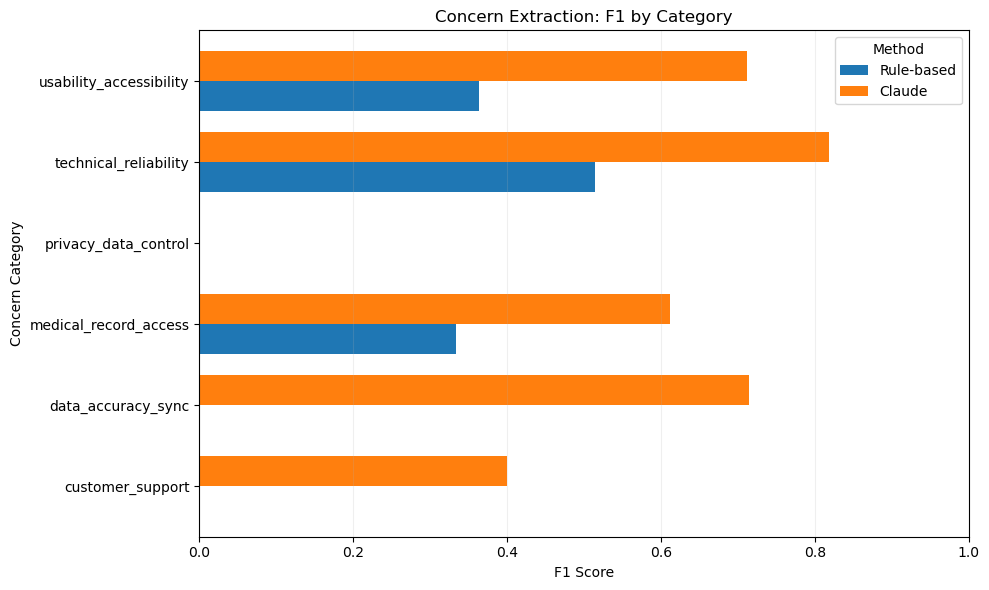

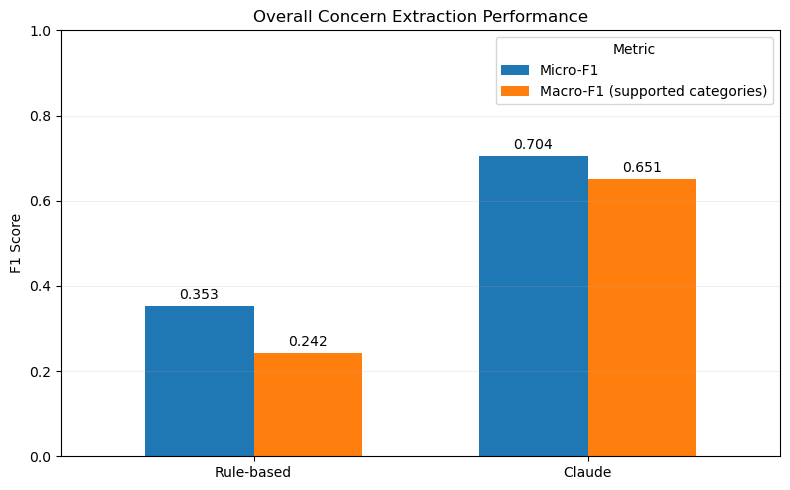


STEP 47 COMPLETE
Saved: c:\Users\sahit\OneDrive\Desktop\INFO4360\Project\HealthTrust-Watch\results\figures\claude_vs_rules_category_f1.png
Saved: c:\Users\sahit\OneDrive\Desktop\INFO4360\Project\HealthTrust-Watch\results\figures\claude_vs_rules_overall_f1.png
No Claude API calls were made.


In [89]:

# ============================================================
# STEP 47 — CLAUDE VS RULE-BASED PERFORMANCE VISUALIZATIONS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Find the project directory
if "project_root" in globals():
    ROOT = Path(project_root)
else:
    ROOT = Path.cwd()
    if ROOT.name.lower() == "notebooks":
        ROOT = ROOT.parent

RESULTS_DIR = ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Read the saved Step 46 results
category_df = pd.read_csv(
    RESULTS_DIR / "model_comparison_by_category.csv"
)

summary_df = pd.read_csv(
    RESULTS_DIR / "model_comparison_summary.csv"
)

print("Category comparison columns:", category_df.columns.tolist())
print("Summary columns:", summary_df.columns.tolist())

# Handle long-format category results
if {"model", "category", "f1"}.issubset(category_df.columns):
    category_plot = category_df.pivot(
        index="category",
        columns="model",
        values="f1"
    )

# Handle already-pivoted category results
elif "category" in category_df.columns:
    category_plot = category_df.set_index("category")

else:
    category_plot = category_df.copy()
    if "model" in category_plot.columns:
        category_plot = category_plot.set_index("model").T

# Standardize model order
model_order = [
    name for name in ["Rule-based", "Claude"]
    if name in category_plot.columns
]

category_plot = category_plot[model_order].fillna(0)

# Plot 1: Per-category F1
ax = category_plot.plot(
    kind="barh",
    figsize=(10, 6),
    width=0.75
)

ax.set_title("Concern Extraction: F1 by Category")
ax.set_xlabel("F1 Score")
ax.set_ylabel("Concern Category")
ax.set_xlim(0, 1)
ax.legend(title="Method")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()

chart1 = FIGURES_DIR / "claude_vs_rules_category_f1.png"
plt.savefig(chart1, dpi=200, bbox_inches="tight")
plt.show()

# Plot 2: Overall F1 comparison
required_cols = {"model", "micro_f1", "macro_f1_supported"}

if not required_cols.issubset(summary_df.columns):
    raise ValueError(
        f"Unexpected summary columns: {summary_df.columns.tolist()}"
    )

summary_plot = summary_df.set_index("model")[
    ["micro_f1", "macro_f1_supported"]
]

summary_plot = summary_plot.rename(columns={
    "micro_f1": "Micro-F1",
    "macro_f1_supported": "Macro-F1 (supported categories)"
})

ax = summary_plot.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0,
    width=0.65
)

ax.set_title("Overall Concern Extraction Performance")
ax.set_ylabel("F1 Score")
ax.set_xlabel("")
ax.set_ylim(0, 1)
ax.legend(title="Metric")
ax.grid(axis="y", alpha=0.2)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()

chart2 = FIGURES_DIR / "claude_vs_rules_overall_f1.png"
plt.savefig(chart2, dpi=200, bbox_inches="tight")
plt.show()

print("\nSTEP 47 COMPLETE")
print("Saved:", chart1)
print("Saved:", chart2)
print("No Claude API calls were made.")


In [90]:

# ============================================================
# STEP 48 — FULL-CORPUS RULE-BASED CONCERN EXTRACTION
# ============================================================

from pathlib import Path
import pandas as pd
import inspect
import time

# Locate project
ROOT = Path(project_root) if "project_root" in globals() else Path.cwd()

if ROOT.name.lower() == "notebooks":
    ROOT = ROOT.parent

RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", ROOT)

# ------------------------------------------------------------
# 1. Verify the cleaned dataset
# ------------------------------------------------------------

if "df_master" not in globals():
    raise NameError(
        "df_master is not available. Run the earlier dataset "
        "preparation cells before Step 48."
    )

print("\nDataset shape:", df_master.shape)
print("\nAvailable columns:")
print(df_master.columns.tolist())

# ------------------------------------------------------------
# 2. Find the previously defined rule-based classifier
# ------------------------------------------------------------

print("\nPossible rule-based functions:")

candidate_functions = []

for name, obj in list(globals().items()):
    if (
        callable(obj)
        and inspect.isfunction(obj)
        and any(
            term in name.lower()
            for term in ["rule", "regex", "classify", "extract"]
        )
    ):
        candidate_functions.append(name)

for name in candidate_functions:
    print(" -", name)

print("\nExisting label columns:")

if "label_columns" in globals():
    print(label_columns)
else:
    print("label_columns variable not found.")

# ------------------------------------------------------------
# 3. Show available review-text columns
# ------------------------------------------------------------

possible_text_columns = [
    col for col in df_master.columns
    if any(
        term in col.lower()
        for term in ["review", "text", "content"]
    )
]

print("\nPossible text columns:")
print(possible_text_columns)

print("\nSTEP 48A — INSPECTION COMPLETE")
print(
    "Send this output before we execute the full-corpus "
    "classifier. No API calls were made."
)


Project directory: c:\Users\sahit\OneDrive\Desktop\INFO4360\Project\HealthTrust-Watch

Dataset shape: (93346, 19)

Available columns:
['reviewId', 'content', 'score', 'thumbsUpCount', 'reviewCreatedVersion', 'at', 'replyContent', 'repliedAt', 'app_name', 'app_id', 'word_count', 'year', 'sentiment', 'App_Type', 'trust_dimension', 'confidence_score', 'review_text', 'token_count', 'length_group']

Possible rule-based functions:
 - predict_rule_based

Existing label columns:
['technical_reliability', 'medical_record_access', 'usability_accessibility', 'customer_support', 'data_accuracy_sync', 'privacy_data_control']

Possible text columns:
['reviewId', 'content', 'reviewCreatedVersion', 'replyContent', 'review_text']

STEP 48A — INSPECTION COMPLETE
Send this output before we execute the full-corpus classifier. No API calls were made.


In [91]:

# ============================================================
# STEP 48B — APPLY EXISTING RULES TO ALL 93,346 REVIEWS
# LOCAL PYTHON ONLY — NO CLAUDE API CALLS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import time

ROOT = Path(project_root)
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Confirm required objects
assert "df_master" in globals(), "df_master is missing."
assert callable(predict_rule_based), "Rule classifier is missing."
assert len(label_columns) == 6, "Expected six concern labels."

print("Starting full-corpus rule-based extraction...")
print("Reviews:", f"{len(df_master):,}")
print("Classifier: predict_rule_based")
print("API calls: NONE")

start_time = time.perf_counter()

# Apply the EXACT classifier already evaluated in Step 46
predictions = [
    predict_rule_based(str(text) if pd.notna(text) else "")
    for text in df_master["review_text"]
]

# Convert predictions to a DataFrame
# Expected output: a dictionary containing six binary labels
pred_df = pd.DataFrame(predictions)

missing_labels = [
    col for col in label_columns
    if col not in pred_df.columns
]

if missing_labels:
    raise ValueError(
        f"Classifier output is missing labels: {missing_labels}. "
        f"Available fields: {pred_df.columns.tolist()}"
    )

pred_df = pred_df[label_columns].copy()

# Validate predictions
for col in label_columns:
    pred_df[col] = pd.to_numeric(pred_df[col], errors="raise")
    if not pred_df[col].isin([0, 1]).all():
        raise ValueError(f"Non-binary values detected in {col}")

# Preserve original dataset and add predictions
df_full_rule = df_master.reset_index(drop=True).copy()

for col in label_columns:
    df_full_rule[f"rule_{col}"] = pred_df[col].astype(int).to_numpy()

df_full_rule["rule_any_concern"] = (
    df_full_rule[[f"rule_{col}" for col in label_columns]]
    .max(axis=1)
)

# Save the results
output_path = RESULTS_DIR / "full_corpus_rule_predictions.csv"
df_full_rule.to_csv(output_path, index=False, encoding="utf-8")

elapsed = time.perf_counter() - start_time

print("\nFULL-CORPUS EXTRACTION COMPLETE")
print("=" * 55)
print("Rows processed:", f"{len(df_full_rule):,}")
print("Output shape:", df_full_rule.shape)
print("Runtime (seconds):", round(elapsed, 2))
print("Reviews with at least one rule-detected concern:",
      f"{df_full_rule['rule_any_concern'].sum():,}")

print("\nRule-detected concerns by category:")
for col in label_columns:
    count = int(df_full_rule[f"rule_{col}"].sum())
    pct = 100 * count / len(df_full_rule)
    print(f"{col:28s} {count:>7,} ({pct:5.2f}%)")

print("\nSaved to:", output_path)
print("Additional API cost: $0")


Starting full-corpus rule-based extraction...
Reviews: 93,346
Classifier: predict_rule_based
API calls: NONE

FULL-CORPUS EXTRACTION COMPLETE
Rows processed: 93,346
Output shape: (93346, 26)
Runtime (seconds): 13.99
Reviews with at least one rule-detected concern: 5,933

Rule-detected concerns by category:
technical_reliability          3,321 ( 3.56%)
medical_record_access            926 ( 0.99%)
usability_accessibility        1,532 ( 1.64%)
customer_support                 167 ( 0.18%)
data_accuracy_sync               173 ( 0.19%)
privacy_data_control             130 ( 0.14%)

Saved to: c:\Users\sahit\OneDrive\Desktop\INFO4360\Project\HealthTrust-Watch\results\full_corpus_rule_predictions.csv
Additional API cost: $0


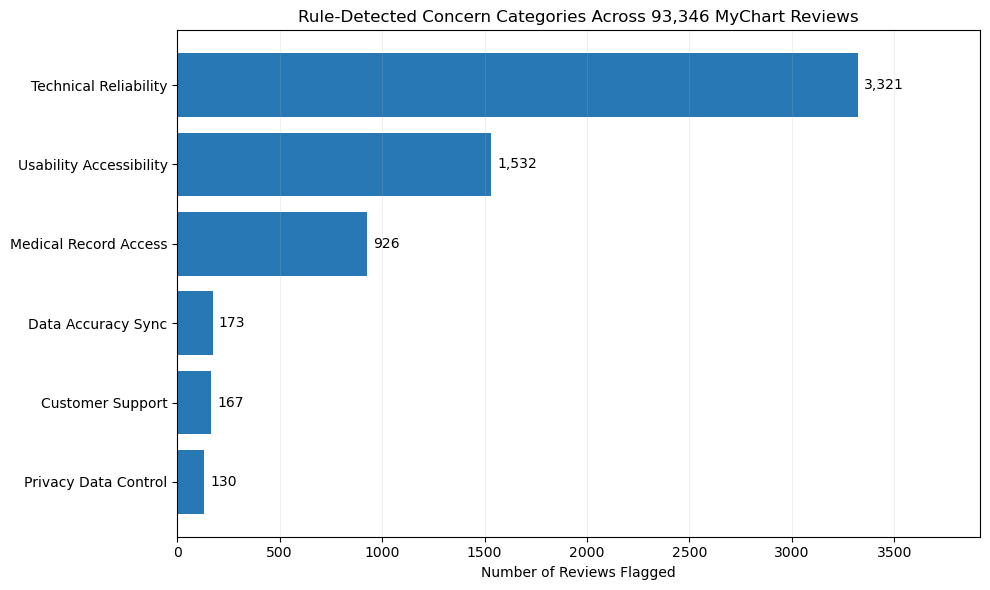


FULL-CORPUS CONCERN SUMMARY
               category  reviews_flagged  pct_all_reviews  pct_of_all_category_flags
  technical_reliability             3321             3.56                      53.14
usability_accessibility             1532             1.64                      24.52
  medical_record_access              926             0.99                      14.82
     data_accuracy_sync              173             0.19                       2.77
       customer_support              167             0.18                       2.67
   privacy_data_control              130             0.14                       2.08

NUMBER OF CATEGORIES DETECTED PER REVIEW
 number_of_categories  number_of_reviews
                    0              87413
                    1               5628
                    2                294
                    3                 11

Total reviews: 93,346
Total category flags: 6,249
Reviews with at least one flag: 5,933

Saved:
c:\Users\sahit\OneDrive\Desktop\

In [93]:

# ============================================================
# STEP 49 — FULL-CORPUS CONCERN FREQUENCY ANALYSIS
# LOCAL PYTHON ONLY — NO CLAUDE API CALLS
# ============================================================

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(project_root)
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Load saved results if needed
if "df_full_rule" not in globals():
    df_full_rule = pd.read_csv(
        RESULTS_DIR / "full_corpus_rule_predictions.csv"
    )

rule_cols = [f"rule_{col}" for col in label_columns]
total_reviews = len(df_full_rule)

# 1. Frequency summary
summary = pd.DataFrame({
    "category": label_columns,
    "reviews_flagged": [
        int(df_full_rule[f"rule_{col}"].sum())
        for col in label_columns
    ]
})

summary["pct_all_reviews"] = (
    summary["reviews_flagged"] / total_reviews * 100
)

total_flags = summary["reviews_flagged"].sum()

summary["pct_of_all_category_flags"] = (
    summary["reviews_flagged"] / total_flags * 100
)

summary = summary.sort_values(
    "reviews_flagged", ascending=False
).reset_index(drop=True)

# 2. Number of detected categories per review
df_full_rule["rule_concern_count"] = (
    df_full_rule[rule_cols].sum(axis=1)
)

count_distribution = (
    df_full_rule["rule_concern_count"]
    .value_counts()
    .sort_index()
    .rename_axis("number_of_categories")
    .reset_index(name="number_of_reviews")
)

# 3. Save summary tables
summary_path = RESULTS_DIR / "full_corpus_concern_summary.csv"
distribution_path = RESULTS_DIR / "full_corpus_concern_count_distribution.csv"

summary.to_csv(summary_path, index=False)
count_distribution.to_csv(distribution_path, index=False)

# 4. Presentation-ready category frequency chart
plot_df = summary.sort_values("reviews_flagged")

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    plot_df["category"].str.replace("_", " ").str.title(),
    plot_df["reviews_flagged"],
    color="#2878B5"
)

for bar, value in zip(bars, plot_df["reviews_flagged"]):
    ax.text(
        bar.get_width() + 30,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,}",
        va="center",
        fontsize=10
    )

ax.set_xlim(0, summary["reviews_flagged"].max() * 1.18)
ax.set_title(
    "Rule-Detected Concern Categories Across 93,346 MyChart Reviews"
)
ax.set_xlabel("Number of Reviews Flagged")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()

chart_path = FIGURES_DIR / "full_corpus_concern_frequency.png"
plt.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()

# 5. Print results
print("\nFULL-CORPUS CONCERN SUMMARY")
print("=" * 65)
print(summary.round(2).to_string(index=False))

print("\nNUMBER OF CATEGORIES DETECTED PER REVIEW")
print("=" * 65)
print(count_distribution.to_string(index=False))

print("\nTotal reviews:", f"{total_reviews:,}")
print("Total category flags:", f"{total_flags:,}")
print("Reviews with at least one flag:",
      f"{int((df_full_rule['rule_concern_count'] > 0).sum()):,}")

print("\nSaved:")
print(summary_path)
print(distribution_path)
print(chart_path)
print("\nAdditional API cost: $0")


Reviews with valid star ratings: 93,346


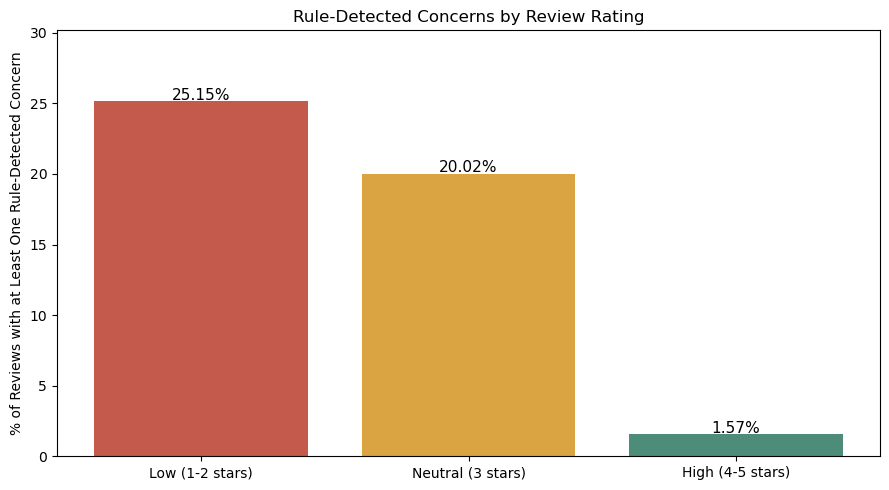

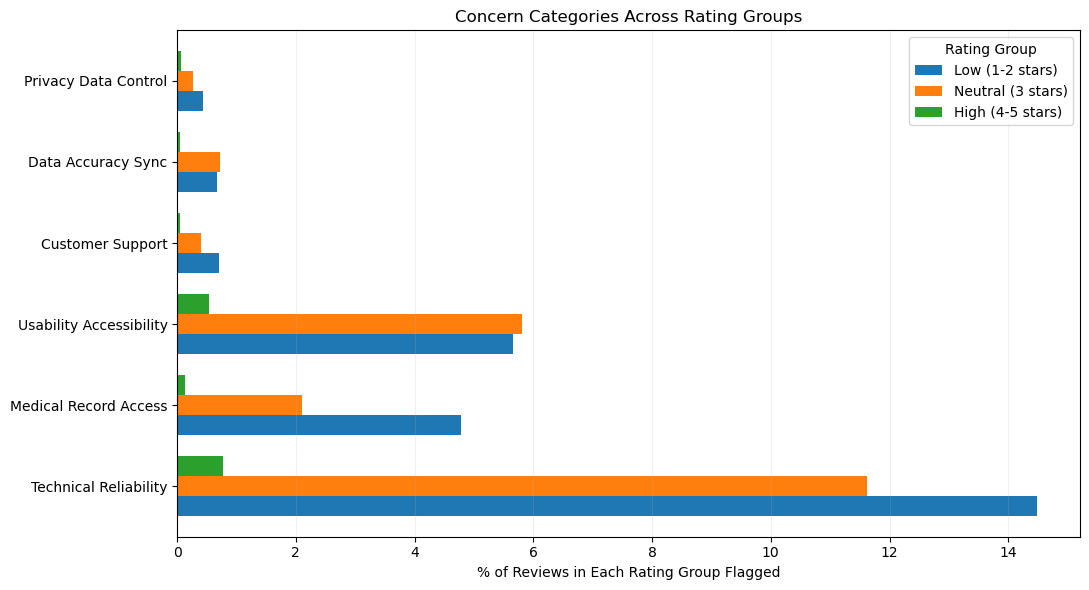


REVIEWS PER RATING GROUP
rating_group
Low (1-2 stars)      15119
Neutral (3 stars)     4894
High (4-5 stars)     73333

ANY RULE-DETECTED CONCERN (%)
rating_group
Low (1-2 stars)      25.15
Neutral (3 stars)    20.02
High (4-5 stars)      1.57

CATEGORY FLAG RATES (%)
                   Technical Reliability  Medical Record Access  Usability Accessibility  Customer Support  Data Accuracy Sync  Privacy Data Control
rating_group                                                                                                                                        
Low (1-2 stars)                    14.49                   4.78                     5.65              0.71                0.67                  0.43
Neutral (3 stars)                  11.63                   2.10                     5.80              0.41                0.72                  0.27
High (4-5 stars)                    0.77                   0.14                     0.54              0.05                0.05        

In [94]:

# ============================================================
# STEP 50 — CONCERN PATTERNS BY STAR RATING
# LOCAL PYTHON ONLY — NO CLAUDE API CALLS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path(project_root)
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Load previously saved full-corpus results if needed
if "df_full_rule" not in globals():
    df_full_rule = pd.read_csv(
        RESULTS_DIR / "full_corpus_rule_predictions.csv"
    )

df_rating = df_full_rule.copy()

# Verify the rating column
df_rating["score"] = pd.to_numeric(
    df_rating["score"], errors="coerce"
)

df_rating = df_rating[
    df_rating["score"].isin([1, 2, 3, 4, 5])
].copy()

print("Reviews with valid star ratings:", f"{len(df_rating):,}")

# Group ratings for stakeholder interpretation
df_rating["rating_group"] = np.select(
    [
        df_rating["score"].isin([1, 2]),
        df_rating["score"].eq(3),
        df_rating["score"].isin([4, 5])
    ],
    [
        "Low (1-2 stars)",
        "Neutral (3 stars)",
        "High (4-5 stars)"
    ],
    default="Other"
)

rating_order = [
    "Low (1-2 stars)",
    "Neutral (3 stars)",
    "High (4-5 stars)"
]

rule_cols = [f"rule_{col}" for col in label_columns]

# Group sizes
group_sizes = (
    df_rating.groupby("rating_group")
    .size()
    .reindex(rating_order)
)

# Percentage of reviews flagged in each group
rate_table = (
    df_rating.groupby("rating_group")[rule_cols]
    .mean()
    .reindex(rating_order)
    .mul(100)
)

rate_table.columns = [
    col.replace("rule_", "").replace("_", " ").title()
    for col in rate_table.columns
]

# Overall rate of at least one concern
any_concern_rates = (
    df_rating.groupby("rating_group")["rule_any_concern"]
    .mean()
    .reindex(rating_order)
    .mul(100)
)

# Save tables
rate_table.to_csv(
    RESULTS_DIR / "concern_rates_by_rating.csv"
)

pd.DataFrame({
    "rating_group": rating_order,
    "review_count": group_sizes.values,
    "pct_any_rule_concern": any_concern_rates.values
}).to_csv(
    RESULTS_DIR / "overall_concern_rates_by_rating.csv",
    index=False
)

# Chart 1 — Any rule-detected concern
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    rating_order,
    any_concern_rates.values,
    color=["#C45A4C", "#D9A441", "#4D8C78"]
)

ax.set_title("Rule-Detected Concerns by Review Rating")
ax.set_ylabel("% of Reviews with at Least One Rule-Detected Concern")
ax.set_ylim(0, max(any_concern_rates.max() * 1.2, 1))

for bar, value in zip(bars, any_concern_rates.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{value:.2f}%",
        ha="center",
        fontsize=11
    )

plt.tight_layout()

chart1 = FIGURES_DIR / "overall_concern_rates_by_rating.png"
plt.savefig(chart1, dpi=200, bbox_inches="tight")
plt.show()

# Chart 2 — Concern categories by rating
fig, ax = plt.subplots(figsize=(11, 6))

rate_table.T.plot(
    kind="barh",
    ax=ax,
    width=0.75
)

ax.set_title("Concern Categories Across Rating Groups")
ax.set_xlabel("% of Reviews in Each Rating Group Flagged")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.2)
ax.legend(title="Rating Group")

plt.tight_layout()

chart2 = FIGURES_DIR / "concern_categories_by_rating.png"
plt.savefig(chart2, dpi=200, bbox_inches="tight")
plt.show()

print("\nREVIEWS PER RATING GROUP")
print(group_sizes.to_string())

print("\nANY RULE-DETECTED CONCERN (%)")
print(any_concern_rates.round(2).to_string())

print("\nCATEGORY FLAG RATES (%)")
print(rate_table.round(2).to_string())

print("\nSaved charts:")
print(chart1)
print(chart2)
print("\nAdditional Claude API cost: $0")


C:\Users\sahit\AppData\Local\Temp\ipykernel_7648\1251112207.py:25: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_time["review_date"] = pd.to_datetime(


Reviews with valid dates: 93,346
Date range: 2011-11-01 14:21:00 to 2025-04-12 01:29:00


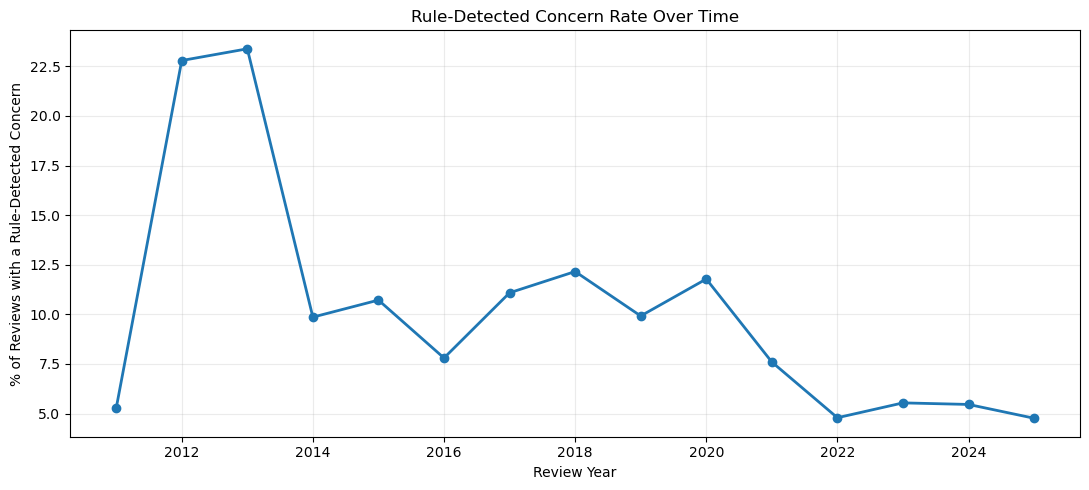

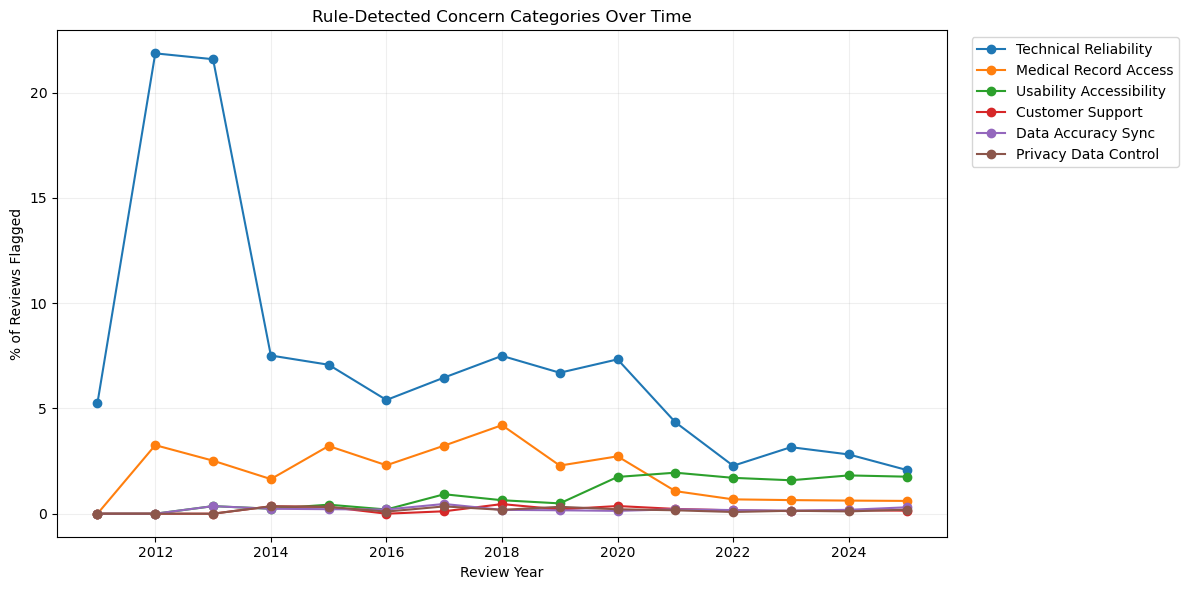


YEARLY CONCERN SUMMARY
 review_year  review_count  any_concern_rate
        2011            19              5.26
        2012           215             22.79
        2013           278             23.38
        2014           852              9.86
        2015           933             10.72
        2016          1000              7.80
        2017           866             11.09
        2018          1094             12.16
        2019          2450              9.92
        2020          5212             11.78
        2021         12320              7.60
        2022         23195              4.79
        2023         18580              5.54
        2024         20076              5.46
        2025          6256              4.76

APP VERSION COVERAGE
91.38% of dated reviews have version data

TOP 15 APP VERSIONS BY REVIEW COUNT
app_version_clean  review_count  concern_rate
            9.9.2          3596          5.26
           10.2.1          3303          4.66
           10.2.4

In [95]:

# ============================================================
# STEP 51 — HISTORICAL TRENDS AND APP VERSION ANALYSIS
# LOCAL PYTHON ONLY — NO CLAUDE API CALLS
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path(project_root)
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Use the full-corpus predictions from Step 48
if "df_full_rule" not in globals():
    df_full_rule = pd.read_csv(
        RESULTS_DIR / "full_corpus_rule_predictions.csv"
    )

df_time = df_full_rule.copy()

# Parse dates
df_time["review_date"] = pd.to_datetime(
    df_time["at"], errors="coerce"
)

df_time = df_time.dropna(subset=["review_date"]).copy()

df_time["review_year"] = df_time["review_date"].dt.year
df_time["review_month"] = df_time["review_date"].dt.to_period("M")

rule_cols = [f"rule_{col}" for col in label_columns]

print("Reviews with valid dates:", f"{len(df_time):,}")
print(
    "Date range:",
    df_time["review_date"].min(),
    "to",
    df_time["review_date"].max()
)

# ------------------------------------------------------------
# 1. Yearly concern rates
# ------------------------------------------------------------

yearly = (
    df_time.groupby("review_year")
    .agg(
        review_count=("reviewId", "size"),
        any_concern_rate=("rule_any_concern", "mean"),
        **{
            f"{col}_rate": (f"rule_{col}", "mean")
            for col in label_columns
        }
    )
    .reset_index()
)

rate_cols = [
    col for col in yearly.columns
    if col.endswith("_rate")
]

yearly[rate_cols] = yearly[rate_cols] * 100

yearly.to_csv(
    RESULTS_DIR / "yearly_concern_trends.csv",
    index=False
)

# ------------------------------------------------------------
# 2. Monthly concern rates
# ------------------------------------------------------------

monthly = (
    df_time.groupby("review_month")
    .agg(
        review_count=("reviewId", "size"),
        any_concern_rate=("rule_any_concern", "mean")
    )
    .reset_index()
)

monthly["review_month"] = monthly["review_month"].astype(str)
monthly["any_concern_rate"] *= 100

monthly.to_csv(
    RESULTS_DIR / "monthly_concern_trends.csv",
    index=False
)

# ------------------------------------------------------------
# 3. Yearly trend visualization
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    yearly["review_year"],
    yearly["any_concern_rate"],
    marker="o",
    linewidth=2
)

ax.set_title("Rule-Detected Concern Rate Over Time")
ax.set_xlabel("Review Year")
ax.set_ylabel("% of Reviews with a Rule-Detected Concern")
ax.grid(alpha=0.25)

plt.tight_layout()

year_chart = FIGURES_DIR / "yearly_concern_trends.png"
plt.savefig(year_chart, dpi=200, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 4. Category trends
# ------------------------------------------------------------

category_rate_cols = [
    f"{col}_rate" for col in label_columns
]

fig, ax = plt.subplots(figsize=(12, 6))

for col in category_rate_cols:
    ax.plot(
        yearly["review_year"],
        yearly[col],
        marker="o",
        label=col.replace("_rate", "").replace("_", " ").title()
    )

ax.set_title("Rule-Detected Concern Categories Over Time")
ax.set_xlabel("Review Year")
ax.set_ylabel("% of Reviews Flagged")
ax.grid(alpha=0.2)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()

category_chart = FIGURES_DIR / "yearly_category_trends.png"
plt.savefig(category_chart, dpi=200, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 5. App version coverage and top versions
# ------------------------------------------------------------

version_col = "reviewCreatedVersion"

df_time["app_version_clean"] = (
    df_time[version_col]
    .astype("string")
    .str.strip()
)

df_time["app_version_clean"] = (
    df_time["app_version_clean"]
    .replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})
)

version_coverage = (
    df_time["app_version_clean"].notna().mean() * 100
)

version_summary = (
    df_time.dropna(subset=["app_version_clean"])
    .groupby("app_version_clean")
    .agg(
        review_count=("reviewId", "size"),
        concern_rate=("rule_any_concern", "mean")
    )
    .reset_index()
)

version_summary["concern_rate"] *= 100

version_summary = version_summary.sort_values(
    "review_count", ascending=False
)

version_summary.to_csv(
    RESULTS_DIR / "app_version_concern_summary.csv",
    index=False
)

# ------------------------------------------------------------
# 6. Print results
# ------------------------------------------------------------

print("\nYEARLY CONCERN SUMMARY")
print(
    yearly[
        ["review_year", "review_count", "any_concern_rate"]
    ].round(2).to_string(index=False)
)

print("\nAPP VERSION COVERAGE")
print(f"{version_coverage:.2f}% of dated reviews have version data")

print("\nTOP 15 APP VERSIONS BY REVIEW COUNT")
print(version_summary.head(15).round(2).to_string(index=False))

print("\nSaved charts:")
print(year_chart)
print(category_chart)

print("\nSaved tables:")
print("yearly_concern_trends.csv")
print("monthly_concern_trends.csv")
print("app_version_concern_summary.csv")

print("\nAdditional Claude API cost: $0")


In [96]:

# ============================================================
# STEP 52A — AUDIT EXISTING NLP ANALYSIS
# LOCAL INSPECTION ONLY — NO API CALLS
# ============================================================

from pathlib import Path

ROOT = Path(project_root)
NOTEBOOKS_DIR = ROOT / "notebooks"
RESULTS_DIR = ROOT / "results"

print("PROJECT NOTEBOOKS")
print("=" * 55)

for path in sorted(NOTEBOOKS_DIR.glob("*.ipynb")):
    print("-", path.name)

print("\nSAVED ANALYSIS FILES")
print("=" * 55)

if RESULTS_DIR.exists():
    for path in sorted(RESULTS_DIR.rglob("*")):
        if path.is_file():
            print("-", path.relative_to(ROOT))

print("\nEXISTING NLP VARIABLES")
print("=" * 55)

keywords = [
    "tfidf", "vectorizer", "nmf", "lda", "topic",
    "sentiment", "vader", "keyword", "bigram",
    "spacy", "nlp"
]

matches = [
    name for name in globals()
    if any(term in name.lower() for term in keywords)
]

for name in sorted(matches):
    obj = globals()[name]
    print(f"{name:40s} {type(obj).__name__}")

print("\nDATASET COLUMNS")
print("=" * 55)
print(df_master.columns.tolist())

print("\nSTEP 52A INSPECTION COMPLETE")
print("No Claude API calls were made.")


PROJECT NOTEBOOKS
- ProjectphaseII.ipynb
- ProjectphaseIII.ipynb

SAVED ANALYSIS FILES
- results\app_version_concern_summary.csv
- results\claude_api_usage_log.csv
- results\claude_full_predictions.csv
- results\claude_pilot_predictions.csv
- results\concern_rates_by_rating.csv
- results\figures\claude_vs_rules_category_f1.png
- results\figures\claude_vs_rules_overall_f1.png
- results\figures\concern_categories_by_rating.png
- results\figures\full_corpus_concern_frequency.png
- results\figures\overall_concern_rates_by_rating.png
- results\figures\yearly_category_trends.png
- results\figures\yearly_concern_trends.png
- results\full_corpus_concern_count_distribution.csv
- results\full_corpus_concern_summary.csv
- results\full_corpus_rule_predictions.csv
- results\model_comparison_by_category.csv
- results\model_comparison_summary.csv
- results\monthly_concern_trends.csv
- results\overall_concern_rates_by_rating.csv
- results\rule_baseline_v1_metrics.csv
- results\rule_baseline_v1_predict

In [98]:

# ============================================================
# STEP 52C — VERIFY SAVED PHASE II TOPIC-MODELING RESULTS
# READ-ONLY — NO CLAUDE API CALLS
# ============================================================

import json
from pathlib import Path

ROOT = Path(project_root)
notebook_path = ROOT / "notebooks" / "ProjectphaseII.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

# Cell numbers are 1-based, matching our Step 52B audit.
cells_to_inspect = [27, 28, 29, 33, 35, 36]

for cell_number in cells_to_inspect:
    cell = nb["cells"][cell_number - 1]

    print("\n" + "=" * 75)
    print(f"PHASE II CELL {cell_number} — {cell['cell_type'].upper()}")
    print("=" * 75)

    source = "".join(cell.get("source", []))
    print("\nSOURCE / INTERPRETATION:")
    print(source[:3500])

    if cell["cell_type"] == "code":
        outputs = cell.get("outputs", [])

        print(f"\nSAVED OUTPUTS: {len(outputs)}")

        for output in outputs:
            if "text" in output:
                print("".join(output["text"])[:2500])

            elif "data" in output:
                data = output["data"]

                if "text/plain" in data:
                    print(
                        "".join(data["text/plain"])[:2500]
                    )

                elif "image/png" in data:
                    print("[Saved visualization present]")

print("\nSTEP 52C COMPLETE")
print("No notebook cells were executed.")
print("No Claude API calls were made.")



PHASE II CELL 27 — MARKDOWN

SOURCE / INTERPRETATION:
## 7. Topic Modeling Using TF-IDF and NMF

This section uses TF-IDF vectorization and Non-Negative Matrix
Factorization (NMF) to discover recurring themes in MyChart reviews.

The objective is to identify candidate themes related to user
experiences, technical reliability, usability, and access to
health information.

Topic labels will be interpreted and manually validated rather
than treated as automatically verified issue categories.

PHASE II CELL 28 — CODE

SOURCE / INTERPRETATION:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

# Use the cleaned text created in Section 4
topic_texts = mychart_clean.loc[
    mychart_clean["processed_text"].fillna("").str.strip().ne(""),
    "processed_text"
]

# Create TF-IDF features
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    min_df=5,
    max_df=0.90,
    ngram_range=(1, 2)
)

tfidf_matrix = tfidf_vectorizer.fit_transform(

In [99]:

# ============================================================
# STEP 53A — PREPARE DATA FOR RATING PREDICTION
# LOCAL PYTHON ONLY — ZERO CLAUDE API CALLS
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path(project_root)
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Use the cleaned full dataset
df_predict = df_master.copy()

# Ensure text, rating, and date are usable
df_predict["review_text"] = (
    df_predict["review_text"].fillna("").astype(str)
)

df_predict["score"] = pd.to_numeric(
    df_predict["score"], errors="coerce"
)

df_predict["review_date"] = pd.to_datetime(
    df_predict["at"], errors="coerce"
)

df_predict = df_predict[
    df_predict["review_text"].str.strip().ne("")
    & df_predict["score"].isin([1, 2, 3, 4, 5])
    & df_predict["review_date"].notna()
].copy()

# Binary target: 1 = low rating, 0 = other ratings
df_predict["low_rating"] = (
    df_predict["score"] <= 2
).astype(int)

# Chronological ordering
df_predict = df_predict.sort_values(
    ["review_date", "reviewId"]
).reset_index(drop=True)

# Approximately 80% train, 20% test
split_index = int(len(df_predict) * 0.80)

train_df = df_predict.iloc[:split_index].copy()
test_df = df_predict.iloc[split_index:].copy()

print("TOTAL REVIEWS:", f"{len(df_predict):,}")
print("TRAIN REVIEWS:", f"{len(train_df):,}")
print("TEST REVIEWS:", f"{len(test_df):,}")

print("\nTRAIN DATE RANGE")
print(
    train_df["review_date"].min(),
    "to",
    train_df["review_date"].max()
)

print("\nTEST DATE RANGE")
print(
    test_df["review_date"].min(),
    "to",
    test_df["review_date"].max()
)

print("\nTRAIN TARGET DISTRIBUTION")
print(
    train_df["low_rating"]
    .value_counts()
    .rename(index={0: "3–5 stars", 1: "1–2 stars"})
)

print("\nTEST TARGET DISTRIBUTION")
print(
    test_df["low_rating"]
    .value_counts()
    .rename(index={0: "3–5 stars", 1: "1–2 stars"})
)

print("\nTRAIN LOW-RATING RATE:",
      f"{train_df['low_rating'].mean()*100:.2f}%")

print("TEST LOW-RATING RATE:",
      f"{test_df['low_rating'].mean()*100:.2f}%")

print("\nSTEP 53A COMPLETE")
print("No model training yet.")
print("No Claude API calls.")


C:\Users\sahit\AppData\Local\Temp\ipykernel_7648\2473361375.py:26: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_predict["review_date"] = pd.to_datetime(


TOTAL REVIEWS: 93,346
TRAIN REVIEWS: 74,676
TEST REVIEWS: 18,670

TRAIN DATE RANGE
2011-11-01 14:21:00 to 2024-05-10 09:16:00

TEST DATE RANGE
2024-05-10 09:37:00 to 2025-04-12 01:29:00

TRAIN TARGET DISTRIBUTION
low_rating
3–5 stars    62132
1–2 stars    12544
Name: count, dtype: int64

TEST TARGET DISTRIBUTION
low_rating
3–5 stars    16095
1–2 stars     2575
Name: count, dtype: int64

TRAIN LOW-RATING RATE: 16.80%
TEST LOW-RATING RATE: 13.79%

STEP 53A COMPLETE
No model training yet.
No Claude API calls.


In [100]:

# ============================================================
# STEP 53B — TRAIN TF-IDF + LOGISTIC REGRESSION
# LOCAL SCIKIT-LEARN ONLY — NO CLAUDE API CALLS
# ============================================================

from pathlib import Path
import time
import pandas as pd
import joblib

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

ROOT = Path(project_root)
MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Text and target
X_train = train_df["review_text"].astype(str)
y_train = train_df["low_rating"].astype(int)

X_test = test_df["review_text"].astype(str)
y_test = test_df["low_rating"].astype(int)

# Main predictive model
rating_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        min_df=5,
        max_df=0.95,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Majority-class baseline
baseline_model = DummyClassifier(
    strategy="most_frequent"
)

print("Training TF-IDF + Logistic Regression...")
start = time.perf_counter()

rating_model.fit(X_train, y_train)

elapsed = time.perf_counter() - start
print(f"Training completed in {elapsed:.2f} seconds.")

baseline_model.fit(X_train, y_train)

# Compare training and testing performance
results = []

for model_name, model in [
    ("Majority-class baseline", baseline_model),
    ("TF-IDF + Logistic Regression", rating_model)
]:
    for split_name, X, y in [
        ("Train", X_train, y_train),
        ("Test", X_test, y_test)
    ]:
        predictions = model.predict(X)

        results.append({
            "model": model_name,
            "split": split_name,
            "accuracy": accuracy_score(y, predictions),
            "f1_low_rating": f1_score(
                y, predictions, zero_division=0
            )
        })

metrics_df = pd.DataFrame(results)

# Save model and metrics
joblib.dump(
    rating_model,
    MODELS_DIR / "tfidf_logistic_rating_model.joblib"
)

joblib.dump(
    baseline_model,
    MODELS_DIR / "majority_class_baseline.joblib"
)

metrics_df.to_csv(
    ROOT / "results" / "rating_prediction_metrics.csv",
    index=False
)

print("\nTRAIN / TEST PERFORMANCE")
print("=" * 65)
print(metrics_df.round(4).to_string(index=False))

print("\nSaved models in:", MODELS_DIR)
print("Saved metrics in: results/rating_prediction_metrics.csv")
print("Additional Claude API cost: $0")


Training TF-IDF + Logistic Regression...
Training completed in 5.54 seconds.

TRAIN / TEST PERFORMANCE
                       model split  accuracy  f1_low_rating
     Majority-class baseline Train    0.8320         0.0000
     Majority-class baseline  Test    0.8621         0.0000
TF-IDF + Logistic Regression Train    0.9249         0.8133
TF-IDF + Logistic Regression  Test    0.9245         0.7714

Saved models in: c:\Users\sahit\OneDrive\Desktop\INFO4360\Project\HealthTrust-Watch\models
Saved metrics in: results/rating_prediction_metrics.csv
Additional Claude API cost: $0


TEST SET PERFORMANCE
                       model  accuracy  precision_low_rating  recall_low_rating  f1_low_rating
     Majority-class baseline    0.8621                0.0000             0.0000         0.0000
TF-IDF + Logistic Regression    0.9245                0.6621             0.9239         0.7714


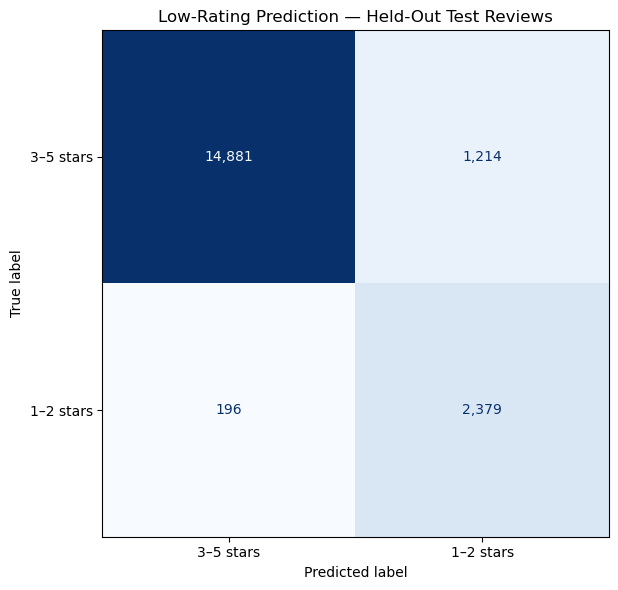

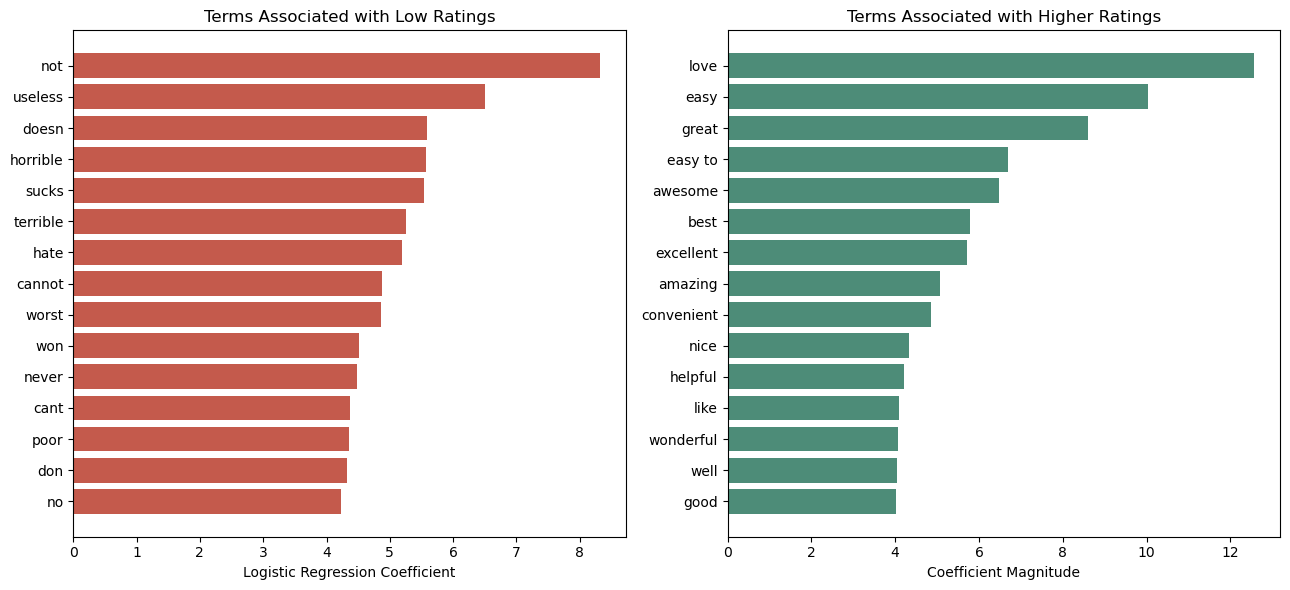


CONFUSION MATRIX
Rows = actual labels, columns = predicted labels
[[14881  1214]
 [  196  2379]]

TOP TERMS ASSOCIATED WITH LOW RATINGS
    term  coefficient        associated_with
     not        8.314 Low rating (1–2 stars)
 useless        6.497 Low rating (1–2 stars)
   doesn        5.592 Low rating (1–2 stars)
horrible        5.575 Low rating (1–2 stars)
   sucks        5.542 Low rating (1–2 stars)
terrible        5.251 Low rating (1–2 stars)
    hate        5.188 Low rating (1–2 stars)
  cannot        4.877 Low rating (1–2 stars)
   worst        4.865 Low rating (1–2 stars)
     won        4.519 Low rating (1–2 stars)
   never        4.483 Low rating (1–2 stars)
    cant        4.370 Low rating (1–2 stars)
    poor        4.354 Low rating (1–2 stars)
     don        4.319 Low rating (1–2 stars)
      no        4.230 Low rating (1–2 stars)

TOP TERMS ASSOCIATED WITH HIGHER RATINGS
      term  coefficient           associated_with
      love      -12.556 Higher rating (3–5 stars)
 

In [101]:

# ============================================================
# STEP 54 — PREDICTIVE MODEL EVALUATION AND INTERPRETATION
# LOCAL PYTHON ONLY — NO CLAUDE API CALLS
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

ROOT = Path(project_root)
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Evaluate both models on the held-out test set
# ------------------------------------------------------------

evaluation_rows = []

for model_name, model in [
    ("Majority-class baseline", baseline_model),
    ("TF-IDF + Logistic Regression", rating_model)
]:
    y_pred = model.predict(X_test)

    evaluation_rows.append({
        "model": model_name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision_low_rating": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "recall_low_rating": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "f1_low_rating": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

evaluation_df = pd.DataFrame(evaluation_rows)

evaluation_path = (
    RESULTS_DIR / "rating_prediction_test_evaluation.csv"
)
evaluation_df.to_csv(evaluation_path, index=False)

print("TEST SET PERFORMANCE")
print("=" * 75)
print(evaluation_df.round(4).to_string(index=False))

# ------------------------------------------------------------
# 2. Confusion matrix — Logistic Regression
# ------------------------------------------------------------

y_pred_lr = rating_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_lr, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["3–5 stars", "1–2 stars"]
)

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap="Blues", values_format=",d", colorbar=False)

ax.set_title("Low-Rating Prediction — Held-Out Test Reviews")

plt.tight_layout()

cm_path = FIGURES_DIR / "rating_prediction_confusion_matrix.png"
plt.savefig(cm_path, dpi=200, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 3. Interpret model coefficients
# ------------------------------------------------------------

vectorizer = rating_model.named_steps["tfidf"]
classifier = rating_model.named_steps["classifier"]

feature_names = vectorizer.get_feature_names_out()
coefficients = classifier.coef_[0]

top_n = 15

negative_indices = np.argsort(coefficients)[-top_n:][::-1]
positive_indices = np.argsort(coefficients)[:top_n]

low_rating_terms = pd.DataFrame({
    "term": feature_names[negative_indices],
    "coefficient": coefficients[negative_indices],
    "associated_with": "Low rating (1–2 stars)"
})

high_rating_terms = pd.DataFrame({
    "term": feature_names[positive_indices],
    "coefficient": coefficients[positive_indices],
    "associated_with": "Higher rating (3–5 stars)"
})

feature_df = pd.concat(
    [low_rating_terms, high_rating_terms],
    ignore_index=True
)

feature_path = RESULTS_DIR / "rating_prediction_top_features.csv"
feature_df.to_csv(feature_path, index=False)

# ------------------------------------------------------------
# 4. Feature interpretation chart
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

axes[0].barh(
    low_rating_terms["term"][::-1],
    low_rating_terms["coefficient"][::-1],
    color="#C45A4C"
)

axes[0].set_title("Terms Associated with Low Ratings")
axes[0].set_xlabel("Logistic Regression Coefficient")

axes[1].barh(
    high_rating_terms["term"][::-1],
    -high_rating_terms["coefficient"][::-1],
    color="#4D8C78"
)

axes[1].set_title("Terms Associated with Higher Ratings")
axes[1].set_xlabel("Coefficient Magnitude")

plt.tight_layout()

features_chart = FIGURES_DIR / "rating_prediction_top_features.png"
plt.savefig(features_chart, dpi=200, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 5. Print summary
# ------------------------------------------------------------

print("\nCONFUSION MATRIX")
print("Rows = actual labels, columns = predicted labels")
print(cm)

print("\nTOP TERMS ASSOCIATED WITH LOW RATINGS")
print(low_rating_terms.round(3).to_string(index=False))

print("\nTOP TERMS ASSOCIATED WITH HIGHER RATINGS")
print(high_rating_terms.round(3).to_string(index=False))

print("\nSaved:")
print(evaluation_path)
print(cm_path)
print(feature_path)
print(features_chart)

print("\nAdditional Claude API cost: $0")


In [102]:

# ============================================================
# STEP 55A — MODEL ERROR ANALYSIS
# SAVED PREDICTIONS ONLY — ZERO CLAUDE API CALLS
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path(project_root)
RESULTS_DIR = ROOT / "results"

label_columns = [
    "technical_reliability",
    "medical_record_access",
    "usability_accessibility",
    "customer_support",
    "data_accuracy_sync",
    "privacy_data_control"
]

# ------------------------------------------------------------
# 1. Inspect saved evaluation files
# ------------------------------------------------------------

human_path = ROOT / "data" / "annotations" / "human_reference_120.csv"
rule_path = RESULTS_DIR / "rule_baseline_v1_predictions.csv"
claude_path = RESULTS_DIR / "claude_full_predictions.csv"

human = pd.read_csv(human_path)
rule = pd.read_csv(rule_path)
claude = pd.read_csv(claude_path)

print("FILE SHAPES")
print("=" * 65)
print("Human reference:", human.shape)
print("Rule predictions:", rule.shape)
print("Claude predictions:", claude.shape)

print("\nHUMAN COLUMNS")
print(human.columns.tolist())

print("\nRULE COLUMNS")
print(rule.columns.tolist())

print("\nCLAUDE COLUMNS")
print(claude.columns.tolist())

# ------------------------------------------------------------
# 2. Inspect ID coverage and prediction naming
# ------------------------------------------------------------

for name, frame in [
    ("Human", human),
    ("Rule", rule),
    ("Claude", claude)
]:
    print(f"\n{name.upper()} SAMPLE")
    print("-" * 65)

    print(frame.head(2).to_string(index=False, max_colwidth=45))

print("\nSTEP 55A INSPECTION COMPLETE")
print("No predictions were generated.")
print("No Claude API calls were made.")


FILE SHAPES
Human reference: (120, 9)
Rule predictions: (120, 14)
Claude predictions: (120, 9)

HUMAN COLUMNS
['sample_id', 'reviewId', 'technical_reliability', 'medical_record_access', 'usability_accessibility', 'customer_support', 'data_accuracy_sync', 'privacy_data_control', 'annotation_source']

RULE COLUMNS
['sample_id', 'reviewId', 'technical_reliability', 'medical_record_access', 'usability_accessibility', 'customer_support', 'data_accuracy_sync', 'privacy_data_control', 'rule_technical_reliability', 'rule_medical_record_access', 'rule_usability_accessibility', 'rule_customer_support', 'rule_data_accuracy_sync', 'rule_privacy_data_control']

CLAUDE COLUMNS
['sample_id', 'technical_reliability', 'medical_record_access', 'usability_accessibility', 'customer_support', 'data_accuracy_sync', 'privacy_data_control', 'input_tokens', 'output_tokens']

HUMAN SAMPLE
-----------------------------------------------------------------
 sample_id                             reviewId  technical

In [103]:

# ============================================================
# STEP 55B — CLAUDE VS RULE-BASED ERROR ANALYSIS
# SAVED DATA ONLY — NO API CALLS
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path(project_root)
RESULTS_DIR = ROOT / "results"

labels = [
    "technical_reliability",
    "medical_record_access",
    "usability_accessibility",
    "customer_support",
    "data_accuracy_sync",
    "privacy_data_control"
]

# 1. Load existing files
human = pd.read_csv(
    ROOT / "data" / "annotations" / "human_reference_120.csv"
)

rules = pd.read_csv(
    RESULTS_DIR / "rule_baseline_v1_predictions.csv"
)

claude = pd.read_csv(
    RESULTS_DIR / "claude_full_predictions.csv"
)

# 2. Validate IDs before merging
for name, frame in [
    ("Human", human),
    ("Rules", rules),
    ("Claude", claude)
]:
    assert frame["sample_id"].is_unique, (
        f"Duplicate sample_id values in {name}"
    )

assert set(human["sample_id"]) == set(rules["sample_id"])
assert set(human["sample_id"]) == set(claude["sample_id"])

# 3. Rename label columns to prevent confusion
human_clean = human[
    ["sample_id", "reviewId"] + labels
].rename(columns={
    label: f"human_{label}" for label in labels
})

rule_clean = rules[
    ["sample_id"] + [f"rule_{label}" for label in labels]
]

claude_clean = claude[
    ["sample_id"] + labels
].rename(columns={
    label: f"claude_{label}" for label in labels
})

comparison = (
    human_clean
    .merge(rule_clean, on="sample_id", validate="one_to_one")
    .merge(claude_clean, on="sample_id", validate="one_to_one")
)

assert len(comparison) == 120

# 4. Add original review text
review_lookup = (
    df_master[["reviewId", "review_text", "score"]]
    .drop_duplicates(subset=["reviewId"])
)

comparison = comparison.merge(
    review_lookup,
    on="reviewId",
    how="left",
    validate="one_to_one"
)

print("Matched reviews:", len(comparison))
print("Reviews with text:", comparison["review_text"].notna().sum())

# 5. Calculate category-level error counts
error_rows = []
example_rows = []

for label in labels:
    actual = comparison[f"human_{label}"].astype(int)

    for model_name, prefix in [
        ("Rule-based", "rule"),
        ("Claude", "claude")
    ]:
        predicted = comparison[f"{prefix}_{label}"].astype(int)

        tp = int(((actual == 1) & (predicted == 1)).sum())
        fp = int(((actual == 0) & (predicted == 1)).sum())
        fn = int(((actual == 1) & (predicted == 0)).sum())
        tn = int(((actual == 0) & (predicted == 0)).sum())

        error_rows.append({
            "model": model_name,
            "category": label,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "TN": tn,
            "total_errors": fp + fn
        })

        mistakes = comparison.loc[
            actual.ne(predicted),
            ["sample_id", "reviewId", "review_text", "score"]
        ].copy()

        mistakes["model"] = model_name
        mistakes["category"] = label

        mistakes["error_type"] = np.where(
            actual.loc[mistakes.index].eq(0),
            "False positive",
            "False negative"
        )

        example_rows.append(mistakes)

error_summary = pd.DataFrame(error_rows)

error_examples = pd.concat(
    example_rows,
    ignore_index=True
)

# 6. Save full error analysis
error_summary.to_csv(
    RESULTS_DIR / "model_error_summary.csv",
    index=False
)

error_examples.to_csv(
    RESULTS_DIR / "model_error_examples.csv",
    index=False
)

# 7. Display category-level errors
print("\nMODEL ERROR SUMMARY")
print("=" * 75)
print(error_summary.to_string(index=False))

# 8. Overall error counts
print("\nOVERALL ERRORS ACROSS SIX LABELS")
print("=" * 75)

overall = (
    error_summary
    .groupby("model")[["TP", "FP", "FN", "TN", "total_errors"]]
    .sum()
)

print(overall.to_string())

# 9. Show Claude errors for manual review
claude_errors = error_examples[
    error_examples["model"] == "Claude"
].copy()

claude_errors["text_length"] = (
    claude_errors["review_text"].fillna("").str.len()
)

# Prioritize examples with enough text to interpret
claude_examples = (
    claude_errors[claude_errors["text_length"] >= 40]
    .sort_values(
        ["error_type", "text_length"],
        ascending=[True, False]
    )
    .head(12)
)

print("\nCLAUDE MISTAKES — MANUAL REVIEW CANDIDATES")
print("=" * 75)

for _, row in claude_examples.iterrows():
    print(f"\nSample ID: {row['sample_id']}")
    print(f"Category: {row['category']}")
    print(f"Error: {row['error_type']}")
    print(f"Rating: {row['score']}")
    print("Review:", str(row["review_text"])[:650])
    print("-" * 65)

print("\nSaved:")
print("results/model_error_summary.csv")
print("results/model_error_examples.csv")
print("\nAdditional Claude API cost: $0")


Matched reviews: 120
Reviews with text: 120

MODEL ERROR SUMMARY
     model                category  TP  FP  FN  TN  total_errors
Rule-based   technical_reliability   9   3  14  94            17
    Claude   technical_reliability  18   3   5  94             8
Rule-based   medical_record_access   3   2  10 105            12
    Claude   medical_record_access  11  12   2  95            14
Rule-based usability_accessibility   6   0  21  93            21
    Claude usability_accessibility  16   2  11  91            13
Rule-based        customer_support   0   0   3 117             3
    Claude        customer_support   1   1   2 116             3
Rule-based      data_accuracy_sync   0   0  13 107            13
    Claude      data_accuracy_sync  10   5   3 102             8
Rule-based    privacy_data_control   0   0   0 120             0
    Claude    privacy_data_control   0   1   0 119             1

OVERALL ERRORS ACROSS SIX LABELS
            TP  FP  FN   TN  total_errors
model         

In [104]:

# ============================================================
# STEP 56 — FINAL FINDINGS AND STAKEHOLDER RECOMMENDATIONS
# SAVED RESULTS ONLY — ZERO API CALLS
# ============================================================

from pathlib import Path
import pandas as pd

ROOT = Path(project_root)
RESULTS_DIR = ROOT / "results"

# Load verified result tables
model_summary = pd.read_csv(
    RESULTS_DIR / "model_comparison_summary.csv"
)
error_summary = pd.read_csv(
    RESULTS_DIR / "model_error_summary.csv"
)
rating_metrics = pd.read_csv(
    RESULTS_DIR / "rating_prediction_test_evaluation.csv"
)
concern_summary = pd.read_csv(
    RESULTS_DIR / "full_corpus_concern_summary.csv"
)
overall_rates = pd.read_csv(
    RESULTS_DIR / "overall_concern_rates_by_rating.csv"
)

print("MODEL COMPARISON SUMMARY")
print(model_summary.to_string(index=False))

print("\nFULL-CORPUS RULE-DETECTED CONCERNS")
print(concern_summary.to_string(index=False))

print("\nRULE-DETECTED CONCERNS BY RATING")
print(overall_rates.to_string(index=False))

print("\nPREDICTIVE MODEL RESULTS")
print(rating_metrics.to_string(index=False))

print("\nMODEL ERROR TOTALS")
print(
    error_summary.groupby("model")[
        ["TP", "FP", "FN", "total_errors"]
    ].sum().to_string()
)

print("\nSTEP 56A COMPLETE")
print("All values were loaded from saved result files.")
print("No Claude API calls were made.")


MODEL COMPARISON SUMMARY
     model  micro_f1  macro_f1_supported
Rule-based  0.352941            0.242251
    Claude  0.704403            0.650938

FULL-CORPUS RULE-DETECTED CONCERNS
               category  reviews_flagged  pct_all_reviews  pct_of_all_category_flags
  technical_reliability             3321         3.557731                  53.144503
usability_accessibility             1532         1.641206                  24.515923
  medical_record_access              926         0.992008                  14.818371
     data_accuracy_sync              173         0.185332                   2.768443
       customer_support              167         0.178904                   2.672428
   privacy_data_control              130         0.139267                   2.080333

RULE-DETECTED CONCERNS BY RATING
     rating_group  review_count  pct_any_rule_concern
  Low (1-2 stars)         15119             25.147166
Neutral (3 stars)          4894             20.024520
 High (4-5 stars)        

In [1]:
from pathlib import Path

print(Path("../results/human_reference_120.csv").exists())

True


## Claude Verification: Random 30-Review Spot-Check

We used independently annotated human reference labels to verify Claude's six-category concern extraction on a reproducible random sample of 30 reviews.

In [3]:

import pandas as pd
from pathlib import Path

# Locate the project root
ROOT = Path.cwd()
if not (ROOT / "results").exists():
    ROOT = ROOT.parent

RESULTS = ROOT / "results"

# Six concern categories
categories = [
    "technical_reliability",
    "medical_record_access",
    "usability_accessibility",
    "customer_support",
    "data_accuracy_sync",
    "privacy_data_control"
]

# Load existing independently annotated labels
human = pd.read_csv(RESULTS / "human_reference_120.csv")
claude = pd.read_csv(RESULTS / "claude_full_predictions.csv")

# Select a reproducible random sample of 30
sample = human.sample(n=30, random_state=42)

# Match human labels with Claude predictions
check = sample.merge(
    claude,
    on="sample_id",
    suffixes=("_human", "_claude"),
    validate="one_to_one"
)

assert len(check) == 30

# Compare six category decisions per review
for category in categories:
    check[f"{category}_agree"] = (
        check[f"{category}_human"]
        == check[f"{category}_claude"]
    )

agreement_cols = [f"{c}_agree" for c in categories]

# Overall agreement
label_agreement = check[agreement_cols].to_numpy().mean()
exact_agreement = check[agreement_cols].all(axis=1).mean()

# Find reviews with disagreements
disagreements = check[
    ~check[agreement_cols].all(axis=1)
].copy()

print("CLAUDE RANDOM 30-REVIEW SPOT-CHECK")
print("-" * 45)
print("Random seed: 42")
print("Reviews checked:", len(check))
print("Individual category decisions:", len(check) * 6)
print(f"Label-level agreement: {label_agreement:.2%}")
print(f"Exact review agreement: {exact_agreement:.2%}")
print("Reviews with disagreements:", len(disagreements))

print("\nAGREEMENT BY CATEGORY")
for category in categories:
    rate = check[f"{category}_agree"].mean()
    print(f"{category}: {rate:.2%}")

print("\nDISAGREEMENT REVIEW IDs")
print(disagreements["sample_id"].tolist())

# Save comparison files
check.to_csv(
    RESULTS / "claude_30_review_verification.csv",
    index=False
)

disagreements.to_csv(
    RESULTS / "claude_30_review_disagreements.csv",
    index=False
)

print("\nVerification files saved successfully.")


CLAUDE RANDOM 30-REVIEW SPOT-CHECK
---------------------------------------------
Random seed: 42
Reviews checked: 30
Individual category decisions: 180
Label-level agreement: 95.00%
Exact review agreement: 76.67%
Reviews with disagreements: 7

AGREEMENT BY CATEGORY
technical_reliability: 96.67%
medical_record_access: 93.33%
usability_accessibility: 86.67%
customer_support: 100.00%
data_accuracy_sync: 93.33%
privacy_data_control: 100.00%

DISAGREEMENT REVIEW IDs
[5, 65, 19, 89, 105, 71, 115]

Verification files saved successfully.


In [4]:

# Examine the seven Claude disagreements
import pandas as pd

reviews = pd.read_csv(
    DATA / "HARPT.csv",
    usecols=["reviewId", "content"]
)

disagreements = pd.read_csv(
    RESULTS / "claude_30_review_disagreements.csv"
)

# Attach original review text
errors = disagreements.merge(
    reviews,
    on="reviewId",
    how="left",
    validate="one_to_one"
)

assert errors["content"].notna().all()

# Display only the categories where labels differ
for _, row in errors.iterrows():
    print("\n" + "=" * 65)
    print("SAMPLE ID:", row["sample_id"])
    print("REVIEW:", row["content"])

    for category in categories:
        human_label = row[f"{category}_human"]
        claude_label = row[f"{category}_claude"]

        if human_label != claude_label:
            print(
                f"\nCategory: {category}"
                f"\nHuman: {human_label}"
                f"\nClaude: {claude_label}"
            )



SAMPLE ID: 5
REVIEW: Not really thrilled with it. I like it to check on test results, or to contact doctors office. Wish it could be used to make appointments. I don't like getting bills and not always knowing what they are for. Sometimes, I get bill notices. But when I login it says I owe nothing.

Category: usability_accessibility
Human: 0
Claude: 1

SAMPLE ID: 65
REVIEW: Incomplete contact list. Cannot find the physician or other staff members on the contract list when I hit the create message button. I'm forced to go back to old messages to make contact to certain physicians and staffs.

Category: usability_accessibility
Human: 1
Claude: 0

Category: data_accuracy_sync
Human: 0
Claude: 1

SAMPLE ID: 19
REVIEW: Can't communicate easily with the provider.

Category: usability_accessibility
Human: 1
Claude: 0

SAMPLE ID: 89
REVIEW: Slow transfer. Great idea to consolidate info.

Category: data_accuracy_sync
Human: 0
Claude: 1

SAMPLE ID: 105
REVIEW: Not happy the password will not wo


### Verification Interpretation

We evaluated Claude against independently created human
reference labels using a reproducible random sample of
30 reviews (random_state=42).

Claude agreed with the human reference on 171 of 180
individual category decisions (95.00%). All six labels
matched for 23 of 30 reviews (76.67%).

Seven reviews contained nine category disagreements.
Usability/accessibility had the lowest agreement (86.67%).

Manual examination showed that Claude sometimes confused
technical login failures with medical-record access
problems. For example, sample 105 described a password
failure, but Claude missed technical reliability and
flagged medical-record access instead.

Some disagreements involved ambiguous category boundaries,
particularly communication, usability, and data accuracy.
We retained the original reference labels for the
reported comparison.

This retrospective spot-check uses 30 reviews from the
existing 120-review evaluation set; it is not an
additional independent test set.


## Claude API Usage and Cost Verification

In [5]:

import pandas as pd
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "results").exists():
    ROOT = ROOT.parent

RESULTS = ROOT / "results"

usage = pd.read_csv(
    RESULTS / "claude_api_usage_log.csv"
)

predictions = pd.read_csv(
    RESULTS / "claude_full_predictions.csv"
)

print("API USAGE LOG")
print("Rows:", len(usage))
print("Columns:", usage.columns.tolist())
display(usage.head(3))

print("\nFULL CLAUDE PREDICTIONS")
print("Rows:", len(predictions))
print("Columns:", predictions.columns.tolist())
display(predictions.head(3))


API USAGE LOG
Rows: 44
Columns: ['sample_id', 'status', 'input_tokens', 'output_tokens', 'estimated_cost_usd']


,sample_id,status,input_tokens,output_tokens,estimated_cost_usd
0,77,success,528,619,0.007246
1,78,success,520,72,0.001760
2,79,success,518,290,0.003936



FULL CLAUDE PREDICTIONS
Rows: 120
Columns: ['sample_id', 'technical_reliability', 'medical_record_access', 'usability_accessibility', 'customer_support', 'data_accuracy_sync', 'privacy_data_control', 'input_tokens', 'output_tokens']


,sample_id,technical_reliability,medical_record_access,usability_accessibility,customer_support,data_accuracy_sync,privacy_data_control,input_tokens,output_tokens
0,1,0,0,0,0,0,0,515,72
1,2,0,0,0,0,0,0,600,385
2,3,0,0,1,0,1,0,533,249


In [6]:

# Claude API token and cost reconciliation

import pandas as pd

usage = pd.read_csv(RESULTS / "claude_api_usage_log.csv")
predictions = pd.read_csv(RESULTS / "claude_full_predictions.csv")

# Rates used in the existing project cost calculation
INPUT_RATE = 3.00 / 1_000_000
OUTPUT_RATE = 15.00 / 1_000_000

def calculate_cost(df):
    return (
        df["input_tokens"] * INPUT_RATE
        + df["output_tokens"] * OUTPUT_RATE
    ).sum()

# Complete 120-review evaluation
full_input = predictions["input_tokens"].sum()
full_output = predictions["output_tokens"].sum()
full_cost = calculate_cost(predictions)

# Available API log records
log_input = usage["input_tokens"].sum()
log_output = usage["output_tokens"].sum()
log_cost = usage["estimated_cost_usd"].sum()

print("FULL 120-REVIEW EVALUATION")
print("Reviews:", len(predictions))
print("Input tokens:", full_input)
print("Output tokens:", full_output)
print(f"Estimated cost: ${full_cost:.6f}")

print("\nAVAILABLE API LOG")
print("Records:", len(usage))
print("Input tokens:", log_input)
print("Output tokens:", log_output)
print(f"Logged cost: ${log_cost:.6f}")

print("\nRECONCILIATION")
overlap = set(usage["sample_id"]) & set(predictions["sample_id"])
print("Overlapping sample IDs:", len(overlap))
print("Prediction IDs without log records:",
      len(set(predictions["sample_id"]) - set(usage["sample_id"])))

print("\nAverage estimated cost per review:")
print(f"${full_cost / len(predictions):.6f}")


FULL 120-REVIEW EVALUATION
Reviews: 120
Input tokens: 63324
Output tokens: 17112
Estimated cost: $0.446652

AVAILABLE API LOG
Records: 44
Input tokens: 22949
Output tokens: 7308
Logged cost: $0.118978

RECONCILIATION
Overlapping sample IDs: 44
Prediction IDs without log records: 76

Average estimated cost per review:
$0.003722


In [8]:
import json
from pathlib import Path

notebook = Path("ProjectphaseIII.ipynb")

if not notebook.exists():
    notebook = Path("notebooks/ProjectphaseIII.ipynb")

with open(notebook, encoding="utf-8") as f:
    nb = json.load(f)

for cell in nb["cells"]:
    source = "".join(cell.get("source", []))
    for line in source.splitlines():
        if "CLAUDE_MODEL" in line and "=" in line:
            print(line.strip())

model=CLAUDE_MODEL,
model=CLAUDE_MODEL,
model=CLAUDE_MODEL,
model=CLAUDE_MODEL,


In [9]:
import json
from pathlib import Path

path = Path("ProjectphaseIII.ipynb")

if not path.exists():
    path = Path("notebooks/ProjectphaseIII.ipynb")

with open(path, encoding="utf-8") as f:
    nb = json.load(f)

for cell in nb["cells"]:
    source = "".join(cell.get("source", []))

    for line in source.splitlines():
        if "claude-" in line.lower():
            print(line.strip())

model="claude-haiku-4-5-20251001",
Six categories for classical NLP and Claude-assisted issue extraction


In [10]:

# Verified Claude Haiku 4.5 pricing
INPUT_PRICE = 1.00
OUTPUT_PRICE = 5.00

input_tokens = predictions["input_tokens"].sum()
output_tokens = predictions["output_tokens"].sum()

cost = (
    input_tokens * INPUT_PRICE
    + output_tokens * OUTPUT_PRICE
) / 1_000_000

print("Model: claude-haiku-4-5-20251001")
print(f"Input tokens: {input_tokens:,}")
print(f"Output tokens: {output_tokens:,}")
print(f"Estimated 120-review inference cost: ${cost:.6f}")
print(f"Average cost per review: ${cost / len(predictions):.6f}")

# Reconcile the partial log at the correct model rates
log_cost_corrected = (
    usage["input_tokens"].sum() * INPUT_PRICE
    + usage["output_tokens"].sum() * OUTPUT_PRICE
) / 1_000_000

print(f"44 logged calls, corrected estimate: ${log_cost_corrected:.6f}")
print("Note: The 44 calls overlap the 120 predictions.")


Model: claude-haiku-4-5-20251001
Input tokens: 63,324
Output tokens: 17,112
Estimated 120-review inference cost: $0.148884
Average cost per review: $0.001241
44 logged calls, corrected estimate: $0.059489
Note: The 44 calls overlap the 120 predictions.


## Final Results Validation


In [11]:

import pandas as pd
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "results").exists():
    ROOT = ROOT.parent

RESULTS = ROOT / "results"

files = [
    "full_corpus_concern_summary.csv",
    "concern_rates_by_rating.csv",
    "model_comparison_by_category.csv",
    "yearly_concern_trends.csv",
    "app_version_concern_summary.csv"
]

for filename in files:
    path = RESULTS / filename

    print("\n" + "=" * 60)
    print(filename)

    if not path.exists():
        print("MISSING FILE")
        continue

    df_check = pd.read_csv(path)

    print("Rows:", len(df_check))
    print("Columns:", df_check.columns.tolist())
    print("Missing values:", int(df_check.isna().sum().sum()))

    display(df_check.head(5))



full_corpus_concern_summary.csv
Rows: 6
Columns: ['category', 'reviews_flagged', 'pct_all_reviews', 'pct_of_all_category_flags']
Missing values: 0


,category,reviews_flagged,pct_all_reviews,pct_of_all_category_flags
0,technical_reliability,3321,3.557731,53.144503
1,usability_accessibility,1532,1.641206,24.515923
2,medical_record_access,926,0.992008,14.818371
3,data_accuracy_sync,173,0.185332,2.768443
4,customer_support,167,0.178904,2.672428



concern_rates_by_rating.csv
Rows: 3
Columns: ['rating_group', 'Technical Reliability', 'Medical Record Access', 'Usability Accessibility', 'Customer Support', 'Data Accuracy Sync', 'Privacy Data Control']
Missing values: 0


,rating_group,Technical Reliability,Medical Record Access,Usability Accessibility,Customer Support,Data Accuracy Sync,Privacy Data Control
0,Low (1-2 stars),14.485085,4.782062,5.648522,0.707719,0.668034,0.429923
1,Neutral (3 stars),11.626481,2.104618,5.803024,0.408664,0.715161,0.265631
2,High (4-5 stars),0.766367,0.136364,0.537275,0.054546,0.050455,0.070909



model_comparison_by_category.csv
Rows: 12
Columns: ['category', 'model', 'precision', 'recall', 'f1', 'human_positives']
Missing values: 0


,category,model,precision,recall,f1,human_positives
0,technical_reliability,Rule-based,0.750000,0.391304,0.514286,23
1,technical_reliability,Claude,0.857143,0.782609,0.818182,23
2,medical_record_access,Rule-based,0.600000,0.230769,0.333333,13
3,medical_record_access,Claude,0.478261,0.846154,0.611111,13
4,usability_accessibility,Rule-based,1.000000,0.222222,0.363636,27



yearly_concern_trends.csv
Rows: 15
Columns: ['review_year', 'review_count', 'any_concern_rate', 'technical_reliability_rate', 'medical_record_access_rate', 'usability_accessibility_rate', 'customer_support_rate', 'data_accuracy_sync_rate', 'privacy_data_control_rate']
Missing values: 0


,review_year,review_count,any_concern_rate,technical_reliability_rate,medical_record_access_rate,usability_accessibility_rate,customer_support_rate,data_accuracy_sync_rate,privacy_data_control_rate
0,2011,19,5.263158,5.263158,0.000000,0.000000,0.000000,0.000000,0.000000
1,2012,215,22.790698,21.860465,3.255814,0.000000,0.000000,0.000000,0.000000
2,2013,278,23.381295,21.582734,2.517986,0.359712,0.000000,0.359712,0.000000
3,2014,852,9.859155,7.511737,1.643192,0.234742,0.352113,0.234742,0.352113
4,2015,933,10.718114,7.073955,3.215434,0.428725,0.321543,0.214362,0.321543



app_version_concern_summary.csv
Rows: 128
Columns: ['app_version_clean', 'review_count', 'concern_rate']
Missing values: 0


,app_version_clean,review_count,concern_rate
0,9.9.2,3596,5.255840
1,10.2.1,3303,4.662428
2,10.2.4,3025,4.628099
3,9.9.1,2612,4.823890
4,9.9.4,2465,3.488844


In [12]:

import pandas as pd
import numpy as np

RESULTS = ROOT / "results"

summary = pd.read_csv(
    RESULTS / "full_corpus_concern_summary.csv"
)
ratings = pd.read_csv(
    RESULTS / "concern_rates_by_rating.csv"
)
comparison = pd.read_csv(
    RESULTS / "model_comparison_by_category.csv"
)
yearly = pd.read_csv(
    RESULTS / "yearly_concern_trends.csv"
)
versions = pd.read_csv(
    RESULTS / "app_version_concern_summary.csv"
)

# Previously validated cleaned corpus size
TOTAL_REVIEWS = 93346

print("1. FULL-CORPUS SUMMARY")

expected_pct = (
    summary["reviews_flagged"] / TOTAL_REVIEWS * 100
)

pct_match = np.allclose(
    summary["pct_all_reviews"],
    expected_pct,
    atol=0.001
)

print("Category percentages match:", pct_match)
print("Total category flags:",
      summary["reviews_flagged"].sum())
print("Categories:", len(summary))

# A review can have more than one concern.
# Therefore, category flags are not unique reviews.
assert pct_match, "Category percentages do not match"

print("\n2. RATING COMPARISONS")

rating_values = ratings.drop(columns=["rating_group"])

print("All rates between 0 and 100:",
      rating_values.ge(0).all().all()
      and rating_values.le(100).all().all())

print("Rating groups:", ratings["rating_group"].tolist())

print("\n3. MODEL COMPARISON")

print("Models:", comparison["model"].unique().tolist())
print("Categories:", comparison["category"].nunique())
print("Rows:", len(comparison))

print("All evaluation metrics between 0 and 1:",
      comparison[["precision", "recall", "f1"]]
      .ge(0).all().all()
      and
      comparison[["precision", "recall", "f1"]]
      .le(1).all().all())

print("\n4. YEARLY TRENDS")

print("Years:", yearly["review_year"].min(),
      "to", yearly["review_year"].max())

print("Total reviews across years:",
      yearly["review_count"].sum())

print("Yearly totals match cleaned corpus:",
      yearly["review_count"].sum() == TOTAL_REVIEWS)

print("\n5. APP VERSIONS")

print("Versions:", len(versions))
print("Reviews with version information:",
      versions["review_count"].sum())

print("Version coverage:",
      f"{versions['review_count'].sum()/TOTAL_REVIEWS:.2%}")

print("\nVALIDATION COMPLETE")


1. FULL-CORPUS SUMMARY
Category percentages match: True
Total category flags: 6249
Categories: 6

2. RATING COMPARISONS
All rates between 0 and 100: True
Rating groups: ['Low (1-2 stars)', 'Neutral (3 stars)', 'High (4-5 stars)']

3. MODEL COMPARISON
Models: ['Rule-based', 'Claude']
Categories: 6
Rows: 12
All evaluation metrics between 0 and 1: True

4. YEARLY TRENDS
Years: 2011 to 2025
Total reviews across years: 93346
Yearly totals match cleaned corpus: True

5. APP VERSIONS
Versions: 128
Reviews with version information: 85299
Version coverage: 91.38%

VALIDATION COMPLETE


In [13]:
# Inspect privacy and AI-related code without printing credentials
import json
from pathlib import Path

nb_path = ROOT / "notebooks" / "ProjectphaseIII.ipynb"

with open(nb_path, encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "review_text_safe",
    "redact",
    "privacy",
    "annotation",
    "CLAUDE_SYSTEM_PROMPT"
]

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))
    matches = [k for k in keywords if k.lower() in source.lower()]

    if matches:
        print(f"Cell {i}: {', '.join(matches)}")

Cell 9: privacy
Cell 11: privacy, annotation
Cell 12: annotation
Cell 13: annotation
Cell 14: annotation
Cell 15: privacy
Cell 16: privacy
Cell 18: annotation
Cell 19: privacy
Cell 20: privacy, annotation
Cell 24: annotation
Cell 25: privacy, annotation
Cell 29: annotation
Cell 31: annotation
Cell 32: annotation
Cell 36: annotation
Cell 37: annotation
Cell 39: privacy
Cell 41: privacy
Cell 43: privacy
Cell 47: CLAUDE_SYSTEM_PROMPT
Cell 49: privacy
Cell 52: review_text_safe, redact
Cell 53: review_text_safe, redact
Cell 54: review_text_safe, privacy, annotation
Cell 55: review_text_safe, privacy
Cell 56: review_text_safe, privacy
Cell 57: review_text_safe, privacy
Cell 58: review_text_safe, privacy
Cell 59: redact, privacy, annotation
Cell 60: review_text_safe, privacy
Cell 61: review_text_safe, CLAUDE_SYSTEM_PROMPT
Cell 62: review_text_safe, CLAUDE_SYSTEM_PROMPT
Cell 64: review_text_safe, CLAUDE_SYSTEM_PROMPT
Cell 77: privacy, annotation
Cell 78: privacy, annotation


In [14]:

import json
from pathlib import Path

nb_path = ROOT / "notebooks" / "ProjectphaseIII.ipynb"

with open(nb_path, encoding="utf-8") as f:
    nb = json.load(f)

# Inspect only privacy preparation and redaction cells
for cell_number in [52, 53, 54, 55, 56, 57, 58, 59, 60]:
    cell = nb["cells"][cell_number]
    source = "".join(cell.get("source", []))

    print(f"\n{'=' * 55}")
    print(f"CELL {cell_number}")

    for line in source.splitlines():
        lower = line.lower()

        # Avoid displaying credential-related lines
        if any(word in lower for word in [
            "api_key", "anthropic_api_key",
            "sk-ant-", "os.getenv", "os.environ",
            "load_dotenv", "secret", "token="
        ]):
            print("[Credential-related line hidden]")
        else:
            print(line)



CELL 52
# Step 31: Create preliminary redacted review text
# No external API calls

import re

df_claude_safe = df_claude_eval.copy()

df_claude_safe["review_text_safe"] = (
    df_claude_safe["review_text"].astype(str)
)

redactions = {
    2: [
        (r"\bkidney cancer\b", "a serious medical diagnosis"),
        (r"\bcancer\b", "a serious medical diagnosis"),
        (r"\bat 35\b", "")
    ],
    90: [
        (r"\bmy husband\b", "my family member")
    ],
    92: [
        (r"\b86[\s-]+year[\s-]+old\b", "older adult")
    ],
    116: [
        (r"\bmy wife\b", "my family member")
    ]
}

for sample_id, replacements in redactions.items():

    mask = df_claude_safe["sample_id"] == sample_id

    for pattern, replacement in replacements:
        df_claude_safe.loc[mask, "review_text_safe"] = (
            df_claude_safe.loc[mask, "review_text_safe"]
            .str.replace(
                pattern,
                replacement,
                regex=True,
                case=Fals

In [16]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd()

if not (ROOT / "results").exists():
    ROOT = ROOT.parent

RESULTS = ROOT / "results"

# Find existing privacy-related CSV files
privacy_files = sorted(
    p for p in RESULTS.glob("*.csv")
    if "privacy" in p.name.lower()
    or "annotation" in p.name.lower()
)

print("PRIVACY AND ANNOTATION FILES")

for path in privacy_files:
    df_check = pd.read_csv(path)

    print("\nFile:", path.name)
    print("Rows:", len(df_check))
    print("Columns:", df_check.columns.tolist())

    if "privacy_review_status" in df_check.columns:
        print("\nPrivacy status counts:")
        print(
            df_check["privacy_review_status"]
            .value_counts(dropna=False)
        )

PRIVACY AND ANNOTATION FILES


In [17]:
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "results").exists():
    ROOT = ROOT.parent

for folder in ["data", "results"]:
    path = ROOT / folder
    print(f"\n{folder.upper()} FOLDER:")

    for file in sorted(path.glob("*.csv")):
        print(file.name)


DATA FOLDER:
HARPT.csv
sample_reviews.csv

RESULTS FOLDER:
app_version_concern_summary.csv
claude_30_review_disagreements.csv
claude_30_review_spotcheck.csv
claude_30_review_verification.csv
claude_api_usage_log.csv
claude_full_predictions.csv
claude_pilot_predictions.csv
concern_rates_by_rating.csv
full_corpus_concern_count_distribution.csv
full_corpus_concern_summary.csv
full_corpus_rule_predictions.csv
human_reference_120.csv
model_comparison_by_category.csv
model_comparison_summary.csv
model_error_examples.csv
model_error_summary.csv
monthly_concern_trends.csv
overall_concern_rates_by_rating.csv
rating_prediction_metrics.csv
rating_prediction_test_evaluation.csv
rating_prediction_top_features.csv
rule_baseline_v1_metrics.csv
rule_baseline_v1_predictions.csv
yearly_concern_trends.csv


In [18]:
import json
from pathlib import Path

nb_path = ROOT / "notebooks" / "ProjectphaseIII.ipynb"

with open(nb_path, encoding="utf-8") as f:
    nb = json.load(f)

# Search saved outputs for privacy-review results
for i, cell in enumerate(nb["cells"]):
    for output in cell.get("outputs", []):
        text_output = "".join(output.get("text", []))

        if "data" in output:
            text_output += "".join(
                output["data"].get("text/plain", [])
            )

        keywords = [
            "approved for evaluation",
            "privacy review status",
            "excluded",
            "pending/revise",
            "validation passed"
        ]

        if any(k in text_output.lower() for k in keywords):
            print(f"\nCELL {i} — SAVED OUTPUT")
            print(text_output[:1200])


CELL 7 — SAVED OUTPUT
Master dataset: 93346
NLP exploration subset: 72265
Short reviews excluded from NLP subset: 21081
NLP subset percentage: 77.42

Token count summary:
count    93346.000000
mean        19.134714
std         20.253242
min          0.000000
25%          5.000000
50%         13.000000
75%         25.000000
max        710.000000
Name: token_count, dtype: float64

Rating distribution comparison (%):
       Master  NLP subset
score                    
1       11.63       13.27
2        4.57        5.47
3        5.24        6.20
4        9.01        9.51
5       69.55       65.55


CELL 56 — SAVED OUTPUT
Total reviews: 120

Privacy review progress:
privacy_review_status
pending    120
Name: count, dtype: int64

Invalid statuses: 0
Missing review texts: 0

Reviews still pending: 120
Reviews approved: 0
Reviews needing revision: 0
Reviews excluded: 0


CELL 60 — SAVED OUTPUT
DATASET VALIDATION
Total reviews: 120
Unique sample IDs: 120

PRIVACY REVIEW STATUS
privacy_review_s

## AI Usage Log

The following log documents AI-assisted tasks, the outputs
produced, decisions made, and how the results were verified.

In [19]:

import pandas as pd

ai_log = pd.DataFrame([
    {
        "tool": "Claude Haiku 4.5",
        "task": "Six-category concern classification",
        "prompt": "Classify each review into six defined concern categories.",
        "output": "Six binary concern labels for 120 reviews.",
        "decision": "Compared Claude with human labels and rule-based extraction.",
        "verification": (
            "Evaluated against 120 human-labeled reviews. "
            "Random 30-review check: 95.00% label agreement "
            "and 76.67% exact review agreement."
        )
    },
    {
        "tool": "Claude Haiku 4.5",
        "task": "Error analysis",
        "prompt": "Apply the existing six-category classification prompt.",
        "output": "Some login failures were assigned to medical-record access.",
        "decision": "Retained original human labels and documented disagreements.",
        "verification": (
            "Sample 105: Claude missed technical reliability "
            "and flagged medical-record access. "
            "Verified against the original review text."
        )
    }
])

output_path = RESULTS / "ai_usage_log.csv"
ai_log.to_csv(output_path, index=False)

print("AI usage log saved:", output_path)
display(ai_log)


AI usage log saved: c:\Users\sahit\OneDrive\Desktop\INFO4360\Project\HealthTrust-Watch\results\ai_usage_log.csv


,tool,task,prompt,output,decision,verification
0,Claude Haiku 4.5,Six-category concern classification,Classify each review into six defined concern ...,Six binary concern labels for 120 reviews.,Compared Claude with human labels and rule-bas...,Evaluated against 120 human-labeled reviews. R...
1,Claude Haiku 4.5,Error analysis,Apply the existing six-category classification...,Some login failures were assigned to medical-r...,Retained original human labels and documented ...,Sample 105: Claude missed technical reliabilit...


In [20]:

# Add documented ChatGPT assistance to the AI usage log

chatgpt_entry = pd.DataFrame([{
    "tool": "ChatGPT",
    "task": "Verification code and cost reconciliation",
    "prompt": (
        "Help verify a random sample of 30 Claude predictions "
        "against existing human labels and reconcile API costs."
    ),
    "output": (
        "Python code for agreement calculations, "
        "disagreement inspection, and token-cost estimation."
    ),
    "decision": (
        "Used the code after checking its outputs "
        "against existing project files."
    ),
    "verification": (
        "30 reviews, 180 category decisions, 95.00% "
        "label agreement, 76.67% exact agreement. "
        "Haiku 4.5 evaluation cost estimated at $0.148884."
    )
}])

ai_log = pd.concat(
    [ai_log, chatgpt_entry],
    ignore_index=True
)

ai_log.to_csv(
    RESULTS / "ai_usage_log.csv",
    index=False
)

print("AI usage log entries:", len(ai_log))
display(ai_log)


AI usage log entries: 3


,tool,task,prompt,output,decision,verification
0,Claude Haiku 4.5,Six-category concern classification,Classify each review into six defined concern ...,Six binary concern labels for 120 reviews.,Compared Claude with human labels and rule-bas...,Evaluated against 120 human-labeled reviews. R...
1,Claude Haiku 4.5,Error analysis,Apply the existing six-category classification...,Some login failures were assigned to medical-r...,Retained original human labels and documented ...,Sample 105: Claude missed technical reliabilit...
2,ChatGPT,Verification code and cost reconciliation,Help verify a random sample of 30 Claude predi...,"Python code for agreement calculations, disagr...",Used the code after checking its outputs again...,"30 reviews, 180 category decisions, 95.00% lab..."


In [21]:

from pathlib import Path
import json

ROOT = Path.cwd()
if not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parent

print("PROJECT FILE CHECK")
print("=" * 45)

required_files = [
    "README.md",
    "requirements.txt",
    ".gitignore",
    "LICENSE",
    "notebooks/ProjectphaseII.ipynb",
    "notebooks/ProjectphaseIII.ipynb",
    "data/HARPT.csv",
    "results/human_reference_120.csv",
    "results/claude_full_predictions.csv",
    "results/claude_30_review_verification.csv",
    "results/ai_usage_log.csv"
]

for filename in required_files:
    path = ROOT / filename
    print(
        "FOUND  " if path.exists() else "MISSING",
        filename
    )

print("\nNOTEBOOK STRUCTURE")
for filename in [
    "notebooks/ProjectphaseII.ipynb",
    "notebooks/ProjectphaseIII.ipynb"
]:
    path = ROOT / filename

    if path.exists():
        with open(path, encoding="utf-8") as f:
            nb = json.load(f)

        cells = nb["cells"]
        markdown = sum(
            c["cell_type"] == "markdown" for c in cells
        )
        code = sum(
            c["cell_type"] == "code" for c in cells
        )
        errors = sum(
            output.get("output_type") == "error"
            for c in cells
            for output in c.get("outputs", [])
        )

        print(f"\n{filename}")
        print("Markdown cells:", markdown)
        print("Code cells:", code)
        print("Saved error outputs:", errors)

print("\nDEPENDENCIES")
requirements = (ROOT / "requirements.txt").read_text(
    encoding="utf-8"
)

for package in [
    "pandas", "numpy", "matplotlib",
    "seaborn", "scikit-learn",
    "anthropic", "python-dotenv"
]:
    print(
        package,
        "FOUND" if package in requirements.lower()
        else "MISSING"
    )


PROJECT FILE CHECK
FOUND   README.md
FOUND   requirements.txt
FOUND   .gitignore
FOUND   LICENSE
FOUND   notebooks/ProjectphaseII.ipynb
FOUND   notebooks/ProjectphaseIII.ipynb
FOUND   data/HARPT.csv
FOUND   results/human_reference_120.csv
FOUND   results/claude_full_predictions.csv
FOUND   results/claude_30_review_verification.csv
FOUND   results/ai_usage_log.csv

NOTEBOOK STRUCTURE

notebooks/ProjectphaseII.ipynb
Markdown cells: 30
Code cells: 26
Saved error outputs: 0

notebooks/ProjectphaseIII.ipynb
Markdown cells: 1
Code cells: 79
Saved error outputs: 0

DEPENDENCIES
pandas FOUND
numpy FOUND
matplotlib FOUND
seaborn FOUND
scikit-learn FOUND
anthropic MISSING
python-dotenv MISSING
